[3DDL 01] Realistic Facial Animation with Inverse rendering <br>
Giarrusso Francesco 1807094 <br>
Del Signore Luca 2096442<br>
**IT IS ADVISED TO RUN THIS CODE ON A GPU**

#Preliminars










##IMPORTING LIBRARIES

In [1]:
!pip uninstall torch -y
!pip install torch==2.3.1 torchtext torchvision

import os
import numpy as np
import math
import sys
import pickle
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
from PIL import Image
import subprocess

import torch
import torchvision.models as models
import torch.nn as nn
import torch.nn.functional as F
from torchvision.transforms import Normalize, Resize, ToTensor,ToPILImage

need_pytorch3d=False
try:
    import pytorch3d
except ModuleNotFoundError:
    need_pytorch3d=True
if need_pytorch3d:
    pyt_version_str=torch.__version__.split("+")[0].replace(".", "")
    print("VERSION: ",torch.__version__)
    version_str="".join([
        f"py3{sys.version_info.minor}_cu",
        torch.version.cuda.replace(".",""),
        f"_pyt{pyt_version_str}"
    ])
    !pip install fvcore iopath
    if sys.platform.startswith("linux"):
        print("Trying to install wheel for PyTorch3D")
        !pip install --no-index --no-cache-dir pytorch3d -f https://dl.fbaipublicfiles.com/pytorch3d/packaging/wheels/{version_str}/download.html
        pip_list = !pip freeze
        need_pytorch3d = not any(i.startswith("pytorch3d==") for  i in pip_list)
    if need_pytorch3d:
        print(f"failed to find/install wheel for {version_str}")
if need_pytorch3d:
    print("Installing PyTorch3D from source")
    !pip install ninja
    !pip install 'git+https://github.com/facebookresearch/pytorch3d.git@stable'

#losses
from pytorch3d.loss import (
    chamfer_distance,
    mesh_edge_loss,
    mesh_laplacian_smoothing,
    mesh_normal_consistency,
 )
from pytorch3d.ops import sample_points_from_meshes
from scipy.optimize import linear_sum_assignment
from torchvision import transforms
import torchvision.transforms.functional as TF

#for convolutional network
!pip install torch-geometric
from torch_geometric.nn import GCNConv

# Util function for loading meshes
from pytorch3d.io import load_objs_as_meshes, load_obj

# Data structures and functions for rendering
from pytorch3d.structures import Meshes
from pytorch3d.renderer import TexturesVertex
from pytorch3d.vis.plotly_vis import AxisArgs, plot_batch_individually, plot_scene
from pytorch3d.vis.texture_vis import texturesuv_image_matplotlib
from pytorch3d.renderer import (
    look_at_view_transform,
    FoVPerspectiveCameras,
    PointLights,
    DirectionalLights,
    Materials,
    RasterizationSettings,
    MeshRenderer,
    MeshRasterizer,
    SoftPhongShader,
    TexturesUV,
    TexturesVertex
)

!wget https://raw.githubusercontent.com/facebookresearch/pytorch3d/main/docs/tutorials/utils/plot_image_grid.py
from plot_image_grid import image_grid

# add path for demo utils functions
sys.path.append(os.path.abspath(''))

#for perceptual loss
!pip install torch torchvision facenet-pytorch
from facenet_pytorch import InceptionResnetV1

#for landmarks
import dlib
import copy
from imutils import face_utils, resize
import cv2
!gdown 1LZITPhI_p83AsBGr1-vX94Xu1WRkXr1k ##facecascade
!gdown 1iJvoeb4U-CWxglOBdLyi4iN2Rb91w_k4 ##landmarkmodel
face_detector = dlib.get_frontal_face_detector()

Found existing installation: torch 2.4.1+cu121
Uninstalling torch-2.4.1+cu121:
  Successfully uninstalled torch-2.4.1+cu121
INFO: pip is looking at multiple versions of torchvision to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 779.1/779.1 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 70.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 43.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda:0")
    torch.cuda.set_device(device)
else:
    device = torch.device("cpu")
print(device)

cuda:0


##LOADING MESH

In [3]:
!gdown 1fVupI4vOujrlKmo0dgZvOPDVHm_8vQ-4 #src_open_mouth
!gdown 10SWAT0mRbzyO4tpKQUvLeN4A6tc1ckE- #target_open_mouth

!gdown 1vfgAtmUYJ5k_DZTpzQxkEKccxbXonilq #src_eyebrow
!gdown 1NwaiZ6BDc7Avnd_2b8S6w16Li6bHJRHn #target_eyebrow

!gdown 1QxQcEIEa91KHVSp6rqm9RxwrmzRokoQ6 #src_3

Downloading...
From: https://drive.google.com/uc?id=1fVupI4vOujrlKmo0dgZvOPDVHm_8vQ-4
To: /content/src_open_mouth.obj
100% 743k/743k [00:00<00:00, 8.60MB/s]
Downloading...
From: https://drive.google.com/uc?id=10SWAT0mRbzyO4tpKQUvLeN4A6tc1ckE-
To: /content/target_open_mouth.obj
100% 744k/744k [00:00<00:00, 10.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1vfgAtmUYJ5k_DZTpzQxkEKccxbXonilq
To: /content/src_eyebrow.obj
100% 744k/744k [00:00<00:00, 7.99MB/s]
Downloading...
From: https://drive.google.com/uc?id=1NwaiZ6BDc7Avnd_2b8S6w16Li6bHJRHn
To: /content/target_eyebrow.obj
100% 744k/744k [00:00<00:00, 14.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=1QxQcEIEa91KHVSp6rqm9RxwrmzRokoQ6
To: /content/src_3.obj
100% 743k/743k [00:00<00:00, 7.74MB/s]


In [4]:
couples=[['src_open_mouth.obj','target_open_mouth.obj'],
         ['src_eyebrow.obj','target_eyebrow.obj'],
         ['src_open_mouth.obj','target_eyebrow.obj'],
         ['src_3.obj','target_eyebrow.obj'],
         ['src_3.obj','target_open_mouth.obj'],
         ['src_eyebrow.obj','target_open_mouth.obj'],
        ]
faces_selected=1

In [5]:
#@title Normalizer
def compute_center_and_scale(mesh):
    verts = mesh.verts_packed()
    N = verts.shape[0]
    center = verts.mean(0)
    scale = max((verts - center).abs().max(0)[0])
    return center, scale

def normalize_mesh(mesh, center, scale):
    normalized_mesh=mesh.offset_verts(-center)
    normalized_mesh=mesh.scale_verts((1.0 / float(scale)))
    return normalized_mesh

In [6]:
# LOADING TARGET MESH
verts, src_faces_idx, aux = load_obj(couples[faces_selected][1])
src_faces = src_faces_idx.verts_idx
verts_rgb = torch.ones_like(verts)[None]  # (1, V, 3)
textures = TexturesVertex(verts_features=verts_rgb.to(device))
target_mesh = Meshes(
    verts=[verts.to(device)],
    faces=[src_faces.to(device)],
    textures=textures
)

# LOADING SOURCE MESH
verts, faces_idx, aux = load_obj(couples[faces_selected][0])
faces = faces_idx.verts_idx
verts_rgb = torch.ones_like(verts)[None]  # (1, V, 3)
textures = TexturesVertex(verts_features=verts_rgb.to(device))
src_mesh = Meshes(
    verts=[verts.to(device)],
    faces=[faces.to(device)],
    textures=textures
)

# Compute centroid and scale
center, scale = compute_center_and_scale(src_mesh)

# Normalize meshes
src_mesh = normalize_mesh(src_mesh, center, scale)
target_mesh = normalize_mesh(target_mesh, center, scale)


/usr/local/lib/python3.10/dist-packages/pytorch3d/io/obj_io.py:550: UserWarning: Mtl file does not exist: target_più_bello.mtl
  warnings.warn(f"Mtl file does not exist: {f}")
/usr/local/lib/python3.10/dist-packages/pytorch3d/io/obj_io.py:550: UserWarning: Mtl file does not exist: source.mtl
  warnings.warn(f"Mtl file does not exist: {f}")


##CREATE THE RENDERER

In [7]:
##Class for defining a differentiable renderer. Diverse methods for rendering a face mesh from different point of views
class NormalRenderer():
  def __init__(self):

    #translation and rotation matrix of the matrix parameters for obtaining frontal view of the face mesh: 2.3 units of distance, angles: 90° vertically, 180° horizontally.
    self.R, self.T = look_at_view_transform(2.3, 90, 180)

    self.raster_settings=raster_settings = RasterizationSettings(
    image_size=1024,
    blur_radius=0.0,#No Blur
    faces_per_pixel=1 #number of faces that can occupy a pixel (>1 for transparent textures)
    )

     #light location
    self.lights = PointLights(device=device, location=[[-2.0, 2.0, 0.0]])

    #initialize the renderer
    self.renderer = MeshRenderer(
        rasterizer=MeshRasterizer(
            raster_settings=self.raster_settings
        ),
        shader=SoftPhongShader(
            device=device
        )
    )

    return

  #function to create a rendering of the mesh with certain angles and point of lights;
  #angle: degrees around the cervical axis
  #upon: top view of the head
  def Shot(self,mesh,angle=0.0,x=0.0,y=0.0,z=0.0,upon=False):
    if not upon: #if we want to visualize the frontal view
      rotation_angle = math.radians(angle)
      rotation_matrix_y = torch.tensor([
      [math.cos(rotation_angle), 0, math.sin(rotation_angle)],
      [0, 1, 0],
      [-math.sin(rotation_angle), 0, math.cos(rotation_angle)]
      ])
      R_new = torch.matmul(self.R, rotation_matrix_y)
      cameras = FoVPerspectiveCameras(device=device, R=R_new, T=self.T)
    else: #if we want to visualize the top of the head
      R_new, T_new = look_at_view_transform(2.3, 0, 180)
      cameras = FoVPerspectiveCameras(device=device, R=R_new, T=T_new)

    #light location
    self.lights = PointLights(device=device, location=[[x, y, -z]])
    single_image = self.renderer(mesh,lights=self.lights,cameras=cameras)
    self.last_image=single_image
    return single_image

  #shows the last rendered image on screen
  def Stamp(self):
    plt.figure(figsize=(10, 10))
    plt.imshow(self.last_image[0, ..., :3].detach().cpu().numpy())
    plt.axis("off");

  def Multiple_Shot(self,mesh):
    #this function creates a fixed number of views of the mesh taken at equal interval between deg_angle1 and deg_angle2
    batch_size=10                                                               #number of shots
    meshes = mesh.extend(batch_size)

    # Define the angle range for rotation
    deg_angle1 = math.radians(20)
    deg_angle2 = math.radians(-20)
    rotation_angle = torch.linspace(deg_angle1, deg_angle2, batch_size)
    cos_angles = torch.cos(rotation_angle)
    sin_angles = torch.sin(rotation_angle)

    rotation_matrices_y = torch.zeros((len(rotation_angle), 3, 3))
    rotation_matrices_y[:, 0, 0] = cos_angles
    rotation_matrices_y[:, 0, 2] = sin_angles
    rotation_matrices_y[:, 1, 1] = 1
    rotation_matrices_y[:, 2, 0] = -sin_angles
    rotation_matrices_y[:, 2, 2] = cos_angles
    R_repeated = self.R.repeat(len(rotation_angle), 1, 1)
    T_new = self.T.repeat(len(rotation_angle), 1)
    R_new = torch.matmul(R_repeated, rotation_matrices_y)
    cameras = FoVPerspectiveCameras(device=device, R=R_new, T=T_new)
    camera_positions = -torch.bmm(R_new.transpose(1, 2), T_new.unsqueeze(2)).squeeze(2)
    self.lights=PointLights(device=device, location=camera_positions)
    images = self.renderer(meshes, cameras=cameras, lights=self.lights)
    self.last_images=images
    return images

  def Main_Axis_Shot(self,mesh):
    #this function creates 5 views of the mesh with respect to the main axes
    image1=self.Shot(mesh,angle=0.0,x=0.0,y=2.0,z=0.0)                          #front view
    image2=self.Shot(mesh,angle=90.0,x=2.0,y=0.0,z=0.0)                         #right view
    image3=self.Shot(mesh,angle=180.0,x=0.0,y=-2.0,z=0.0)                       #back view
    image4=self.Shot(mesh,angle=270.0,x=-2.0,y=0.0,z=0.0)                       #left view
    image5=self.Shot(mesh,angle=0,x=0.0,y=0.0,z=2.0,upon=True)                  #top view
    images = torch.cat([image1, image2,image3,image4,image5], dim=0)
    self.last_images=images
    return images

  def Multiple_Stamp(self):
    image_grid(self.last_images.cpu().numpy(), rows=2, cols=5, rgb=True)

  def Multiple_Stamp_Main_Axis(self):
    image_grid(self.last_images.cpu().numpy(), rows=1, cols=5, rgb=True)


# Visualize source and target meshes

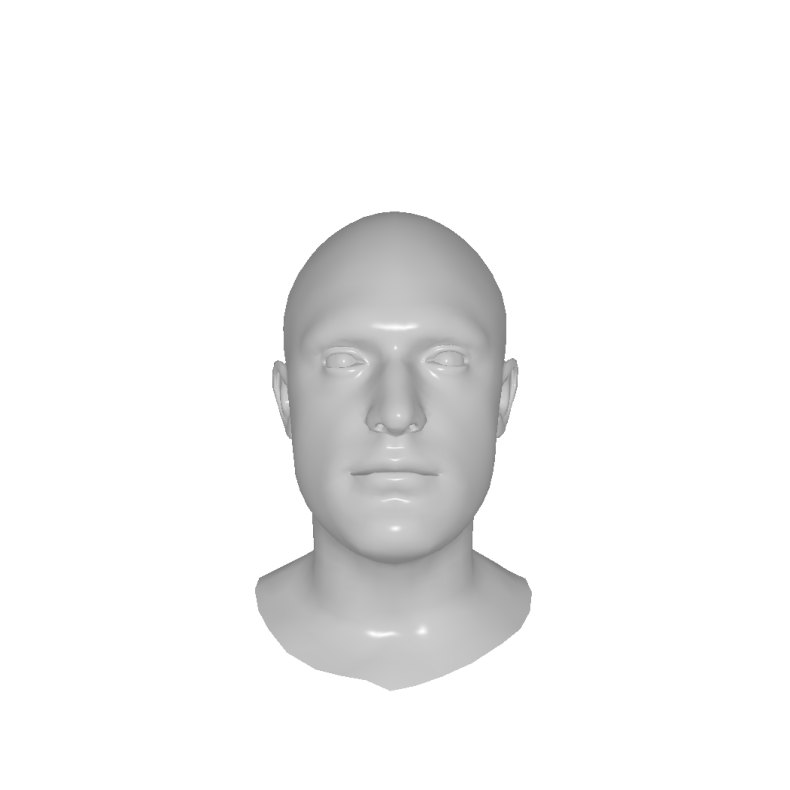

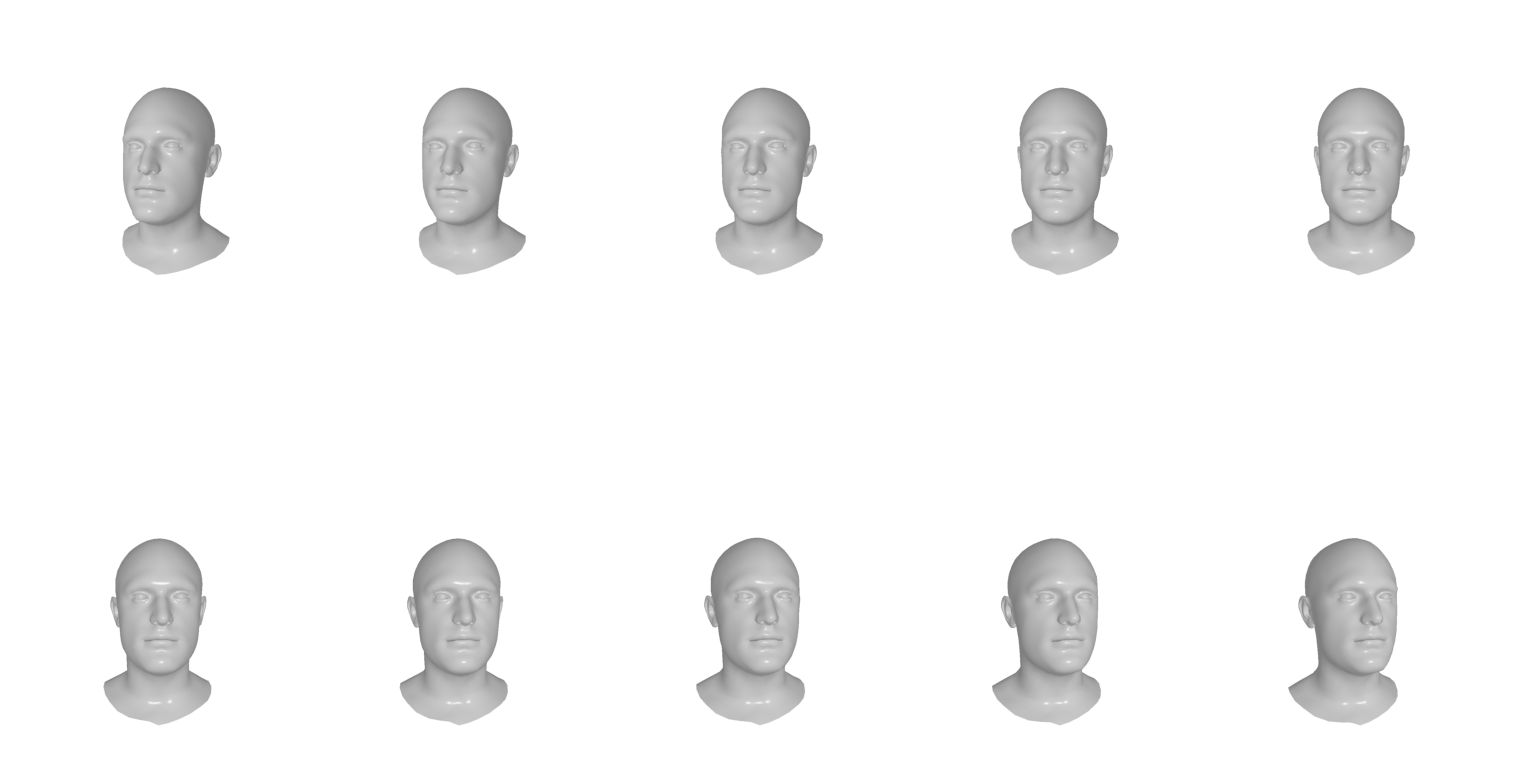

In [8]:
'''
  render mode:
    #1 prints the face only frontally,
    #2 only multiview images,
    #3 both
'''
render_mode= 3

test_renderer=NormalRenderer()
if render_mode==1 or render_mode==3:
  image_prova=test_renderer.Shot(src_mesh,0,0,2,0)
  test_renderer.Stamp()
if render_mode==2 or render_mode==3:
  images_prova=test_renderer.Multiple_Shot(src_mesh)
  test_renderer.Multiple_Stamp()

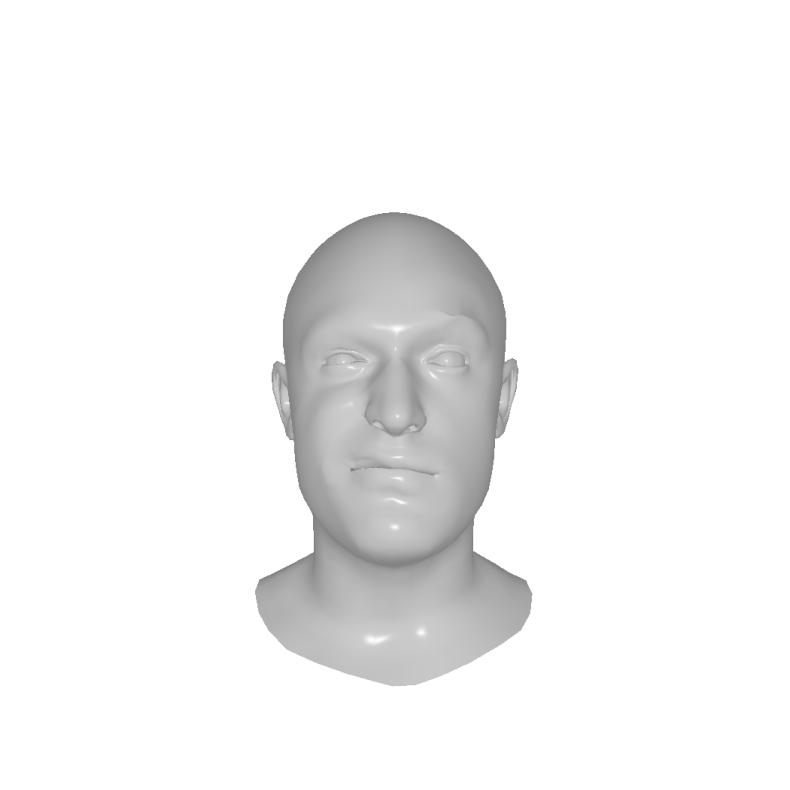

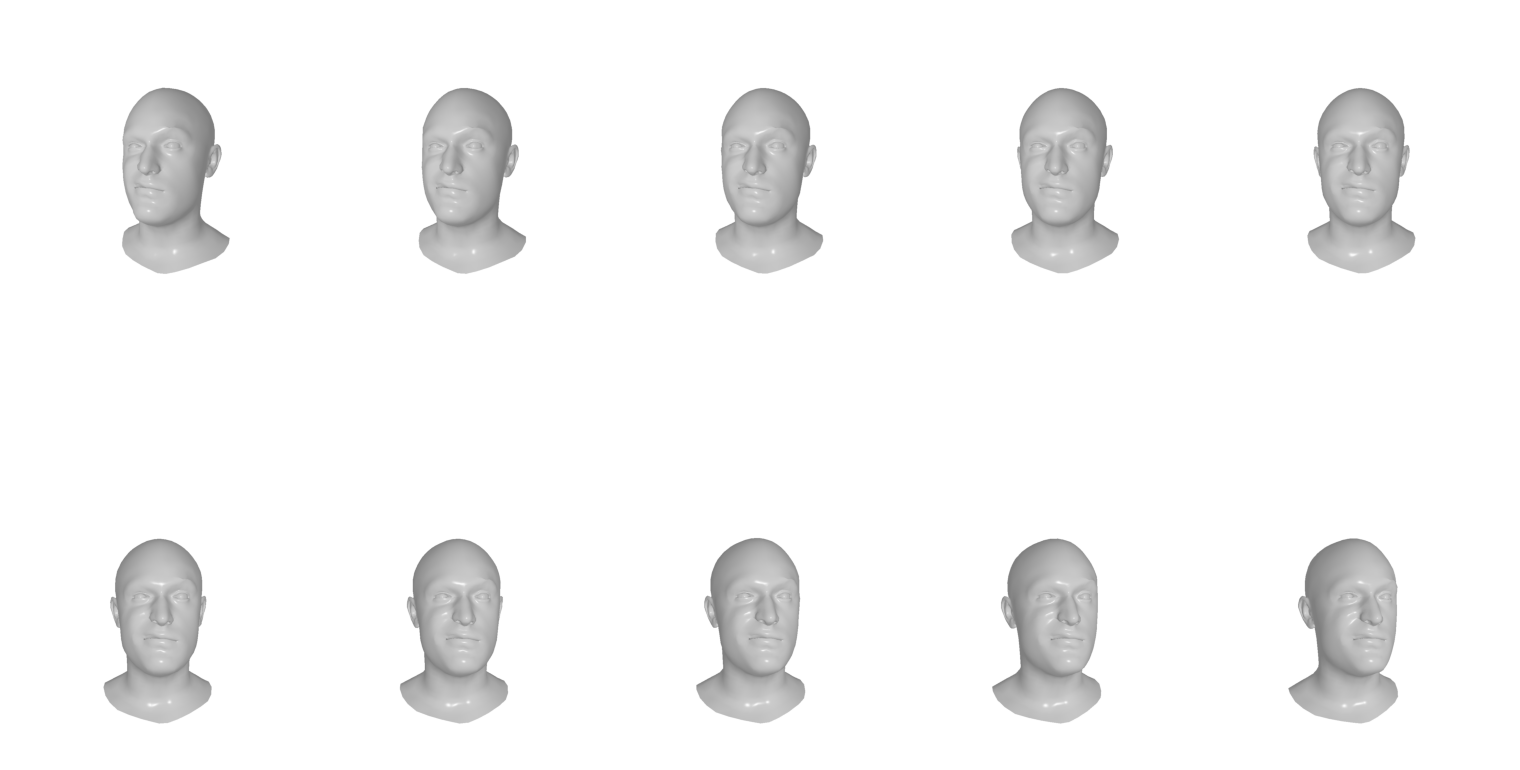

In [9]:
test_render=NormalRenderer()
if render_mode==1 or render_mode==3:
  image_prova=test_render.Shot(target_mesh,0,0,2,0)
  test_render.Stamp()
if render_mode==3 or render_mode==3:
  images_prova=test_render.Multiple_Shot(target_mesh)
  test_render.Multiple_Stamp()

#Model Definition

## compute losses

In [10]:
# @title  preprocess images
from torchvision import transforms
def preprocess_img(image, image_size=160):
    # If the input has a batch dimension, squeeze it
    if image.dim() == 4:
        image = image.squeeze(0)

    # Check the last dimension for the number of channels (should be 4 for RGBA)
    if image.shape[-1] == 4:
        image = image[:, :, :3]  # Take the first 3 channels removing alpha channel

    # Convert image from (H, W, C) to (C, H, W), this format is expected by pretrained models
    image = image.permute(2, 0, 1)

    #F.interpolate is differentiable
    image = F.interpolate(image.unsqueeze(0), size=(image_size, image_size), mode='bilinear', align_corners=False).squeeze(0)


    preprocess = transforms.Compose([
        #transforms.Resize((image_size, image_size)),  # Resize to 160x160
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    image = preprocess(image)


    image=image.unsqueeze(0)#.to(device) #Adds a batch dimension, the network expects tensor of size [1, 3, 160, 160]
    return image


### Landmark model

In [11]:
class DepthewiseSeperableConv2d(nn.Module):
    def __init__(self, input_channels, output_channels, kernel_size, **kwargs):
        super(DepthewiseSeperableConv2d, self).__init__()

        self.depthwise = nn.Conv2d(input_channels, input_channels, kernel_size, groups = input_channels, bias = False, **kwargs)
        self.pointwise = nn.Conv2d(input_channels, output_channels, 1, bias = False)

    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)

        return x

In [12]:
class EntryBlock(nn.Module):
    def __init__(self):
        super(EntryBlock, self).__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding = 1, bias = False),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2)
        )

        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding = 1, bias = False),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2)
        )

        self.conv3_residual = nn.Sequential(
            DepthewiseSeperableConv2d(64, 64, 3, padding = 1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            DepthewiseSeperableConv2d(64, 128, 3, padding = 1),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(3, stride = 2, padding = 1),
        )

        self.conv3_direct = nn.Sequential(
            nn.Conv2d(64, 128, 1, stride = 2),
            nn.BatchNorm2d(128),
        )

        self.conv4_residual = nn.Sequential(
            nn.LeakyReLU(0.2),
            DepthewiseSeperableConv2d(128, 128, 3, padding = 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            DepthewiseSeperableConv2d(128, 256, 3, padding = 1),
            nn.BatchNorm2d(256),
            nn.MaxPool2d(3, stride = 2, padding = 1)
        )

        self.conv4_direct = nn.Sequential(
            nn.Conv2d(128, 256, 1, stride = 2),
            nn.BatchNorm2d(256),
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)

        residual = self.conv3_residual(x)
        direct = self.conv3_direct(x)
        x = residual + direct

        residual = self.conv4_residual(x)
        direct = self.conv4_direct(x)
        x = residual + direct

        return x

In [13]:
class MiddleBasicBlock(nn.Module):
    def __init__(self):
        super(MiddleBasicBlock, self).__init__()

        self.conv1 = nn.Sequential(
            nn.LeakyReLU(0.2),
            DepthewiseSeperableConv2d(256, 256, 3, padding = 1),
            nn.BatchNorm2d(256)
        )
        self.conv2 = nn.Sequential(
            nn.LeakyReLU(0.2),
            DepthewiseSeperableConv2d(256, 256, 3, padding = 1),
            nn.BatchNorm2d(256)
        )
        self.conv3 = nn.Sequential(
            nn.LeakyReLU(0.2),
            DepthewiseSeperableConv2d(256, 256, 3, padding = 1),
            nn.BatchNorm2d(256)
        )

    def forward(self, x):
        residual = self.conv1(x)
        residual = self.conv2(residual)
        residual = self.conv3(residual)

        return x + residual


class MiddleBlock(nn.Module):
    def __init__(self, num_blocks):
        super().__init__()

        self.block = nn.Sequential(*[MiddleBasicBlock() for _ in range(num_blocks)])

    def forward(self, x):
        x = self.block(x)

        return x

In [14]:
class ExitBlock(nn.Module):
    def __init__(self):
        super(ExitBlock, self).__init__()

        self.residual = nn.Sequential(
            nn.LeakyReLU(0.2),
            DepthewiseSeperableConv2d(256, 256, 3, padding = 1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),
            DepthewiseSeperableConv2d(256, 512, 3, padding = 1),
            nn.BatchNorm2d(512),
            nn.MaxPool2d(3, stride = 2, padding = 1)
        )

        self.direct = nn.Sequential(
            nn.Conv2d(256, 512, 1, stride = 2),
            nn.BatchNorm2d(512)
        )

        self.conv = nn.Sequential(
            DepthewiseSeperableConv2d(512, 512, 3, padding = 1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2),
            DepthewiseSeperableConv2d(512, 1024, 3, padding = 1),
            nn.BatchNorm2d(1024),
            nn.LeakyReLU(0.2)
        )

        self.dropout = nn.Dropout(0.3)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, x):
        direct = self.direct(x)
        residual = self.residual(x)
        x = direct + residual

        x = self.conv(x)
        x = self.avgpool(x)
        x = self.dropout(x)

        return x

In [15]:
class XceptionNet(nn.Module):
    def __init__(self, num_middle_blocks = 6):
        super(XceptionNet, self).__init__()

        self.entry_block = EntryBlock()
        self.middel_block = MiddleBlock(num_middle_blocks)
        self.exit_block = ExitBlock()

        self.fc = nn.Linear(1024, 136)

    def forward(self, x):
        x = self.entry_block(x)
        x = self.middel_block(x)
        x = self.exit_block(x)

        x = x.view(x.size(0), -1)

        x = self.fc(x)

        return x

####extractor of landmark

In [16]:
def preprocess_image(image):
    image=image.unsqueeze(0)
    resize_transform = Resize((128, 128))
    image=resize_transform(image)
    image = (image - image.min())/(image.max() - image.min())
    image = (2 * image) - 1
    return image.unsqueeze(0)


def draw_landmarks_on_faces(image, faces_landmarks,src_image):
  #this functions draws small circles in correspondence of landmarks of rendered meshes.
  image_copy=np.ascontiguousarray(copy.deepcopy(src_image), dtype=np.uint8)     #creates a copy of the source image in order not to execute operation on the original rendered images

  for landmarks, (left, top, height, width) in faces_landmarks:
      landmarks = landmarks.view(-1, 2)
      landmarks = (landmarks + 0.5)
      landmarks = landmarks.numpy()
      for i, (x, y) in enumerate(landmarks, 1):
          try:
            if i != 30:
              cv2.circle(image_copy, (int((x * width) + left), int((y * height) + top)), 2, [255, 0, 0], -1)
            else:
              # Drawing a different circle for the 30th landmark, correspondent to central landmark of noise
              cv2.circle(image_copy, (int((x * width) + left), int((y * height) + top)), 2, [255, 0, 0], -1)
          except Exception as e:
              print(f"Errore: {e}")
              pass

  return image_copy


def inference(frame,for_faces):
    weights = torch.tensor([0.2989, 0.5870, 0.1140])
    weights = weights.to(frame.device)
    gray = torch.tensordot(frame, weights, dims=1)
    gray_for_faces = cv2.cvtColor(for_faces, cv2.COLOR_RGB2GRAY)
    faces = face_detector(gray_for_faces, 1)
    outputs = []

    for (i, face) in enumerate(faces):
        (x, y, w, h) = face_utils.rect_to_bb(face)
        crop_img = gray[y: y + h, x: x + w]
        preprocessed_image = preprocess_image(crop_img)
        landmarks_predictions = landmark_model(preprocessed_image.cuda())
        outputs.append((landmarks_predictions.cpu(), (x, y, h, w)))
    return draw_landmarks_on_faces(frame, outputs,for_faces)

weights_gray = torch.tensor([0.2989, 0.5870, 0.1140], device=device)

def compute_landmarks(single_image):
  single_image_rgb = single_image[:, :, :3]              #removing alpha channel

  img_tensor_prova= (single_image_rgb* 255).to(torch.uint8).detach()
  gray = torch.tensordot(single_image_rgb, weights_gray, dims=1)

  for_faces=np.array(copy.deepcopy(img_tensor_prova).cpu().detach())
  gray_for_faces = cv2.cvtColor(for_faces, cv2.COLOR_RGB2GRAY)
  faces = face_detector(gray_for_faces, 1)

  if len(faces)==0:
    return torch.zeros((42, 2), device=single_image_rgb.device)

  for (i, face) in enumerate(faces):
    (x, y, w, h) = face_utils.rect_to_bb(face)
    crop_img = gray[y: y + h, x: x + w]
    preprocessed_image = preprocess_image(crop_img)
    landmarks = landmark_model(preprocessed_image.cuda())
    landmarks = landmarks.view(-1, 2)
    landmarks = landmarks + 0.5
    landmarks = landmarks[17:]
    landmarks = torch.cat((landmarks[:10], landmarks[19:]), dim=0)
    landmarks[:, 0] = (landmarks[:, 0] * w) + x
    landmarks[:, 1] = (landmarks[:, 1] * h) + y

  return landmarks

def is_there_faces(single_image):
  #this function
  single_image_rgb = single_image[:, :, :3]              #removing alpha channel

  img_tensor_prova= (single_image_rgb* 255).to(torch.uint8).detach()
  gray = torch.tensordot(single_image_rgb, weights_gray, dims=1)

  for_faces=np.array(copy.deepcopy(img_tensor_prova).cpu().detach())
  gray_for_faces = cv2.cvtColor(for_faces, cv2.COLOR_RGB2GRAY)
  faces = face_detector(gray_for_faces, 1)

  if len(faces)==0:
    return False
  else:
    return True

In [17]:
def landmarks_given_image(single_image):

    image_rgb = single_image[:, :, :3]
    img_tensor = (image_rgb * 255).to(torch.uint8)
    image_copy = np.array(copy.deepcopy(img_tensor).cpu().detach())
    fig = plt.figure(figsize=(9, 9))

    # Perform inference on the image using the provided inference function
    output = inference(image_rgb.detach(), image_copy)

    # Display the original image and the inference result
    plt.figure(figsize=(11, 11))
    plt.imshow(image_copy)  # Show the original image copy
    plt.imshow(output)      # Overlay the inference result

    return

In [18]:
landmark_model = XceptionNet()
landmark_model.cuda()
landmark_model.load_state_dict(torch.load('landmarkmodel.pt'))
landmark_model.eval()
for param in landmark_model.parameters():
    param.requires_grad = False
face_cascade = cv2.CascadeClassifier(
    "haarcascade_frontalface_default.xml"
)

### Features extractor model

In [19]:
vgg16_extractor = models.vgg16(pretrained=True).features
vgg16_extractor.eval().to(device)

#freeze the weights of the pretrained model
for param in vgg16_extractor.parameters():
    param.requires_grad = False

first_block_vgg16_extractor=vgg16_extractor[:4]
second_block_vgg16_extractor=vgg16_extractor[4:9]
third_block_vgg16_extractor=vgg16_extractor[9:16]
fourth_block_vgg16_extractor=vgg16_extractor[16:23]

fifth_block_vgg16_extractor=vgg16_extractor[23:30]                              #fifth block is not usually employed, we will not use it.

transform_vgg = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]), #necessary for imagenet dataset
])

def get_features_maps(image):
  #image must be torch.Size([1, 3, 224, 224])
  image=preprocess_img(image,224)
  first_output=first_block_vgg16_extractor(image)
  second_output=second_block_vgg16_extractor(first_output)
  third_output=third_block_vgg16_extractor(second_output)
  fourth_output=fourth_block_vgg16_extractor(third_output)
  #fifth_output=fifth_block_vgg16_extractor(fourth_output)
  return [first_output, second_output, third_output, fourth_output] # fifth_output

def loss_feature_maps(features1,features2):
  return nn.MSELoss()(features1, features2)

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
100%|██████████| 528M/528M [00:03<00:00, 152MB/s]


### Loss functions

In [20]:
def pairwise_distances(landmarks):
    # Using broadcasting to compute pairwise distances
    diff = landmarks.unsqueeze(1) - landmarks.unsqueeze(0)  # Shape: (42, 42, 2)
    pairwise_distances = torch.norm(diff, dim=2)  # Shape: (42, 42), Euclidean distance along the last dimension

    return pairwise_distances

In [21]:
def compute_sparsity_loss(mask, threshold=1e-3):
    # Count the number of elements in the mask above the threshold
    non_sparse_elements = torch.sum(mask > threshold).float()

    # Normalize by the total number of elements in the mask to get the proportion of non-sparse elements
    sparsity_loss = non_sparse_elements / mask.numel()

    return sparsity_loss

In [22]:
def compute_perceptual_loss(source_features,target_featues, w1=1,w2=1,w3=1,w4=1):
  src_features1, src_features2, src_features3, src_features4=source_features
  target_features1, target_features2, target_features3, target_features4=target_featues
  if source_features is not None and target_featues is not None:
    loss_feature_1=loss_feature_maps(src_features1,target_features1)
    loss_feature_2=loss_feature_maps(src_features2,target_features2)
    loss_feature_3=loss_feature_maps(src_features3,target_features3)
    loss_feature_4=loss_feature_maps(src_features4,target_features4)
    return w1*loss_feature_1+w2*loss_feature_2+w3*loss_feature_3+w4*loss_feature_4
  else: return torch.tensor(0.0, device=device)

In [23]:
def compute_losses(mesh, deformations, rendered_image, target_image, target_landmarks, target_features, mask, w_reg=0, w_spars=0, w_edge=0, w_laplacian=0, w_normal=0, w_landmarks=0, w_landmarks_relative=0, w_perceptual=0, w_mse=0):

    #MSE LOSS
    mse_loss = nn.MSELoss()(rendered_image, target_image)

    #encourage small deformations
    reg_loss = torch.mean(deformations.norm(dim=1)) if w_reg != 0 else torch.tensor(0.0, device=device)

    #encourage mask sparsity (for implementations of networks requiring mask)
    mask_sparsity_loss = torch.mean(mask) if mask is not None  and w_spars != 0 else torch.tensor(0.0, device=device)

    #discourage edges with length far from the average
    edge_loss = mesh_edge_loss(mesh) if w_edge != 0 else torch.tensor(0.0, device=device)

    #discourage variations in the vertex positions relative to their neighbors
    laplacian_loss = mesh_laplacian_smoothing(mesh, method="uniform") if w_laplacian != 0 else torch.tensor(0.0, device=device)

    #discourage changes in the orientation with respect to surface normal.
    loss_normal = mesh_normal_consistency(mesh) if w_normal != 0 else torch.tensor(0.0, device=device)

    #LANDMARKS LOSS
    if w_landmarks != 0 or w_landmarks_relative != 0:
        input_landmarks = compute_landmarks(rendered_image)


        #DISTANCE AMONG LANDMARKS
        if w_landmarks != 0:
            distances = torch.norm(input_landmarks - target_landmarks, dim=1)
            landmark_loss = torch.mean(distances)
        else:
            landmark_loss = torch.tensor(0.0, device=device)

        #PAIRWISE RELATIVE DISTANCE BETWEEN LANDMARKS
        if w_landmarks_relative != 0:
            input_pairwise_distances = pairwise_distances(input_landmarks)
            target_pairwise_distances = pairwise_distances(target_landmarks)
            landmark_relative_loss = torch.mean(torch.abs(input_pairwise_distances - target_pairwise_distances))
        else:
            landmark_relative_loss = torch.tensor(0.0, device=device)
    else:
        landmark_loss = torch.tensor(0.0, device=device)
        landmark_relative_loss = torch.tensor(0.0, device=device)

    #PERCEPTUAL LOSS
    if w_perceptual != 0:
      source_features = get_features_maps(rendered_image)
      perceptual_loss = compute_perceptual_loss(source_features, target_features)
    else:
      perceptual_loss = torch.tensor(0.0, device=device)

    #TOTAL_MESH_LOSS
    total_mesh_loss = (w_reg * reg_loss +
                       w_spars * mask_sparsity_loss +
                       w_landmarks * landmark_loss +
                       w_landmarks_relative * landmark_relative_loss+
                       w_edge * edge_loss +
                       w_laplacian * laplacian_loss +
                       w_normal * loss_normal+
                       w_perceptual*perceptual_loss+
                       w_mse*mse_loss)


    # Return the total mesh-dependent loss and individual components for tracking
    return total_mesh_loss, np.array([
      mse_loss.detach().cpu(),
      perceptual_loss.detach().cpu(),
      landmark_loss.detach().cpu(),
      landmark_relative_loss.detach().cpu(),
      reg_loss.detach().cpu(),
      mask_sparsity_loss.detach().cpu(),
      edge_loss.detach().cpu(),
      laplacian_loss.detach().cpu(),
      loss_normal.detach().cpu(),
      ])

##NETWORK SECTION

In [24]:
#@title Neural stile field network

class ProgressiveEncoding(nn.Module):
    def __init__(self, mapping_size, T, d=3, apply=True):
        super(ProgressiveEncoding, self).__init__()
        self._t = nn.Parameter(
            torch.tensor(0, dtype=torch.float32, device=device), requires_grad=False
        )
        self.n = mapping_size
        self.T = T
        self.d = d
        self._tau = 2 * self.n / self.T
        self.indices = torch.tensor([i for i in range(self.n)], device=device)
        self.apply = apply
    def forward(self, x):
        alpha = ((self._t - self._tau * self.indices) / self._tau).clamp(0, 1).repeat(
            2)  # no need to reduce d or to check cases
        if not self.apply:
            alpha = torch.ones_like(alpha, device=device)  ## this layer means pure ffn without progress.
        alpha = torch.cat([torch.ones(self.d, device=device), alpha], dim=0)
        self._t += 1
        return x * alpha

class FourierFeatureTransform(nn.Module):
    """
    An implementation of Gaussian Fourier feature mapping.
    "Fourier Features Let Networks Learn High Frequency Functions in Low Dimensional Domains":
       https://arxiv.org/abs/2006.10739
       https://people.eecs.berkeley.edu/~bmild/fourfeat/index.html
    Given an input of size [batches, num_input_channels, width, height],
     returns a tensor of size [batches, mapping_size*2, width, height].
    """

    def __init__(self, num_input_channels, mapping_size=256, scale=10, exclude=0):
        super().__init__()

        self._num_input_channels = num_input_channels
        self._mapping_size = mapping_size
        self.exclude = exclude
        B = torch.randn((num_input_channels, mapping_size)) * scale
        B_sort = sorted(B, key=lambda x: torch.norm(x, p=2))
        self._B = nn.Parameter(torch.stack(B_sort), requires_grad=False)  # for sape

    def forward(self, x):
        # assert x.dim() == 4, 'Expected 4D input (got {}D input)'.format(x.dim())

        batches, channels = x.shape

        assert channels == self._num_input_channels, \
            "Expected input to have {} channels (got {} channels)".format(self._num_input_channels, channels)

        # Make shape compatible for matmul with _B.
        # From [B, C, W, H] to [(B*W*H), C].
        # x = x.permute(0, 2, 3, 1).reshape(batches * width * height, channels)

        res = x @ self._B.to(x.device)

        # From [(B*W*H), C] to [B, W, H, C]
        # x = x.view(batches, width, height, self._mapping_size)
        # From [B, W, H, C] to [B, C, W, H]
        # x = x.permute(0, 3, 1, 2)

        res = 2 * np.pi * res
        return torch.cat([x, torch.sin(res), torch.cos(res)], dim=1)

class NeuralStyleField(nn.Module):
    # Same base then split into two separate modules
    def __init__(self, sigma, depth, width, encoding, normdepth=2, normratio=0.1,
                 normclamp=None,niter=6000, input_dim=3, exclude=0,progressive_encoding=True):
        super(NeuralStyleField, self).__init__()
        self.pe = ProgressiveEncoding(mapping_size=width, T=niter, d=input_dim)
        self.normclamp = normclamp
        self.normratio = normratio
        layers = []
        if encoding == 'gaussian':
            layers.append(FourierFeatureTransform(input_dim, width, sigma, exclude))
            if progressive_encoding:
                layers.append(self.pe)
            layers.append(nn.Linear(width * 2 + input_dim, width))
            layers.append(nn.ReLU())
        else:
            layers.append(nn.Linear(input_dim, width))
            layers.append(nn.ReLU())
        for i in range(depth):
            layers.append(nn.Linear(width, width))
            layers.append(nn.ReLU())
        self.base = nn.ModuleList(layers)

        # Branches

        normal_layers = []
        for _ in range(normdepth):
            normal_layers.append(nn.Linear(width, width))
            normal_layers.append(nn.ReLU())
        normal_layers.append(nn.Linear(width, 1))
        self.mlp_normal = nn.ModuleList(normal_layers)
        self.reset_displacement_weights()

        # print(self.base)
        # print(self.mlp_normal)

    def reset_displacement_weights(self):
        self.mlp_normal[-1].weight.data.zero_()
        self.mlp_normal[-1].bias.data.zero_()

    def initialize_weights(self):
        # Initialize the network layers
        for layer in self.base:
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
                layer.bias.data.zero_()
        for layer in self.mlp_normal:
            if isinstance(layer, nn.Linear) and layer.weight.shape[0] > 1:
                nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
                layer.bias.data.zero_()

    def forward(self, x):
        for layer in self.base:
            x = layer(x)
        displ = self.mlp_normal[0](x)
        for layer in self.mlp_normal[1:]:
            displ = layer(displ)
        if self.normclamp == "tanh":
            displ = F.tanh(displ) * self.normratio
        elif self.normclamp == "clamp":
            displ = torch.clamp(displ, -self.normratio, self.normratio)

        return displ, None

    def display_layers(self):
        print(self.base)
        print(self.mlp_normal)

In [25]:
#@title Simple Network
class SimpleNetwork(nn.Module):
    def __init__(self, num_vertices, width=256, depth=4, enable_mask=False, num_freqs=0, out=1):

        super(SimpleNetwork, self).__init__()
        self.enable_mask=enable_mask
        self.num_freqs = num_freqs
        self.out=out

        input_dim = 3 * num_vertices                                            # Input dimension is 3 times the number of vertices

        output_dim = self.out * num_vertices


        input_layer= nn.Linear(input_dim, width)                                #input layer

        layers = []
        layers.append(input_layer)
        layers.append(nn.ReLU())

        for i in range(depth):
            layers.append(nn.Linear(width, width))                              #hidden layers
            layers.append(nn.ReLU())


        #definition of the network
        self.network = nn.Sequential(*layers)                                   #using sequential should be faster in this simple example

        '''
        self.input_layer = nn.Linear(input_dim, width)

        self.hidden_layers = nn.ModuleList()
        for i in range(depth):
            self.layers.append(nn.Linear(width, width))
            self.layers.append(nn.ReLU())
        '''

        #output layers
        self.displacement_layer = nn.Linear(width, output_dim)                  # Layer that outputs displacements
        self.mask_layer = nn.Linear(width, num_vertices)                        # Layer that outputs mask (one hot encoding: one for number of vertices)

        self.initialize_weights()                                                    # Call Reset weights
        self.reset_displacement_weights()


    def reset_displacement_weights(self):
        self.displacement_layer.weight.data.zero_()
        self.displacement_layer.bias.data.zero_()


    def initialize_weights(self):

        # Initialize the weights of the network
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
                layer.bias.data.zero_()

        '''
        # Initialize the weights of the input layer
        nn.init.kaiming_normal_(self.input_layer.weight, nonlinearity='relu')
        self.input_layer.bias.data.zero_()

        # Initialize the weights of the hidden layers
        for layer in self.hidden_layers:
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
                layer.bias.data.zero_()
        '''

        nn.init.xavier_normal_(self.mask_layer.weight)
        self.mask_layer.bias.data.zero_()


    def forward(self, input):
        # Flatten the input vertices inside the network
        flattened_input = input.view(1, -1)                                     # Flatten to shape [1, num_vertices * 3]


        features = self.network(flattened_input)

        '''
        x = F.relu(self.input_layer(flattened_input))

        for layer in self.hidden_layers:
            x = layer(x)

        features = x
        '''

        #Compute displacement
        displacements = self.displacement_layer(features)                       # Pass through the displacement layer
        displacements = displacements.view(-1, self.out)                        # Reshape to [num_vertices, out]

        #Compute mask
        if self.enable_mask:
            mask_logits = self.mask_layer(features)                             # Pass through the mask layer
            mask = torch.sigmoid(mask_logits)                                   # Apply sigmoid
            mask = mask.view(-1, 1)                                             # Reshape to [num_vertices, 1] for each vertex the mask is broadcasted into all the 3 dimensions
            filtered_displacements = displacements * mask                       # Apply the mask to the displacements
            return filtered_displacements, mask
        else:
            return displacements, None

    def display_layers(self):
        print(self.network)
        print(self.displacement_layer)

In [26]:
#@title Residual Network
class residualNetwork(nn.Module):
    def __init__(self, num_vertices, width=256, depth=4,enable_mask=False, out=1, num_freqs=0):
      super(residualNetwork, self).__init__()
      input_dim = 3 * num_vertices                                              # Input dimension: 3 times the number of vertices (x,y,z) coordinates of the vertices
      self.out=out
      output_dim = self.out * num_vertices

      self.enable_mask = enable_mask
      self.num_freqs = num_freqs

      self.input_layer = nn.Linear(input_dim, width)

      self.hidden_layers = nn.ModuleList()                                      # Hidden layers
      for i in range(depth):
          self.hidden_layers.append(nn.Linear(width, width))

      self.displacement_layer = nn.Linear(width, output_dim)                    # Layer that outputs displacements
      self.mask_layer = nn.Linear(width, num_vertices)                          # Layer that outputs mask (one hot encoding: one for number of vertices)

      self.initialize_weights()                                                 # Call Reset weights
      self.reset_displacement_weights()

    def reset_displacement_weights(self):
        self.displacement_layer.weight.data.zero_()
        self.displacement_layer.bias.data.zero_()


    def initialize_weights(self):

        # Initialize the weights of the network
        for layer in self.hidden_layers:
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
                layer.bias.data.zero_()


        # Initialize the weights of the input layer
        nn.init.kaiming_normal_(self.input_layer.weight, nonlinearity='relu')
        self.input_layer.bias.data.zero_()


        nn.init.xavier_normal_(self.mask_layer.weight)
        self.mask_layer.bias.data.zero_()                                       #Initialize bias for mask layer


    def forward(self, input):

        flattened_input = input.view(1, -1)                                     # Flatten to shape [1, num_vertices * 3] to fill into the network


        # Normalize input vertices
        normalized_input = F.normalize(flattened_input, p=2, dim=1)             # L2 normalization
        #Input Layer
        features = F.relu(self.input_layer(normalized_input))                   # Pass through the input layer

        # Pass through hidden layers with residual connections
        for layer in self.hidden_layers:
            residual = features                                                 # Store the residual
            features = F.relu(layer(features))
            features = features + residual                                      # Add the residual (skip connection)

        #Compute displacement
        displacements = self.displacement_layer(features)                       # Pass through the displacement layer

        displacements = displacements.view(-1, self.out)                        # Reshape to [num_vertices, out]

        #Compute mask
        if self.enable_mask:
            mask_logits = self.mask_layer(features)                              # Pass through the mask layer
            mask = torch.sigmoid(mask_logits)                                    # Apply sigmoid
            mask = mask.view(-1, 1)                                             # Reshape to [num_vertices, 1] for each vertex the mask is broadcasted into all the 3 dimensions
            filtered_displacements = displacements * mask                         # Apply the mask to the displacements
            return filtered_displacements, mask
        else:
            return displacements, None
    def display_layers(self):
        print(self.input_layer)
        print(self.hidden_layers)
        print(self.displacement_layer)

In [27]:
#@title GraphCNNetwork


def get_edge_index(mesh):

    src_faces = mesh.faces_packed()  # Shape: [num_faces, 3]

    # Create edges from the faces
    edge_index = torch.cat([
        faces[:, [0, 1]],
        faces[:, [1, 2]],
        faces[:, [2, 0]]
    ], dim=0).t().contiguous()  # Shape: [2, num_edges]
    #this is the shape required for adjacency matrix, according to pytorch geometric

    # Remove duplicate edges
    edge_index = torch.unique(edge_index, dim=1)

    return edge_index




class MeshGraphNetwork(nn.Module):
    def __init__(self, num_vertices, hidden_channels=128, num_hidden_layers=4, output_dim=1, enable_mask=False):
        super(MeshGraphNetwork, self).__init__()

        self.num_vertices = num_vertices

        self.output_dim = 1 if output_dim != 3 else output_dim                  #only 1 or 3 are suitable output dimensions
        self.enable_mask = enable_mask


        # Define the GCN layers
        self.convolutions = nn.ModuleList()
        self.convolutions.append(GCNConv(3, hidden_channels))                   #Input layer
        for i in range(num_hidden_layers ):
            self.convolutions.append(GCNConv(hidden_channels, hidden_channels))
        self.convolutions.append(GCNConv(hidden_channels, self.output_dim))     # Output layer returns a deformation


        # Define the mask layer
        self.mask_layer = nn.Linear(hidden_channels, 1)
        self.initialize_weights()
        self.reset_displacement_weights()


    def reset_displacement_weights(self):
            self.convolutions[-1].lin.weight.data.zero_()
            if self.convolutions[-1].lin.bias is not None:
                self.convolutions[-1].lin.bias.data.zero_()

    def initialize_weights(self):
            for conv in self.convolutions:
                if isinstance(conv, GCNConv):
                    nn.init.kaiming_normal_(conv.lin.weight, nonlinearity='relu')  # Apply kaiming initialization to GCN layers
                    if conv.lin.bias is not None:
                        conv.lin.bias.data.zero_()

            nn.init.xavier_normal_(self.mask_layer.weight)                      # Xavier initialization for mask layer
            self.mask_layer.bias.data.zero_()


    def forward(self, x, edge_index):

        for conv in self.convolutions[:-1]:
            x = F.relu(conv(x, edge_index))

        # Compute deformations
        deformations = self.convolutions[-1](x, edge_index)                     # Shape: [num_vertices, 3]

        if self.enable_mask:

          # Compute mask
          mask= self.mask_layer(x)                                              # Shape: [num_vertices, 1]
          mask = torch.sigmoid(mask)

          # Apply mask to deformations
          deformations = deformations * mask
        else:
          mask=None

        return deformations, mask

    def display_layers(self):
        print("Not implemented")

In [28]:
#@title simple Network: single vertex processing

class SimpleNetwork_single_vertex(nn.Module):
    def __init__(self, width=256, depth=4, enable_mask=False, num_freqs=0,out=1):
        super(SimpleNetwork_single_vertex, self).__init__()
        self.enable_mask = enable_mask
        self.num_freqs = num_freqs

        input_dim = 3
        self.out=out
        output_dim = self.out

        if self.num_freqs != 0:

            input_layer = nn.Linear(input_dim, width)  # Input layer
        else:
            input_layer = nn.Linear(input_dim, width)  # Input layer

        layers = []
        layers.append(input_layer)
        layers.append(nn.ReLU())

        for i in range(depth):
            layers.append(nn.Linear(width, width))  # Hidden layers
            layers.append(nn.ReLU())

        # Definition of the network
        self.network = nn.Sequential(*layers)

        # Output layers
        self.displacement_layer = nn.Linear(width, output_dim)  # Layer that outputs displacements

        if self.enable_mask:
            self.mask_layer = nn.Linear(width, output_dim)  # Layer that outputs mask
        self.initialize_weights()                                                    # Call Reset weights
        self.reset_displacement_weights()


    def reset_displacement_weights(self):
        self.displacement_layer.weight.data.zero_()
        self.displacement_layer.bias.data.zero_()


    def initialize_weights(self):
        # Initialize the network layers
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
                layer.bias.data.zero_()

        # Initialize output layers

        if self.enable_mask:
            nn.init.xavier_normal_(self.mask_layer.weight, nonlinearity='relu')
            self.mask_layer.bias.data.zero_()

    def forward(self, x):
        x = self.network(x)

        displacements = self.displacement_layer(x)

        # Compute mask if enabled
        if self.enable_mask:
            mask_logits = self.mask_layer(x)  # Pass through the mask layer
            mask = torch.sigmoid(mask_logits)  # Apply sigmoid
            filtered_displacements = displacements * mask  # Apply the mask to the displacements
            return filtered_displacements, mask
        else:
            return displacements, None

    def display_layers(self):
        print(self.network)
        print(self.displacement_layer)

## Trainers

In [29]:
def train(src_mesh=src_mesh,Niter=200, wd=1e-5, lr=1e-4,resize=True, network=None,  w_mse=0, w_reg=0, w_spars=0, w_landmarks=0, w_landmarks_relative=0, w_perceptual=0, w_edge=0, w_laplacian=0, w_normal=0):

    # Initialize weights
    network.initialize_weights()

    # Put weights of the last linear layer to compute displacement to 0
    network.reset_displacement_weights()
    optimizer = torch.optim.Adam(network.parameters(), lr, weight_decay=wd)

    # Initialize renderer
    renderer = NormalRenderer()

    #Target features and Landmark
    target_image=renderer.Shot(target_mesh,angle=0.0,x=0.0,y=2.0,z=0.0).squeeze(0)
    target_features=get_features_maps(target_image)
    target_landmarks = compute_landmarks(target_image)

    # Compute the parameters for centering and resizing
    center_mesh, scale_mesh = compute_center_and_scale(src_mesh)
    edge_index = get_edge_index(src_mesh).to(device)

    deformed_meshes = []
    losses = []
    single_losses=[]

    # Boolean flag for graph neural network
    requires_edge_index = isinstance(network, MeshGraphNetwork)

    loop = tqdm(range(Niter))

    for i in loop:
        optimizer.zero_grad()

        vertex_positions = src_mesh.verts_packed()

        # Deform the mesh using the vertex positions as input
        if not requires_edge_index:
          deformations,mask = network(vertex_positions)                          # Mask is an optional argument, could be also None
        else:
          deformations, mask = network(vertex_positions, edge_index)             # Version for graph nerual networks


        if deformations.shape == torch.Size([5023, 1]):
          new_src_mesh = src_mesh.offset_verts(src_mesh.verts_normals_packed()*deformations)

        else:                                                                   # Apply the deformations to the mesh if deformations.shape == torch.Size([5023, 3])
          new_src_mesh = src_mesh.offset_verts(deformations)

        if resize==1:
          new_src_mesh = normalize_mesh(new_src_mesh, center_mesh, scale_mesh)

        #rendered new image
        rendered_single_image=renderer.Shot(new_src_mesh,angle=0.0,x=0.0,y=2.0,z=0.0).squeeze(0)

        # If no faces detected we reset the weights of the last linear layer
        if not is_there_faces(rendered_single_image):
          network.reset_displacement_weights()
          #print("No faces detected. Resetting the displacement")
          deformed_meshes.append(deformed_meshes[-1].clone())
          losses.append(losses[-1])
          single_losses.append(single_losses[-1])
          continue

        # Visualize intermediate results
        if i % (max(1,Niter//5)) == 0:
            renderer.Shot(new_src_mesh, 0, 0, 2, 0)
            renderer.Stamp()

        #compute the loss
        total_loss, mesh_losses = compute_losses(new_src_mesh, deformations, rendered_single_image,target_image, target_landmarks,target_features, mask,
                                                 w_reg=w_reg, w_spars=w_spars,w_edge=w_edge, w_laplacian=w_laplacian, w_normal=w_normal,
                                                     w_landmarks=w_landmarks,w_landmarks_relative=w_landmarks_relative, w_perceptual=w_perceptual,w_mse=w_mse)

        single_losses.append(mesh_losses.tolist())

        # Optimization step
        total_loss.backward()
        optimizer.step()

        # Save the losses
        losses.append(float(total_loss.detach().cpu()))
        loop.set_description(f'total_loss = {total_loss.item():.6f}')

        #append the meshes:
        deformed_meshes.append(new_src_mesh.detach())

    return losses, deformed_meshes, single_losses

In [30]:
def train_py3D(src_mesh=src_mesh,Niter=200, wd=1e-5, lr=1e-4,resize=True, network=None,  w_mse=0, w_reg=0, w_spars=0, w_mask_count=0, w_features=0, w_landmarks=0, w_landmarks_relative=0, w_perceptual=0, w_edge=0, w_laplacian=0, w_normal=0):

    deformations = torch.full([5023, 1], 0.0, device=device, requires_grad=True)
    optimizer = torch.optim.Adam([deformations], lr, weight_decay=wd)

    # Initialize Renderer
    renderer = NormalRenderer()
    target_image=renderer.Shot(target_mesh,angle=0.0,x=0.0,y=2.0,z=0.0).squeeze(0)
    target_features=get_features_maps(target_image)
    target_landmarks = compute_landmarks(target_image)

    center_mesh, scale_mesh = compute_center_and_scale(src_mesh)

    deformed_meshes = []
    losses = []
    single_losses=[]

    loop = tqdm(range(Niter))
    mask=None
    for i in loop:
        optimizer.zero_grad()

        new_src_mesh = src_mesh.offset_verts(src_mesh.verts_normals_packed()*deformations)

        if resize==1:
          new_src_mesh = normalize_mesh(new_src_mesh, center_mesh, scale_mesh)


        #single_image_renderer= NormalRenderer()
        rendered_single_image=renderer.Shot(new_src_mesh,angle=0.0,x=0.0,y=2.0,z=0.0).squeeze(0)

        if not is_there_faces(rendered_single_image):
          deformed_meshes.append(deformed_meshes[-1].clone())
          losses.append(losses[-1])
          single_losses.append(single_losses[-1])
          print("No faces detected. Blocking the cicle")
          break

        # Visualize intermediate results
        if i % (max(1,Niter//5)) == 0:
            renderer.Shot(new_src_mesh, 0, 0, 2, 0)
            renderer.Stamp()

        #compute the loss
        total_loss, mesh_losses = compute_losses(new_src_mesh, deformations, rendered_single_image,target_image, target_landmarks,target_features, mask,
                                                 w_reg=w_reg, w_spars=w_spars,w_edge=w_edge, w_laplacian=w_laplacian, w_normal=w_normal,
                                                     w_landmarks=w_landmarks,w_landmarks_relative=w_landmarks_relative, w_perceptual=w_perceptual,w_mse=w_mse)

        single_losses.append(mesh_losses.tolist())

        # Optimization step
        total_loss.backward()
        optimizer.step()

        # Save the losses
        losses.append(float(total_loss.detach().cpu()))
        loop.set_description(f'total_loss = {total_loss.item():.6f}')

        #append the meshes:
        deformed_meshes.append(new_src_mesh.detach())

    return losses, deformed_meshes, single_losses

## Saving and evaluation

In [31]:
#@title Mount drive
MOUNT_DRIVE=False
if MOUNT_DRIVE==True:
  from google.colab import drive
  drive.mount('/content/drive')
  drive_path='/content/drive/MyDrive/pytorch_3D'
  if not os.path.exists(drive_path):
      os.makedirs(drive_path)
  path=drive_path
else:
  path='.'

In [32]:
#@title Evaluation metrics
def evaluation_metrics(sample_src, sample_trg,points):
      # compute pairwise distances
      dists1, _ = torch.cdist(sample_src,sample_trg ).min(dim=-1)
      dists2, _ = torch.cdist(sample_trg, sample_src).min(dim=-1)

      #chamfer distance
      chamfer_distance= torch.mean(dists1) + torch.mean(dists2) #chamfer_distance(sample_trg, sample_src)

      #hausdorff distance
      hausdorff_distance= torch.max(torch.max(dists1), torch.max(dists2))

      #frobenius distance
      frobenius_distance= torch.mean(torch.norm(sample_src - sample_trg, p='fro', dim=-1))

      sample_src = sample_src.detach().squeeze(0).cpu().numpy()
      sample_trg = sample_trg.detach().squeeze(0).cpu().numpy()

      # compute pairwise distance matrix
      dist_matrix = np.linalg.norm(sample_src[:, np.newaxis] - sample_trg[np.newaxis, :], axis=2)
      # solve the linear sum assignment problem
      row_ind, col_ind = linear_sum_assignment(dist_matrix)

      # compute the Earth Mover's Distance
      earh_mover_distance= dist_matrix[row_ind, col_ind].sum() / points
      return chamfer_distance, hausdorff_distance, frobenius_distance, earh_mover_distance

In [33]:
#@title Print best meshes according to metrics
def print_lowest_loss_faces(deformed_meshes, single_losses, total_losses, target_mesh, N=1, render_mode=1, points=1000):

    # Function to print the N faces with the lowest loss or best metric from deformed_meshes.
    sample_trg = sample_points_from_meshes(target_mesh, points)
    renderer = NormalRenderer()

    metrics = []

    # Compute metrics for each deformed mesh
    for i, mesh in enumerate(tqdm(deformed_meshes)):
        sample_src = sample_points_from_meshes(mesh, points)
        chamfer_dist, hausdorff_dist, frobenius_dist, emd = evaluation_metrics(sample_src, sample_trg, points)
        mse = single_losses[i][0]
        perceptual_loss = single_losses[i][1]
        landmark_loss1 = single_losses[i][2]
        landmark_loss2 = single_losses[i][3]

        # Sum of Chamfer, Hausdorff, Frobenius, EMD
        sum_of_main_metrics = chamfer_dist + hausdorff_dist + frobenius_dist + emd

        # Sum of the three elements of single_losses (MSE, Landmark Loss 1, Landmark Loss 2)
        sum_of_single_losses = mse + landmark_loss1 + landmark_loss2

        # Sum of MSE and main metrics
        combined_metric_mse_main = mse + sum_of_main_metrics

        metrics.append({
            'mesh': mesh,
            'chamfer_dist': chamfer_dist.item(),
            'hausdorff_dist': hausdorff_dist.item(),
            'frobenius_dist': frobenius_dist.item(),
            'emd': emd,
            'sum_of_main_metrics': sum_of_main_metrics.item(),
            'total_loss': total_losses[i],
            'mse': mse,
            'perceptual_loss': perceptual_loss,
            'landmark_loss1': landmark_loss1,
            'landmark_loss2': landmark_loss2,
            'sum_of_single_losses': sum_of_single_losses,
            'combined_metric_mse_main': combined_metric_mse_main.item(),
            'index': i
        })

    # Sort by each individual metric and combined metric
    metrics_by_chamfer = sorted(metrics, key=lambda x: x['chamfer_dist'])
    metrics_by_hausdorff = sorted(metrics, key=lambda x: x['hausdorff_dist'])
    metrics_by_frobenius = sorted(metrics, key=lambda x: x['frobenius_dist'])
    metrics_by_emd = sorted(metrics, key=lambda x: x['emd'])
    metrics_by_sum_of_main = sorted(metrics, key=lambda x: x['sum_of_main_metrics'])
    metrics_by_total_loss = sorted(metrics, key=lambda x: x['total_loss'])
    metrics_by_mse = sorted(metrics, key=lambda x: x['mse'])
    metrics_by_landmark1 = sorted(metrics, key=lambda x: x['landmark_loss1'])
    metrics_by_landmark2 = sorted(metrics, key=lambda x: x['landmark_loss2'])
    metrics_by_perceptual = sorted(metrics, key=lambda x: x['perceptual_loss'])
    metrics_by_sum_of_single = sorted(metrics, key=lambda x: x['sum_of_single_losses'])
    metrics_by_combined_mse_main = sorted(metrics, key=lambda x: x['combined_metric_mse_main'])

    # Function to print and render top meshes,
    def print_top_meshes(metrics_sorted, metric_name):
        print(f"Top {N} meshes by {metric_name}:")
        for i in range(min(N, len(metrics_sorted))):
            metric = metrics_sorted[i]
            print(f"Mesh {i + 1} (index {metric['index']}) : {metric_name} = {metric[metric_name]}")

            # Render the mesh
            renderer_i = NormalRenderer()
            if render_mode == 1 or render_mode == 3:
                renderer_i.Shot(metric['mesh'], 0, 0, 2, 0)
                renderer_i.Stamp()
            if render_mode == 2 or render_mode == 3:
                renderer_i.Multiple_Shot(metric['mesh'])
                renderer_i.Multiple_Stamp()

    # Print top meshes based on each metric
    print_top_meshes(metrics_by_chamfer, 'chamfer_dist')
    print_top_meshes(metrics_by_hausdorff, 'hausdorff_dist')
    print_top_meshes(metrics_by_frobenius, 'frobenius_dist')
    print_top_meshes(metrics_by_emd, 'emd')
    print_top_meshes(metrics_by_sum_of_main, 'sum_of_main_metrics')
    print_top_meshes(metrics_by_total_loss, 'total_loss')
    print_top_meshes(metrics_by_mse, 'mse')
    print_top_meshes(metrics_by_landmark1, 'landmark_loss1')
    print_top_meshes(metrics_by_landmark2, 'landmark_loss2')
    print_top_meshes(metrics_by_perceptual, 'perceptual_loss')
    print_top_meshes(metrics_by_sum_of_single, 'sum_of_single_losses')
    print_top_meshes(metrics_by_combined_mse_main, 'combined_metric_mse_main')


In [34]:
#@title Convert losses to dictionary
def convert_to_dict_list(single_losses, total_losses):
    # Fields are the various losses returned as list by the trainer
    fields = [
        "mse_loss",
        "perceptual_loss",
        "landmark_loss",
        "landmark_relative_loss",
        "reg_loss",
        "mask_sparsity_loss",
        "edge_loss",
        "laplacian_loss",
        "loss_normal"
    ]


    dict_list = []
    for idx, (single_loss_values, total_loss) in enumerate(zip(single_losses, total_losses)):
        # Creating a dictionary for each entry
        loss_dict = {field: value for field, value in zip(fields, single_loss_values)}
        # Add the total_loss
        loss_dict['total_loss'] = total_loss
        # And the loss
        loss_dict['index'] = idx
        dict_list.append(loss_dict)

    return dict_list


# MFE: training pipeline

In [35]:
Niter=20                                                                       #number of iterations
lr=1e-5                                                                         #learning rate

w_mse =10000                                                                       #weight for mean square error loss
w_reg = 100                                                                       #weight for regularization term on magnitude of displacement
w_spars = 0                                                                     #weight for regularization term on magnitude of mask
w_mask_count = 0                                                                #weight for regularization term on magnitude of mask
w_landmarks = 0                                                                #weight for landmark loss
w_landmarks_relative = 0.0                                                        #weight for relative landmark loss
w_edge = 0                                                                      #edge loss
w_laplacian = 0                                                                 #laplacian loss
w_normal = 0                                                                    #normal loss
w_perceptual=0.1                                                                  #perceptual loss computed with VGG


num_vertices = src_mesh.verts_packed().shape[0]                                 #number of vertices in the source mesh

resize=1                                                                        #if 1 meshes are resized and normalized

networks = [SimpleNetwork(num_vertices).to(device),
            residualNetwork(num_vertices).to(device),
            MeshGraphNetwork(num_vertices).to(device),
            SimpleNetwork_single_vertex().to(device),
            NeuralStyleField(sigma=2, depth=2, width=256, encoding='gaussian', normdepth=2,
                                normratio=0.1, normclamp="tanh", niter=Niter,
                                progressive_encoding=False, input_dim=3, exclude=0).to(device)
           ]

index=1
network=networks[index]

  0%|          | 0/20 [00:00<?, ?it/s]

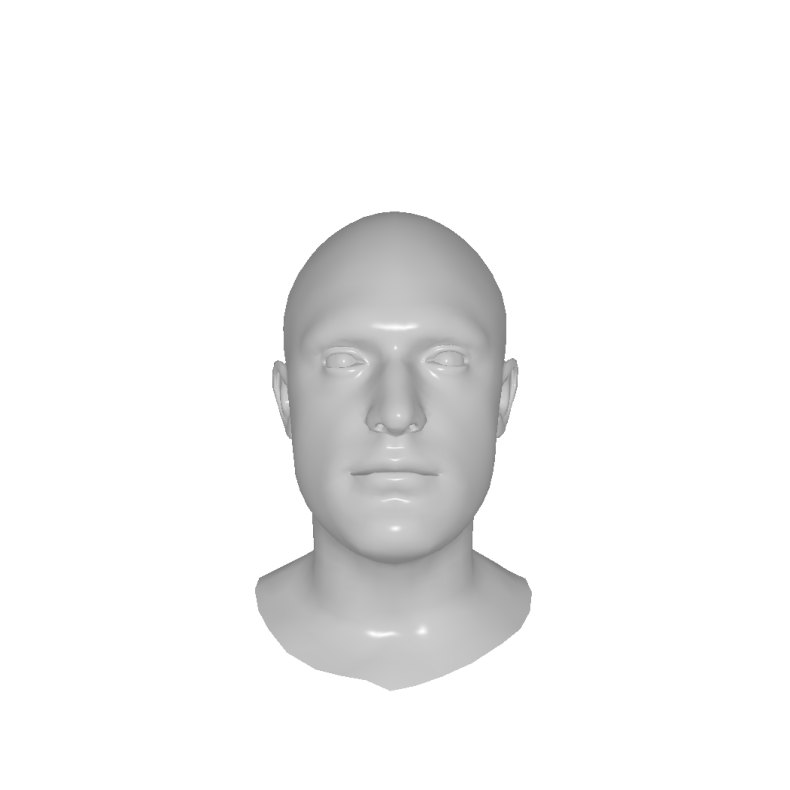

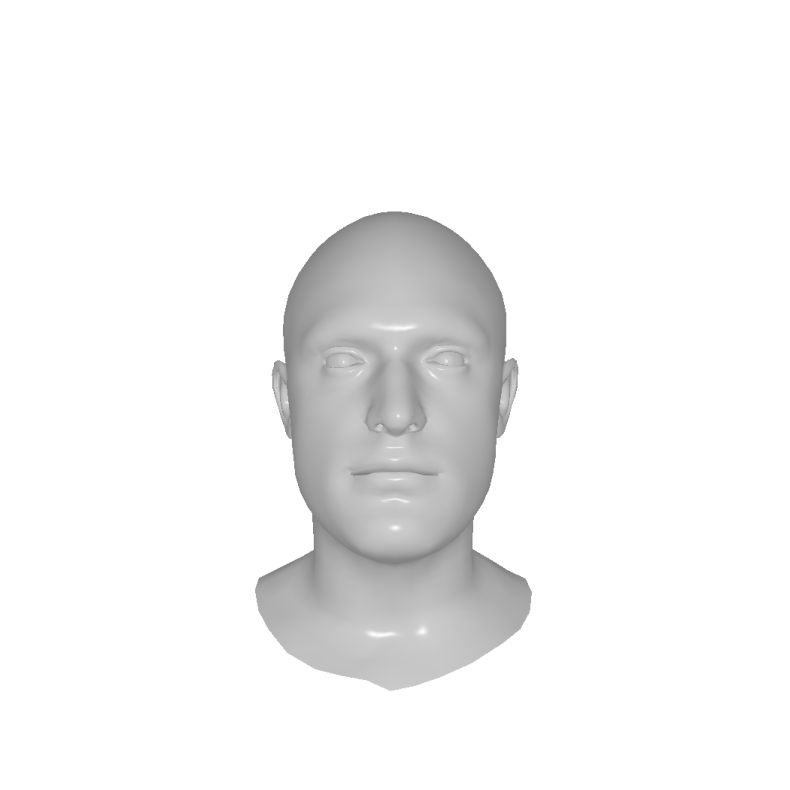

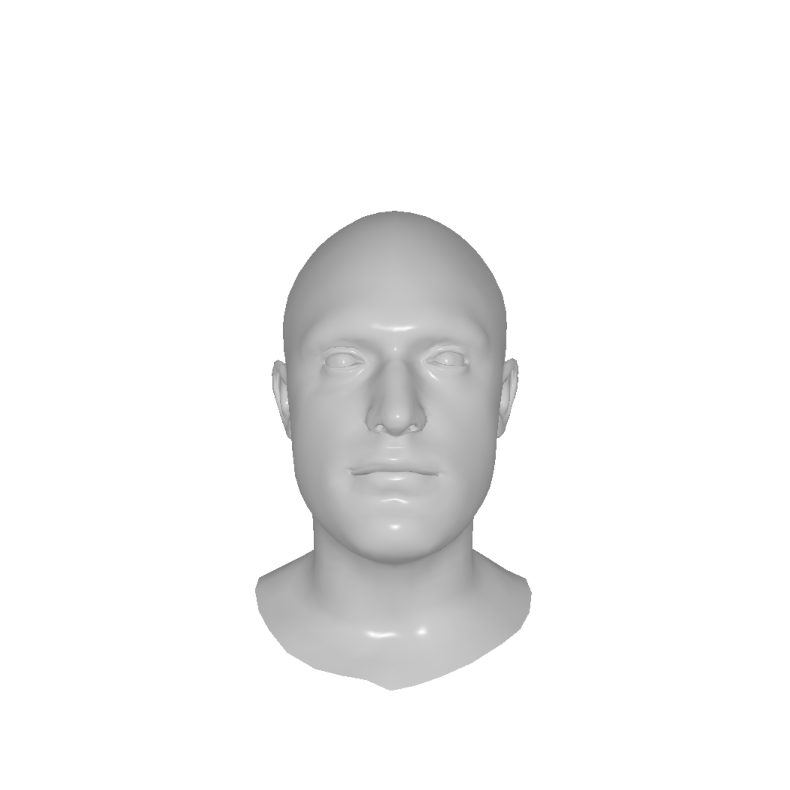

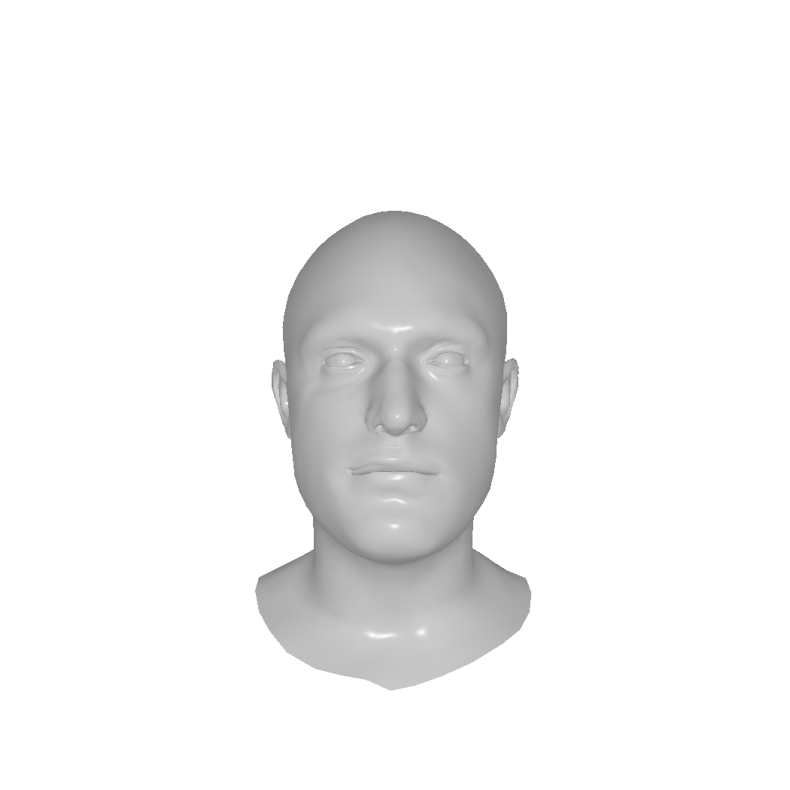

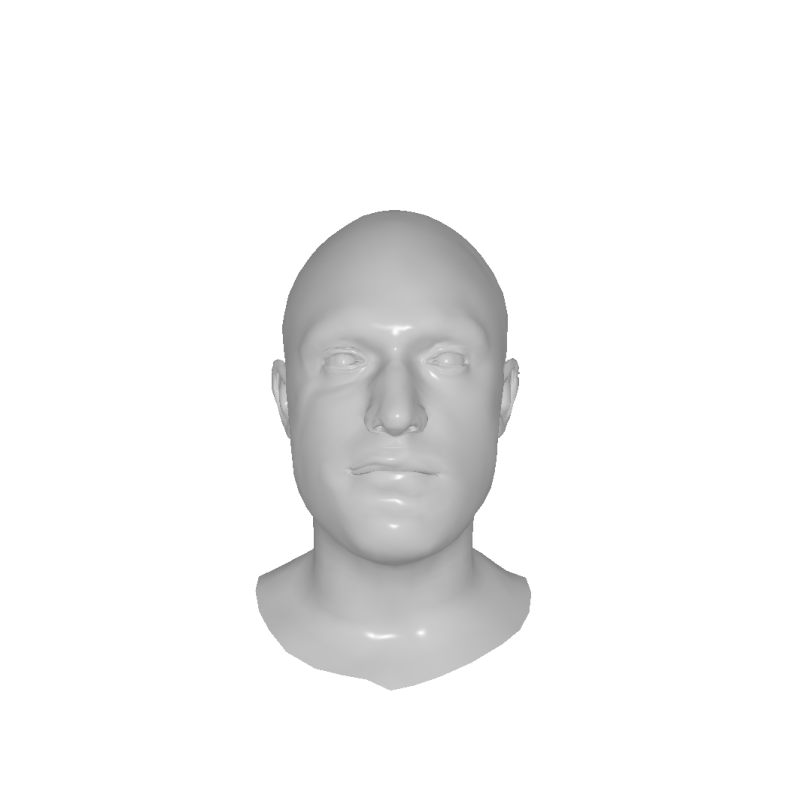

In [36]:
losses, deformed_meshes, single_losses = train(src_mesh,Niter=Niter, lr=lr, w_mse=w_mse, w_reg=w_reg, w_spars=w_spars,  w_landmarks= w_landmarks ,w_landmarks_relative=w_landmarks_relative, w_edge=w_edge, w_laplacian=w_laplacian, w_normal=w_normal,w_perceptual=w_perceptual, resize=resize, network=network)

In [37]:
for d in convert_to_dict_list(single_losses, losses):
    print(d)

{'mse_loss': 0.0005508891772478819, 'perceptual_loss': 0.9718236327171326, 'landmark_loss': 0.0, 'landmark_relative_loss': 0.0, 'reg_loss': 0.0, 'mask_sparsity_loss': 0.0, 'edge_loss': 0.0, 'laplacian_loss': 0.0, 'loss_normal': 0.0, 'total_loss': 5.60607385635376, 'index': 0}
{'mse_loss': 0.0005450919270515442, 'perceptual_loss': 0.9293149709701538, 'landmark_loss': 0.0, 'landmark_relative_loss': 0.0, 'reg_loss': 8.032785262912512e-05, 'mask_sparsity_loss': 0.0, 'edge_loss': 0.0, 'laplacian_loss': 0.0, 'loss_normal': 0.0, 'total_loss': 5.551883220672607, 'index': 1}
{'mse_loss': 0.0005445242859423161, 'perceptual_loss': 0.8964383602142334, 'landmark_loss': 0.0, 'landmark_relative_loss': 0.0, 'reg_loss': 0.0001290818036068231, 'mask_sparsity_loss': 0.0, 'edge_loss': 0.0, 'laplacian_loss': 0.0, 'loss_normal': 0.0, 'total_loss': 5.547794818878174, 'index': 2}
{'mse_loss': 0.0005457328516058624, 'perceptual_loss': 0.8680656552314758, 'landmark_loss': 0.0, 'landmark_relative_loss': 0.0, 're

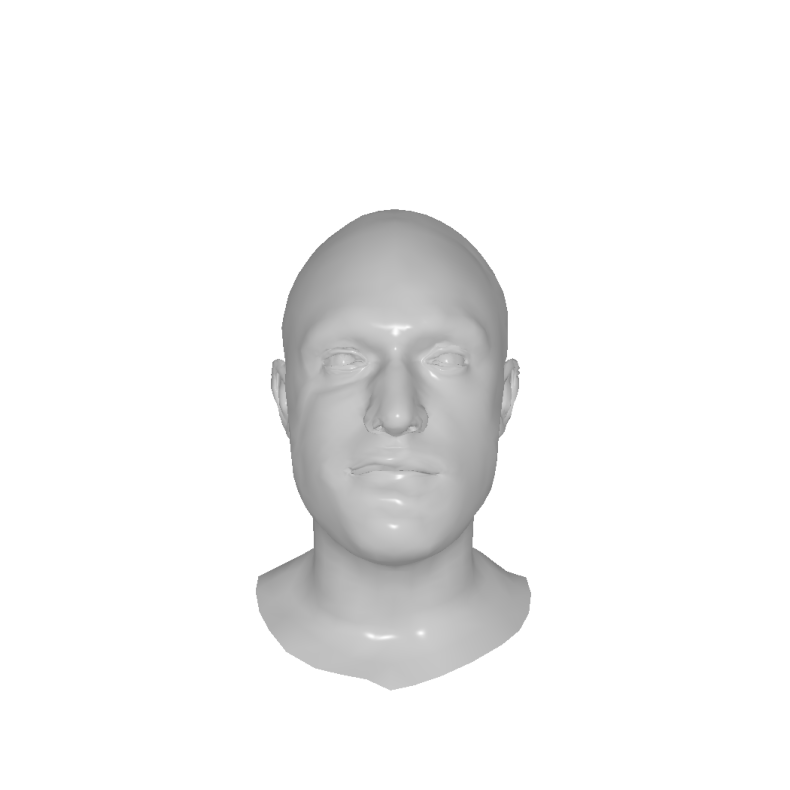

In [38]:
renderer = NormalRenderer()
image=renderer.Shot(deformed_meshes[-1], 0, 0, 2, 0).squeeze(0)
renderer.Stamp()

<Figure size 900x900 with 0 Axes>

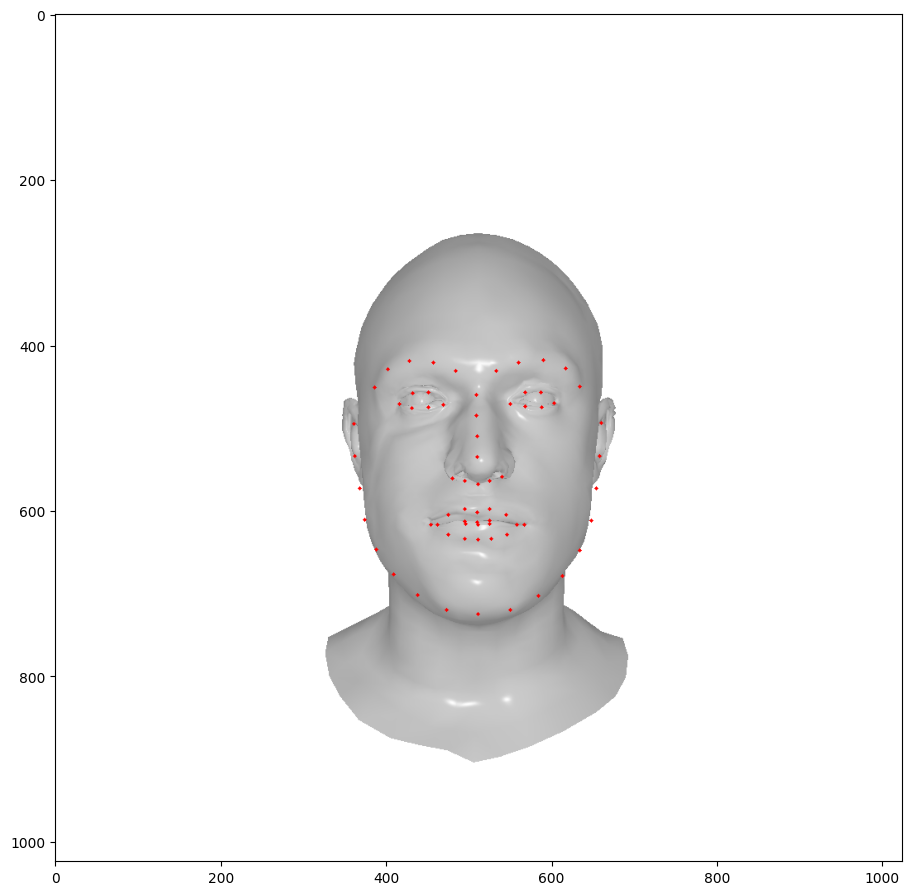

In [39]:
landmarks_given_image(image)

In [40]:
points=10000

sample_trg = sample_points_from_meshes(target_mesh,points)
sample_src = sample_points_from_meshes(deformed_meshes[-1],points)

chamfer_dist, hausdorff_dist, frobenius_dist, emd = evaluation_metrics(sample_src, sample_trg,points)
print(f"Chamfer distance: {chamfer_dist}")
print(f"Hausdorff distance: {hausdorff_dist}")
print(f"Frobenius distance: {frobenius_dist}")
print(f"Earth Mover's Distance: {emd}")

Chamfer distance: 0.024458982050418854
Hausdorff distance: 0.04037335887551308
Frobenius distance: 0.8120600581169128
Earth Mover's Distance: 0.0306297607421875


In [41]:
if MOUNT_DRIVE:
  with open(path+'/saved/'+f'meshes_I{Niter}_wmse{w_mse}_wreg{w_reg}_wspars{w_spars}_wlandmarks{w_landmarks}_relativeL{w_landmarks_relative}_wmaskcount_{w_mask_count}_resize{resize}_network{index}.pkl', 'wb') as f:
      pickle.dump(deformed_meshes, f)
  with open(path+'/saved/'+f'losses_I{Niter}_wmse{w_mse}_wreg{w_reg}_wspars{w_spars}_wlandmarks{w_landmarks}_relativeL{w_landmarks_relative}_wmaskcount_{w_mask_count}_resize{resize}_network{index}.pkl', 'wb') as f:
      pickle.dump(losses, f)
  with open(path+'/saved/'+f'single_l{Niter}_wmse{w_mse}_wreg{w_reg}_wspars{w_spars}_wlandmarks{w_landmarks}_relativeL{w_landmarks_relative}_wmaskcount_{w_mask_count}_resize{resize}_network{index}.pkl', 'wb') as f:
      pickle.dump(single_losses, f)

  0%|          | 0/20 [00:00<?, ?it/s]

Top 1 meshes by chamfer_dist:
Mesh 1 (index 8) : chamfer_dist = 0.06893432885408401
Top 1 meshes by hausdorff_dist:
Mesh 1 (index 2) : hausdorff_dist = 0.10068026185035706
Top 1 meshes by frobenius_dist:
Mesh 1 (index 4) : frobenius_dist = 0.7909552454948425
Top 1 meshes by emd:
Mesh 1 (index 3) : emd = 0.06316997528076172
Top 1 meshes by sum_of_main_metrics:
Mesh 1 (index 4) : sum_of_main_metrics = 1.0381605625152588
Top 1 meshes by total_loss:
Mesh 1 (index 2) : total_loss = 5.547794818878174
Top 1 meshes by mse:
Mesh 1 (index 2) : mse = 0.0005445242859423161
Top 1 meshes by landmark_loss1:
Mesh 1 (index 0) : landmark_loss1 = 0.0
Top 1 meshes by landmark_loss2:
Mesh 1 (index 0) : landmark_loss2 = 0.0
Top 1 meshes by perceptual_loss:
Mesh 1 (index 6) : perceptual_loss = 0.797808051109314
Top 1 meshes by sum_of_single_losses:
Mesh 1 (index 2) : sum_of_single_losses = 0.0005445242859423161
Top 1 meshes by combined_metric_mse_main:
Mesh 1 (index 4) : combined_metric_mse_main = 1.03870713

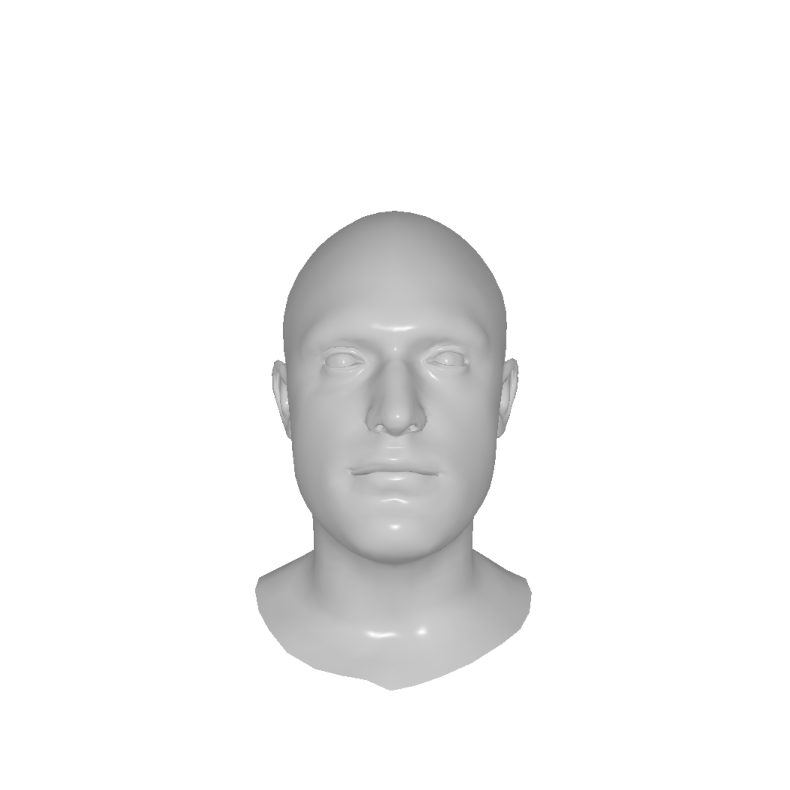

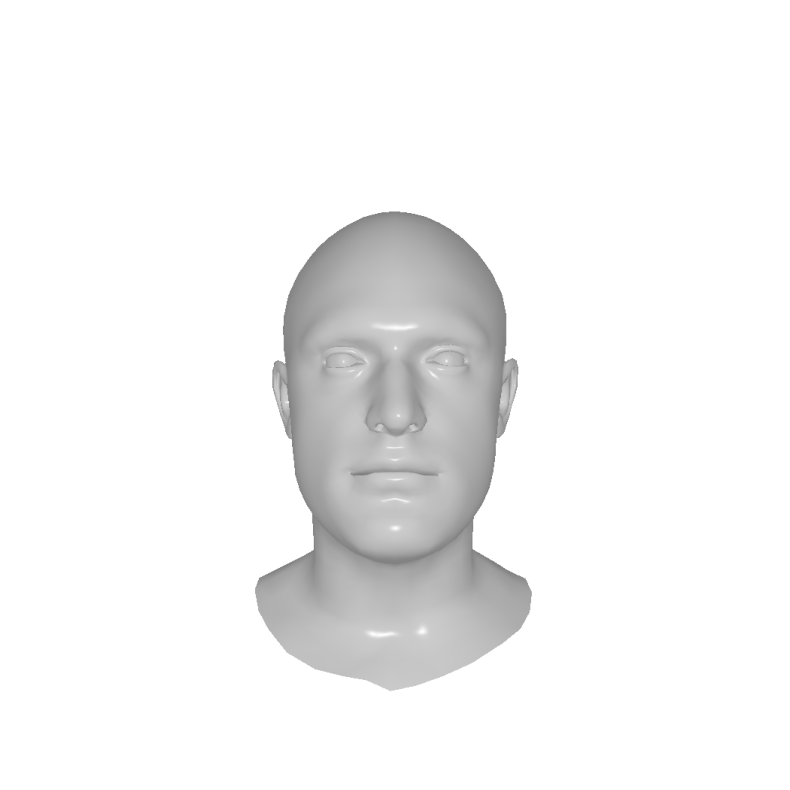

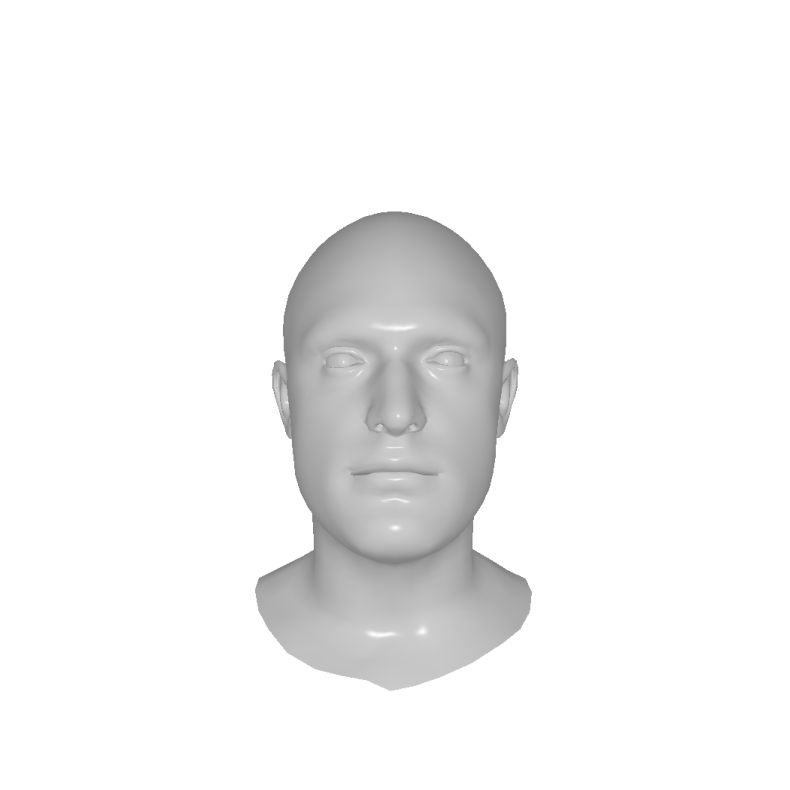

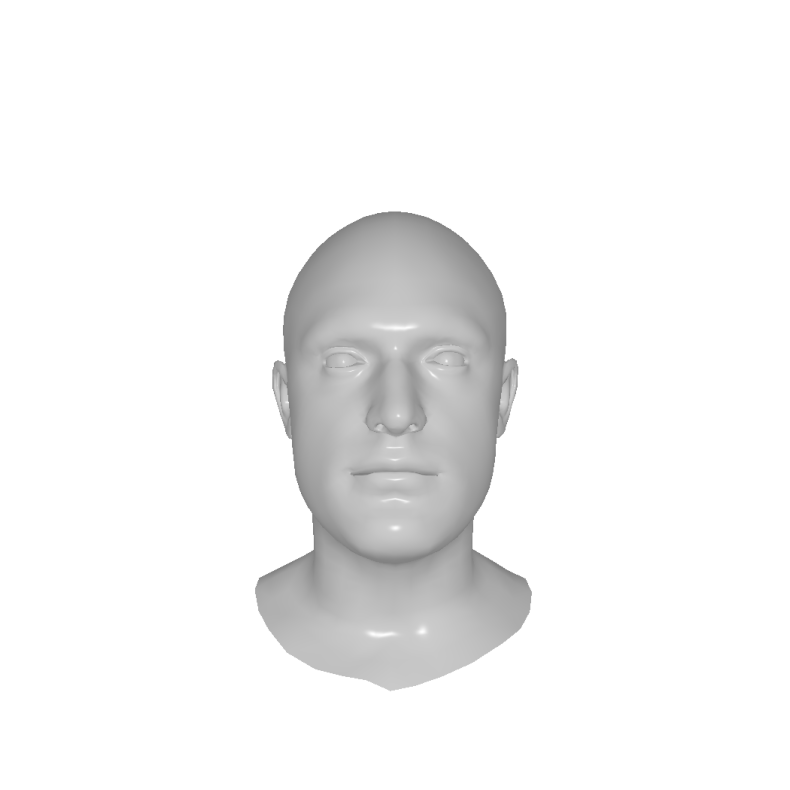

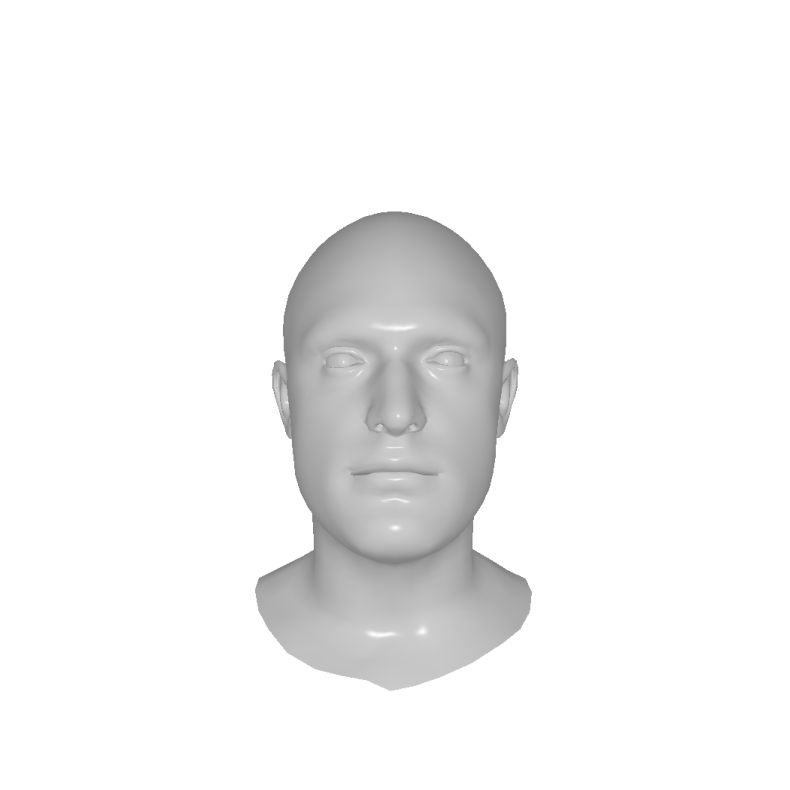

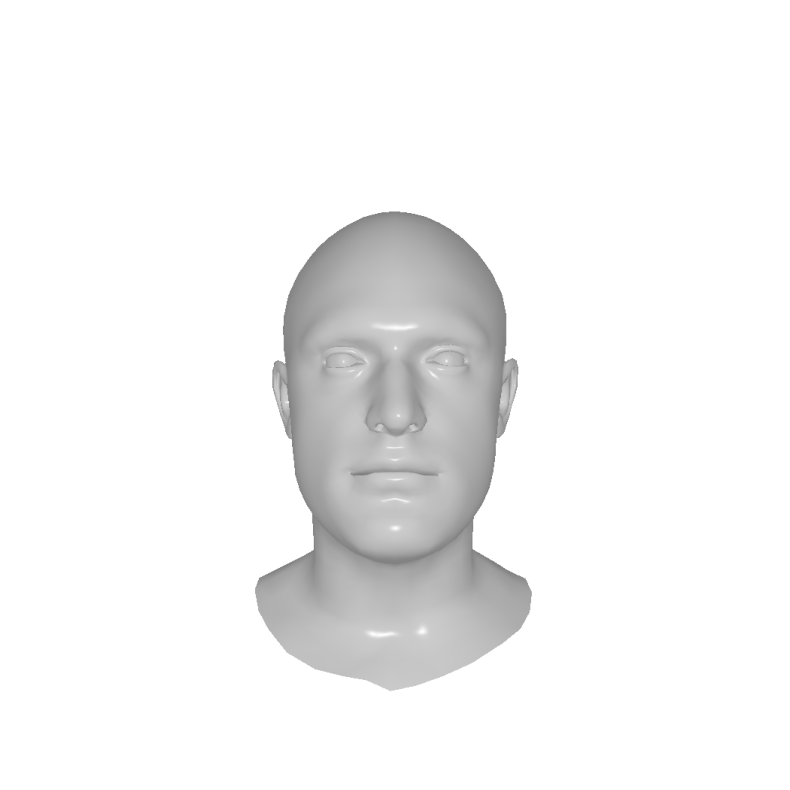

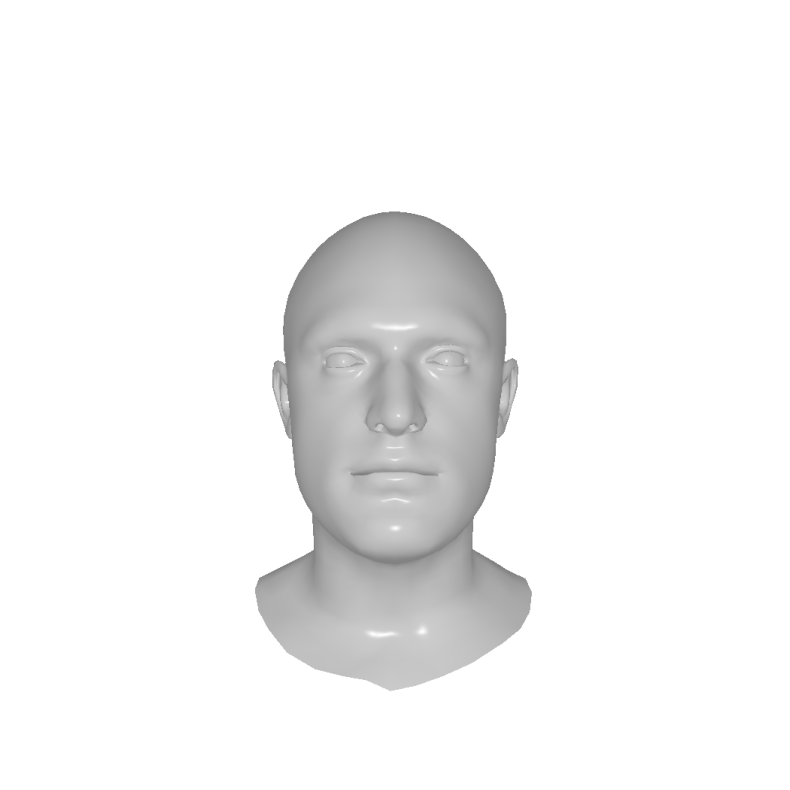

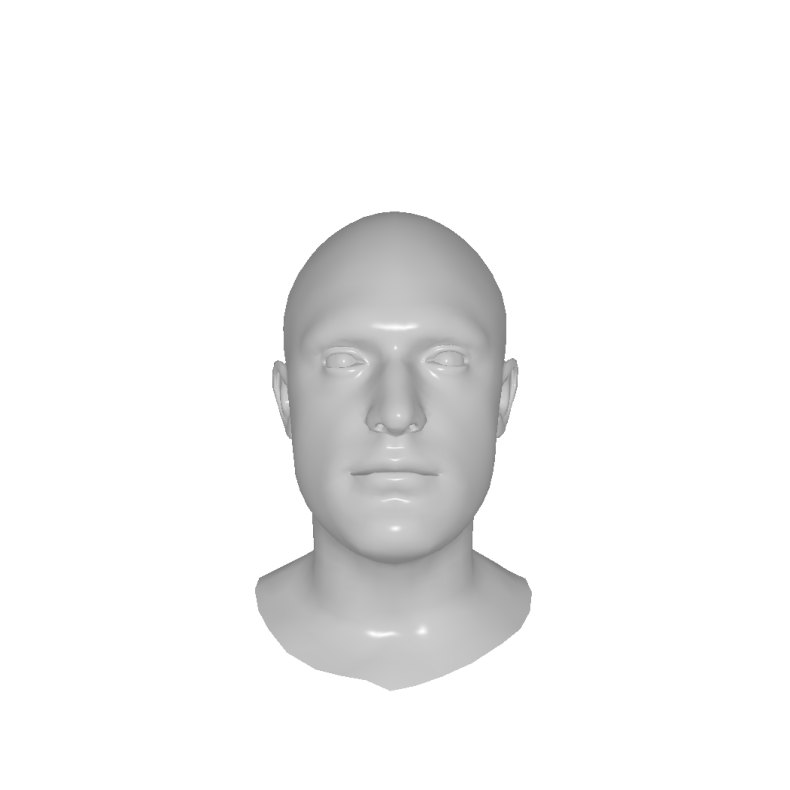

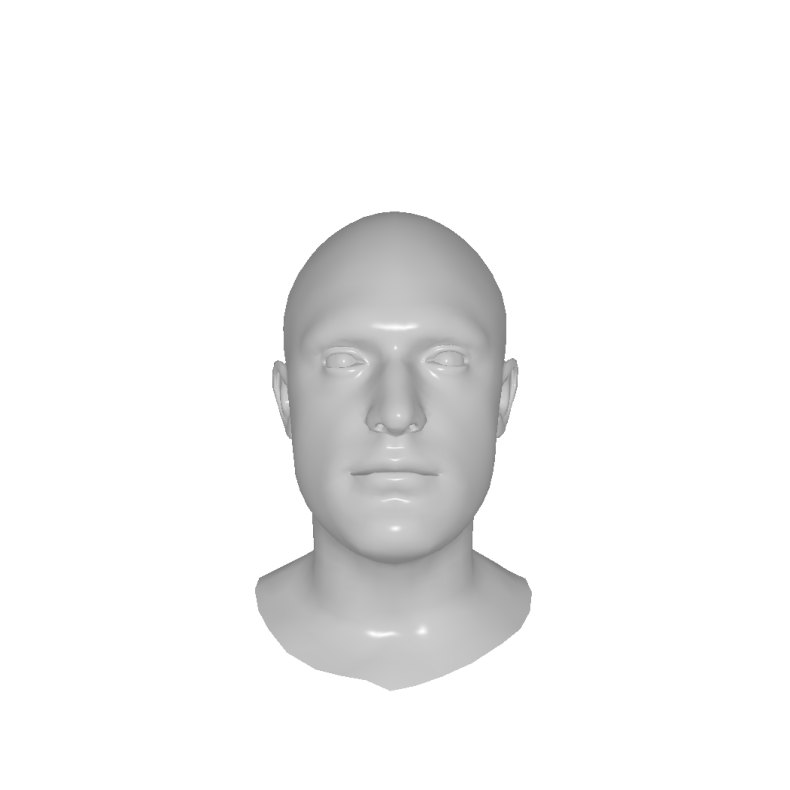

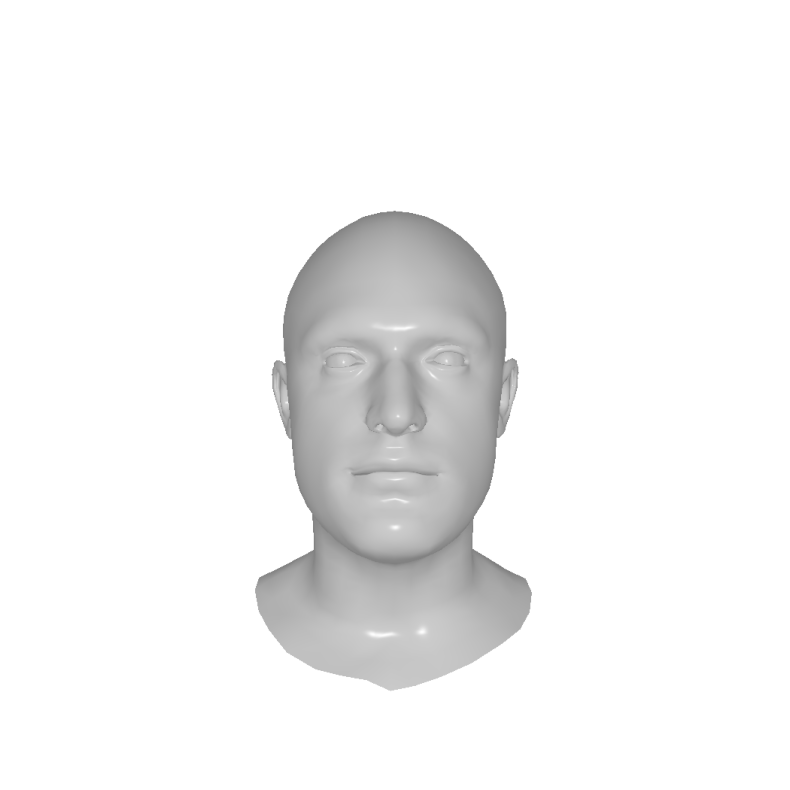

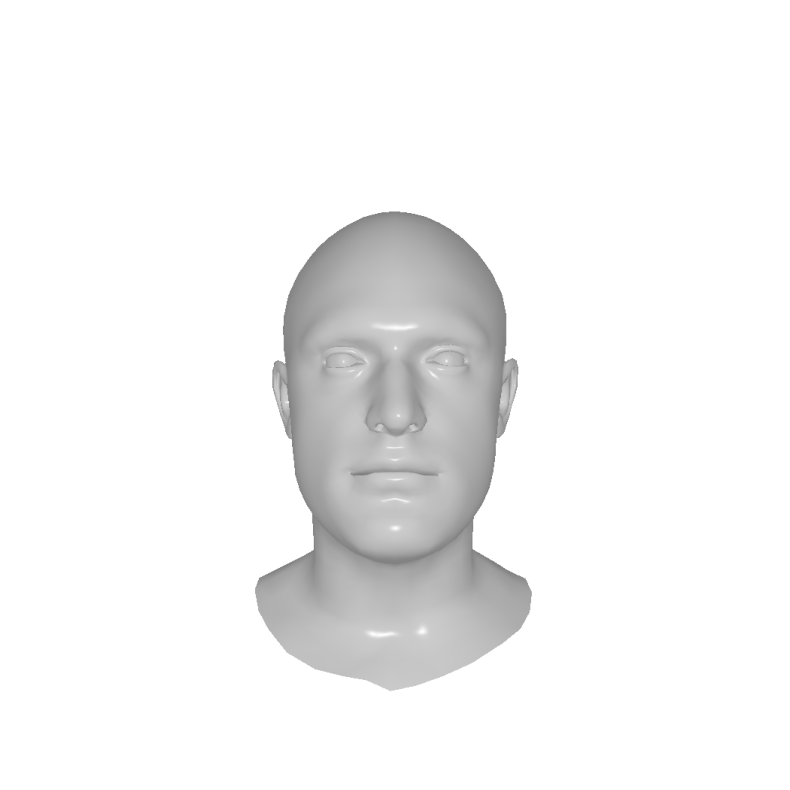

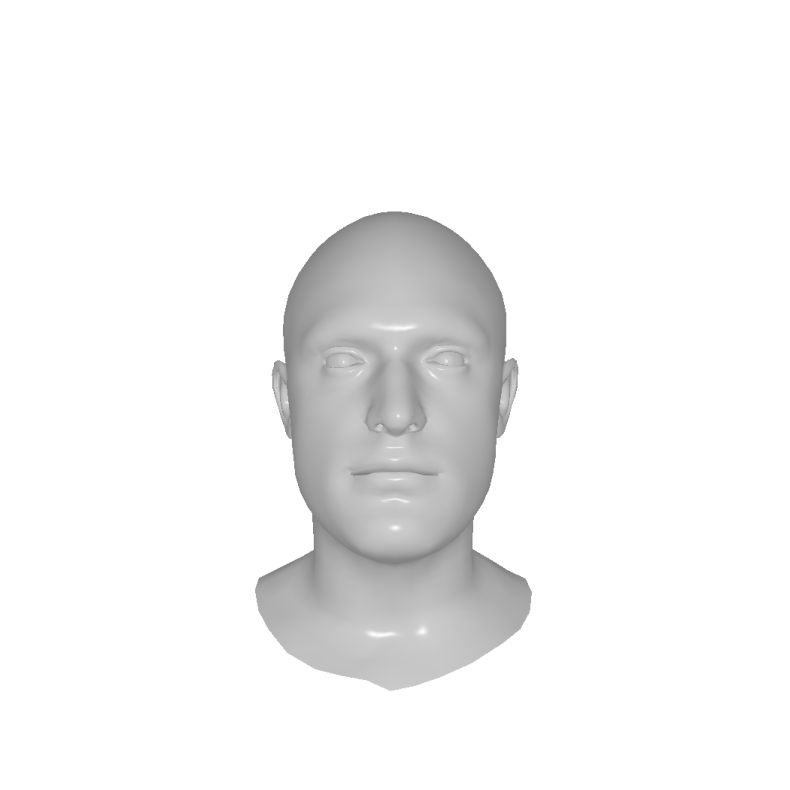

In [42]:
print_lowest_loss_faces(deformed_meshes ,single_losses, losses, target_mesh, N=1, render_mode=1,points=1000)

#MFE: training pipeline for Py3D

In [35]:
Niter=700                                                                      #number of iterations
lr=1e-5                                                                         #learning rate

w_mse =10000                                                                       #weight for mean square error loss
w_reg = 0                                                                       #weight for regularization term on magnitude of displacement
w_spars = 0                                                                     #weight for regularization term on magnitude of mask
w_mask_count = 0                                                                #weight for regularization term on magnitude of mask
w_landmarks = 0                                                                #weight for landmark loss
w_landmarks_relative = 0                                                        #weight for relative landmark loss
w_edge = 0                                                                      #edge loss
w_laplacian = 0                                                                 #laplacian loss
w_normal = 0                                                                   #normal loss
w_perceptual=0.1                                                                  #perceptual loss computed with VGG


num_vertices = src_mesh.verts_packed().shape[0]                                 #number of vertices in the source mesh

resize=1

  0%|          | 0/700 [00:00<?, ?it/s]

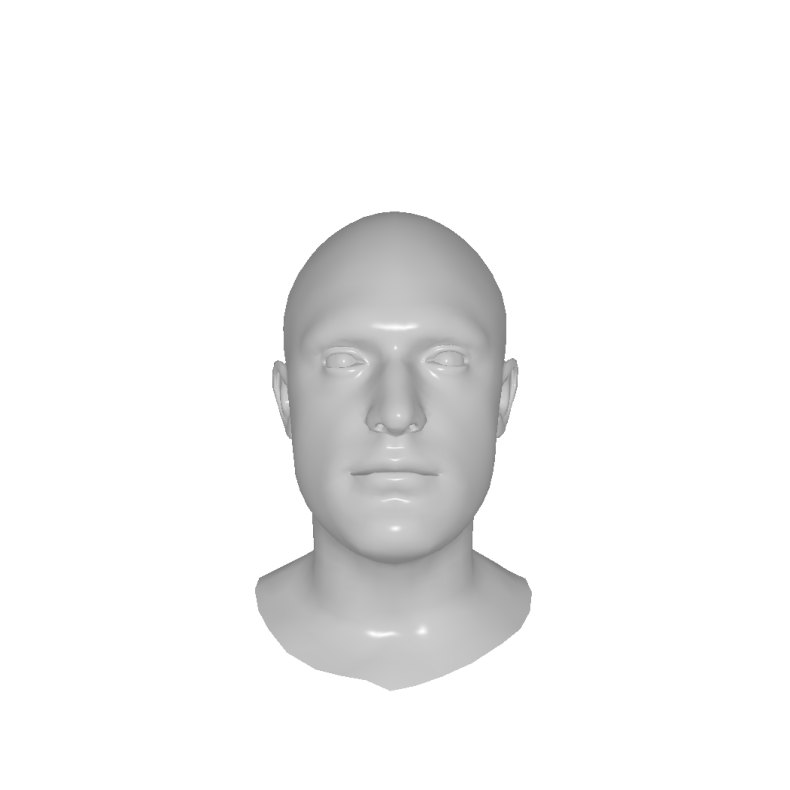

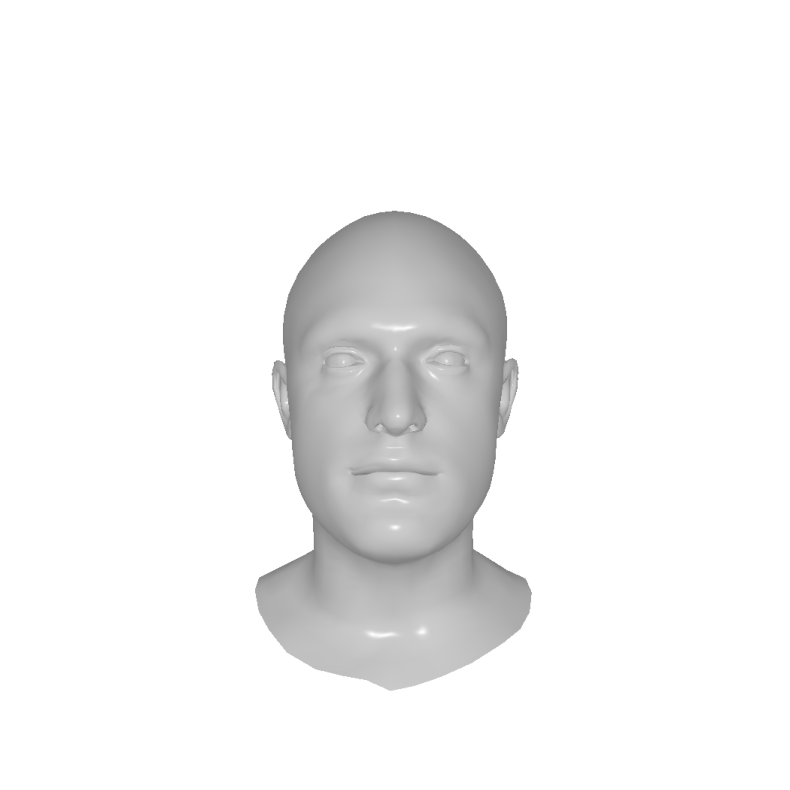

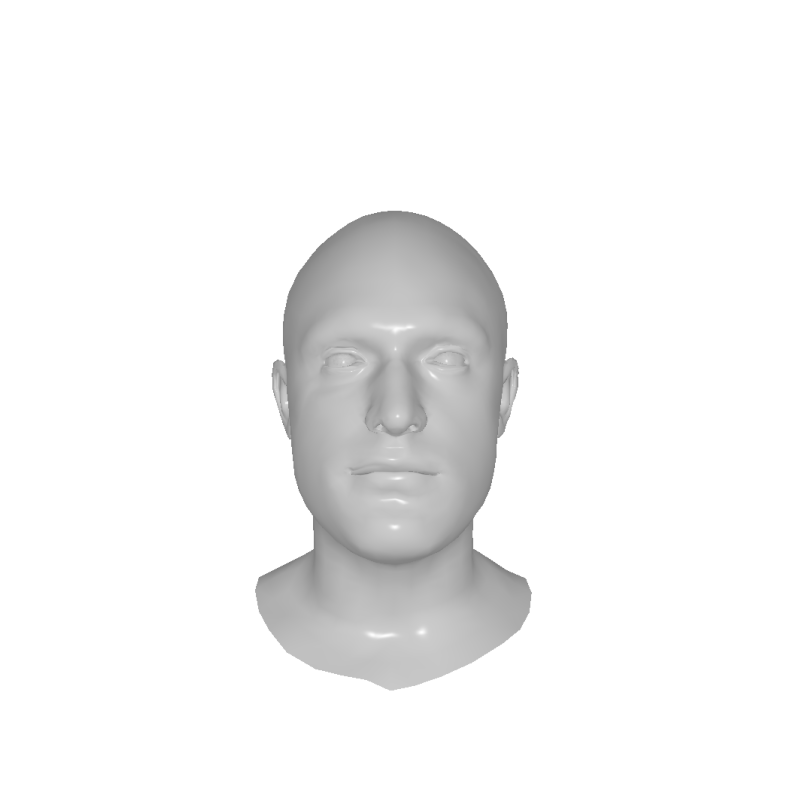

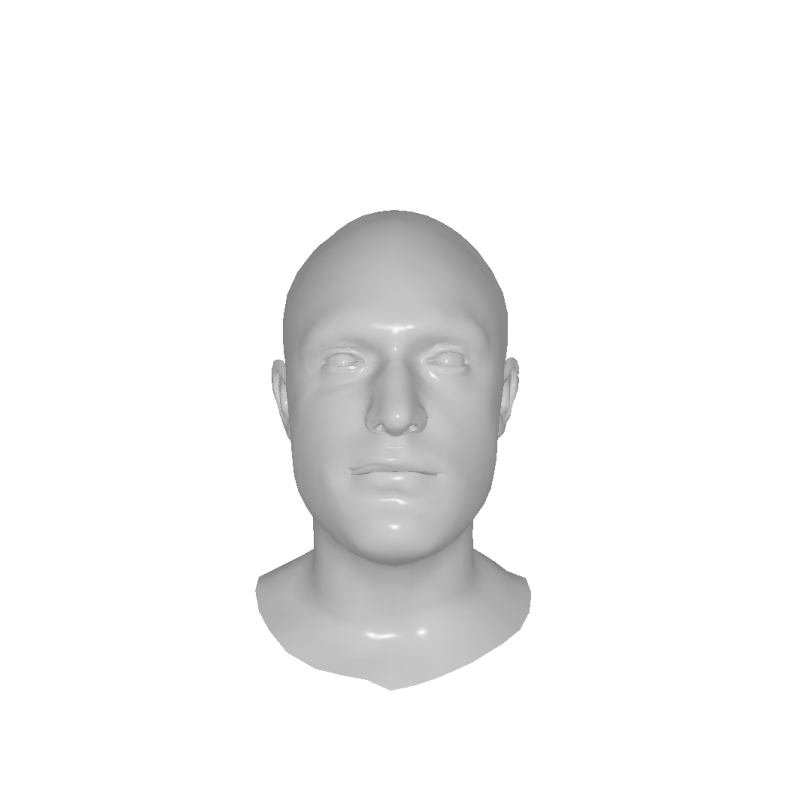

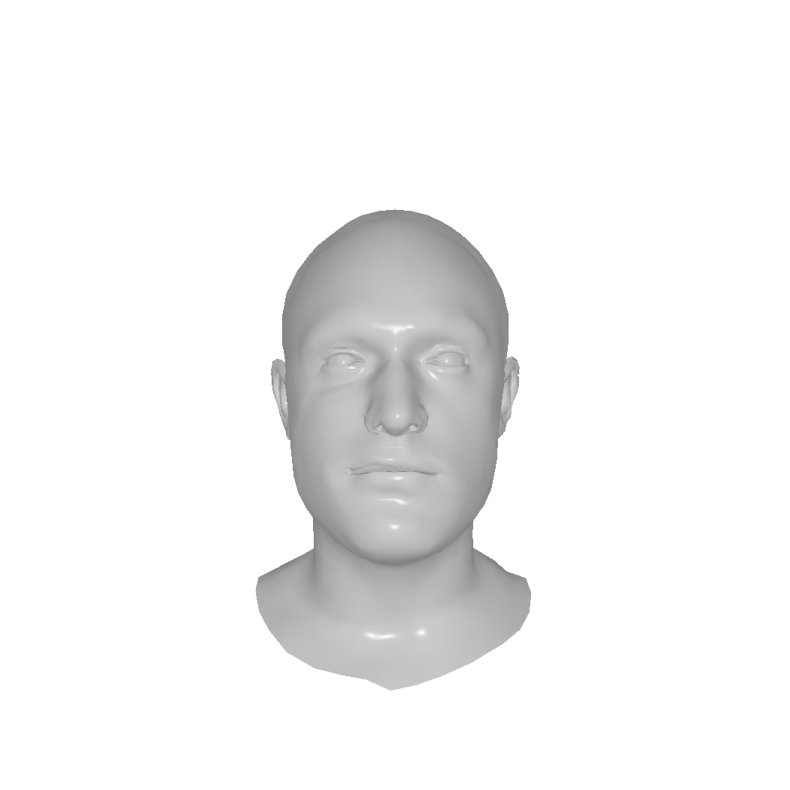

In [36]:
losses, deformed_meshes, single_losses = train_py3D(src_mesh,Niter=Niter, lr=lr, w_mse=w_mse, w_reg=w_reg, w_spars=w_spars,  w_landmarks= w_landmarks ,w_landmarks_relative=w_landmarks_relative, w_edge=w_edge, w_laplacian=w_laplacian, w_normal=w_normal,w_perceptual=w_perceptual, resize=resize)

In [37]:
points=10000

sample_trg = sample_points_from_meshes(target_mesh,points)
sample_src = sample_points_from_meshes(deformed_meshes[-1],points)

chamfer_dist, hausdorff_dist, frobenius_dist, emd = evaluation_metrics(sample_src, sample_trg,points)
print(f"Chamfer distance: {chamfer_dist}")
print(f"Hausdorff distance: {hausdorff_dist}")
print(f"Frobenius distance: {frobenius_dist}")
print(f"Earth Mover's Distance: {emd}")

Chamfer distance: 0.02513064071536064
Hausdorff distance: 0.04235751926898956
Frobenius distance: 0.8181095719337463
Earth Mover's Distance: 0.027348049926757812


#EFE: training pipeline

In [ ]:
meshes=[]
all_losses = []
all_single_losses = []
faces_selected=0
# LOADING TARGET MESH
verts, src_faces_idx, aux = load_obj(couples[faces_selected][1])
src_faces = src_faces_idx.verts_idx
verts_rgb = torch.ones_like(verts)[None]  # (1, V, 3)
textures = TexturesVertex(verts_features=verts_rgb.to(device))
target_mesh = Meshes(
    verts=[verts.to(device)],
    faces=[src_faces.to(device)],
    textures=textures
)

# LOADING SOURCE MESH
verts, faces_idx, aux = load_obj(couples[faces_selected][0])
faces = faces_idx.verts_idx
verts_rgb = torch.ones_like(verts)[None]  # (1, V, 3)
textures = TexturesVertex(verts_features=verts_rgb.to(device))
src_mesh = Meshes(
    verts=[verts.to(device)],
    faces=[faces.to(device)],
    textures=textures
)

# Compute centroid and scale
center, scale = compute_center_and_scale(src_mesh)

# Normalize meshes
src_mesh = normalize_mesh(src_mesh, center, scale)
target_mesh = normalize_mesh(target_mesh, center, scale)

In [63]:
num_vertices = src_mesh.verts_packed().shape[0]                                 # Number of vertices in the source mesh

networks = [SimpleNetwork(num_vertices).to(device),
            residualNetwork(num_vertices).to(device),
            MeshGraphNetwork(num_vertices).to(device),
            SimpleNetwork_single_vertex().to(device),
            NeuralStyleField(sigma=2, depth=2, width=256, encoding='gaussian', normdepth=2,
                                normratio=0.1, normclamp="tanh", niter=10,
                                progressive_encoding=False, input_dim=3, exclude=0).to(device)
           ]


resize=1                                                                        # If 1 meshes are resized and normalized

Niter=[20,20,20]                                                               # Number of iterations
lr=[1e-5,1e-5,1e-5]                                                             # Learning rate

w_mse = [0,10000,0]                                                         # Weight for mean square error loss
w_reg = [1000,100,1000]                                                               # Weight for regularization term on magnitude of displacement
w_spars = [0,0,0]                                                               # Weight for regularization term on magnitude of mask                                                      #weight for regularization term on magnitude of mask
w_landmarks = [0.1,0,0.1]                                                         # Weight for landmark loss
w_landmarks_relative =[0,0,0]                                                   # Weight for relative landmark loss
w_edge = [0,0,0]                                                                # Edge loss
w_laplacian =[0,0,0]                                                            # Laplacian loss
w_normal = [0,0,0]                                                              # Normal loss
w_perceptual= [0,0.1,0]                                                       # Perceptual loss computed with VGG

indices=[0,1,0]

points=10000

sample_trg = sample_points_from_meshes(target_mesh,points)

  0%|          | 0/20 [00:00<?, ?it/s]

Chamfer distance: 0.03147653490304947
Hausdorff distance: 0.13868004083633423
Frobenius distance: 0.8528638482093811
Earth Mover's Distance: 0.0316315185546875


  0%|          | 0/20 [00:00<?, ?it/s]

Chamfer distance: 0.031032338738441467
Hausdorff distance: 0.13321366906166077
Frobenius distance: 0.855140209197998
Earth Mover's Distance: 0.03608345031738281


  0%|          | 0/20 [00:00<?, ?it/s]

Chamfer distance: 0.031740881502628326
Hausdorff distance: 0.13083283603191376
Frobenius distance: 0.8437435626983643
Earth Mover's Distance: 0.03658714599609375


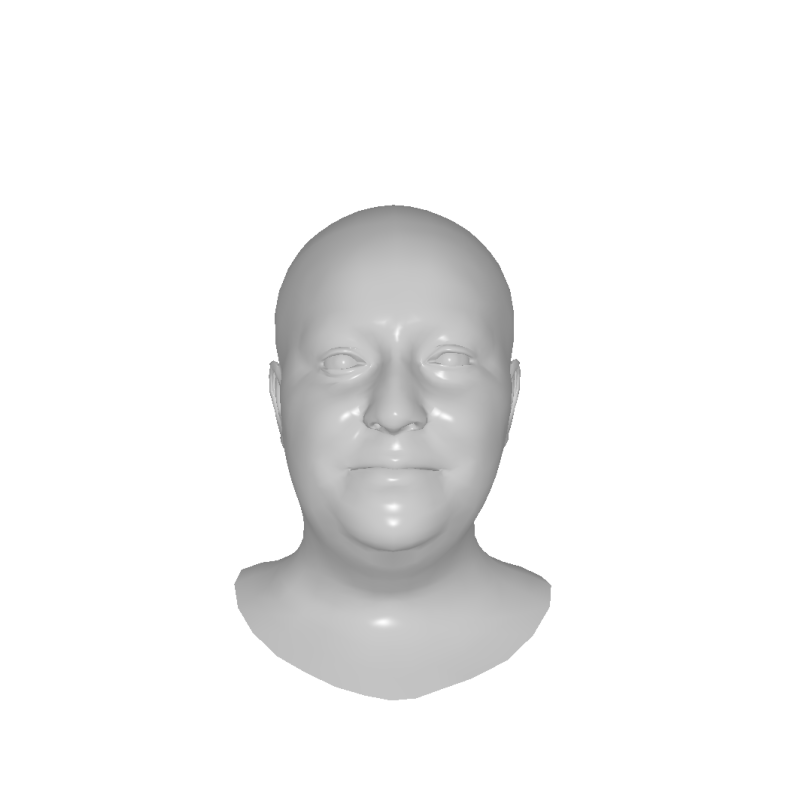

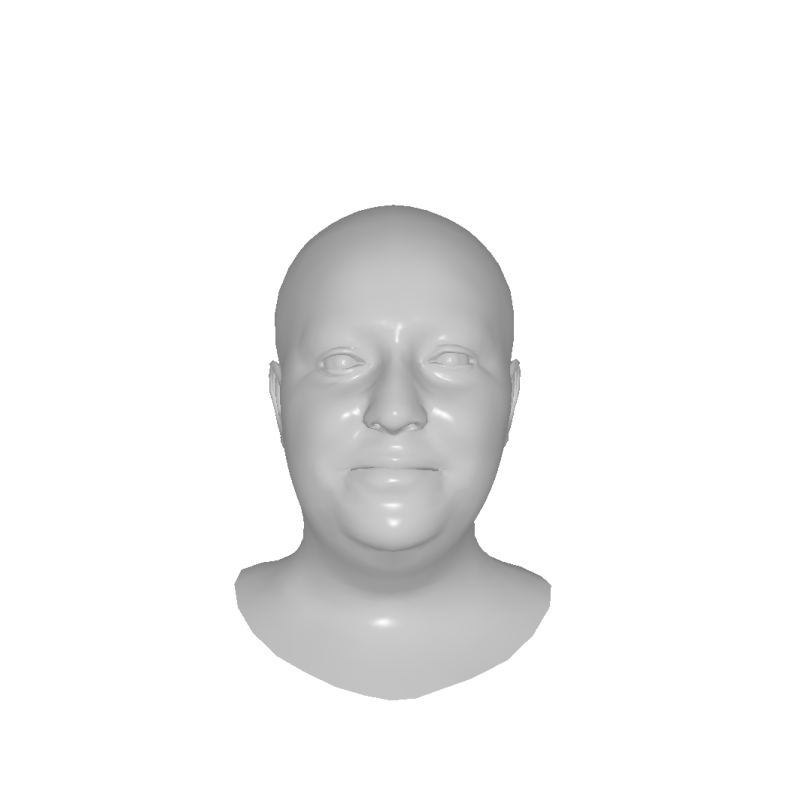

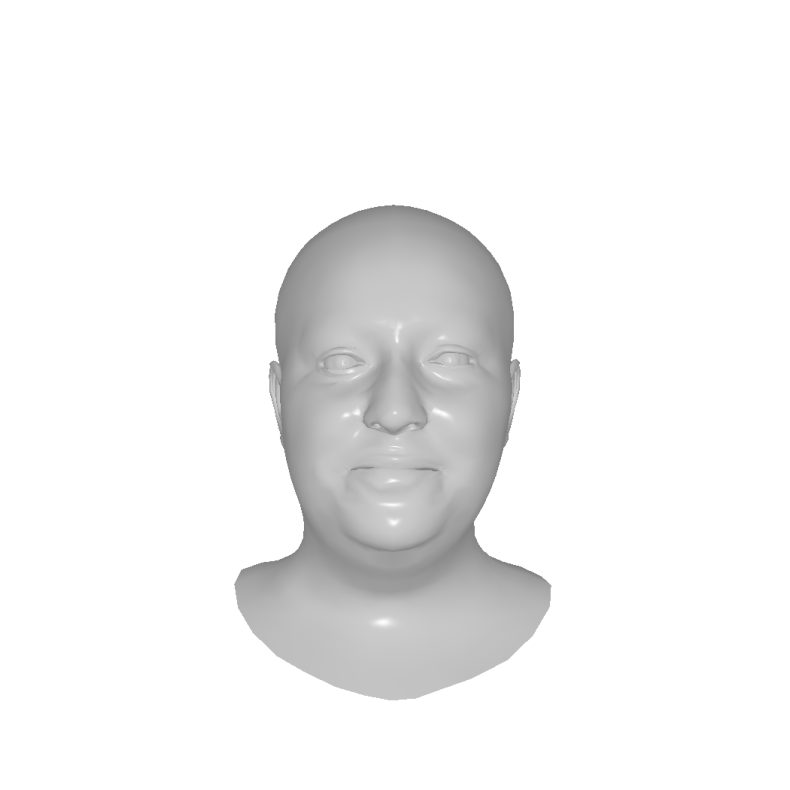

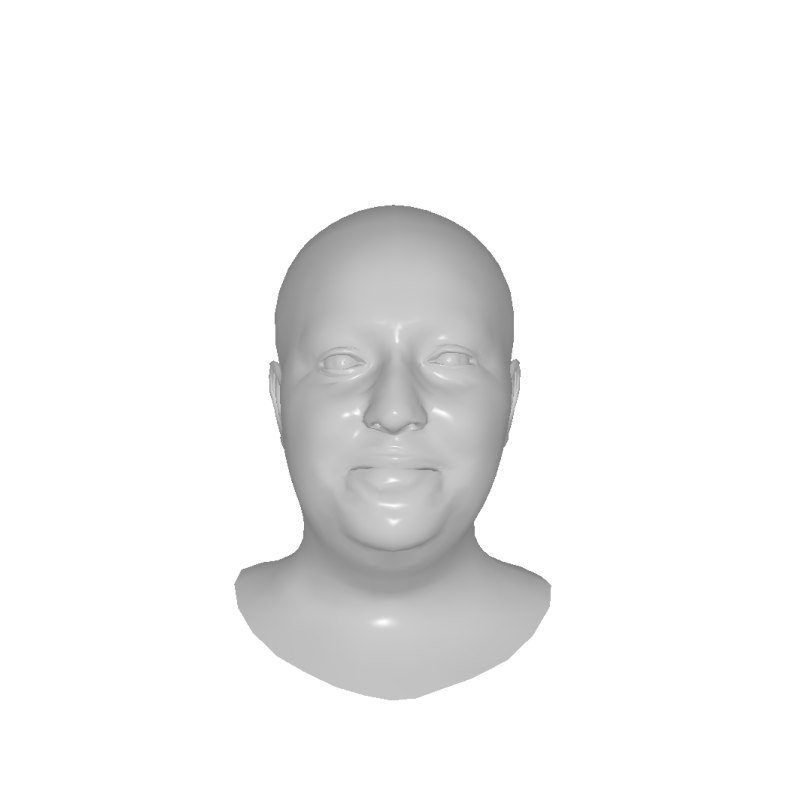

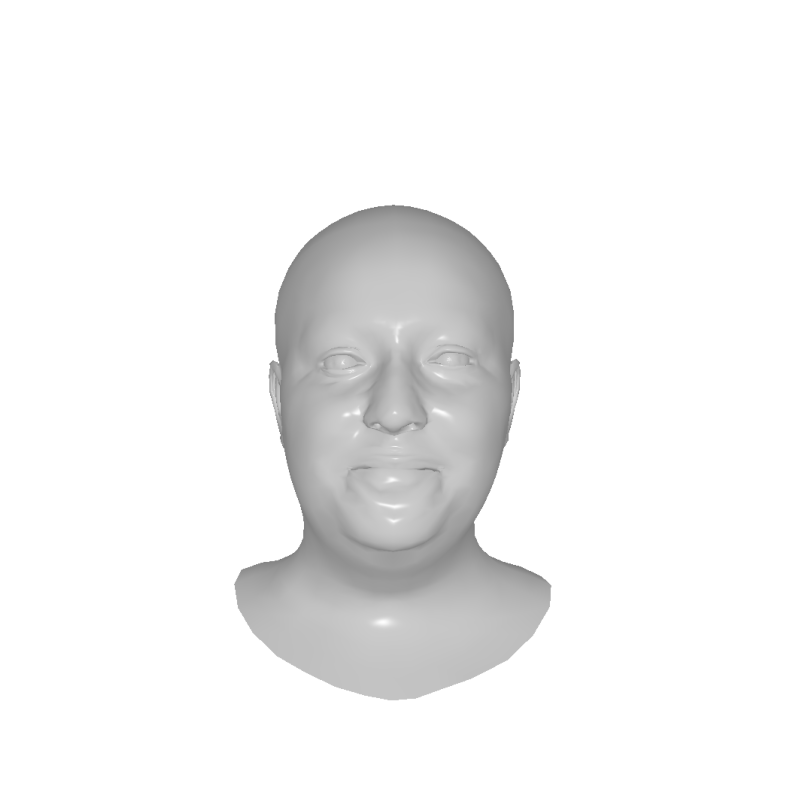

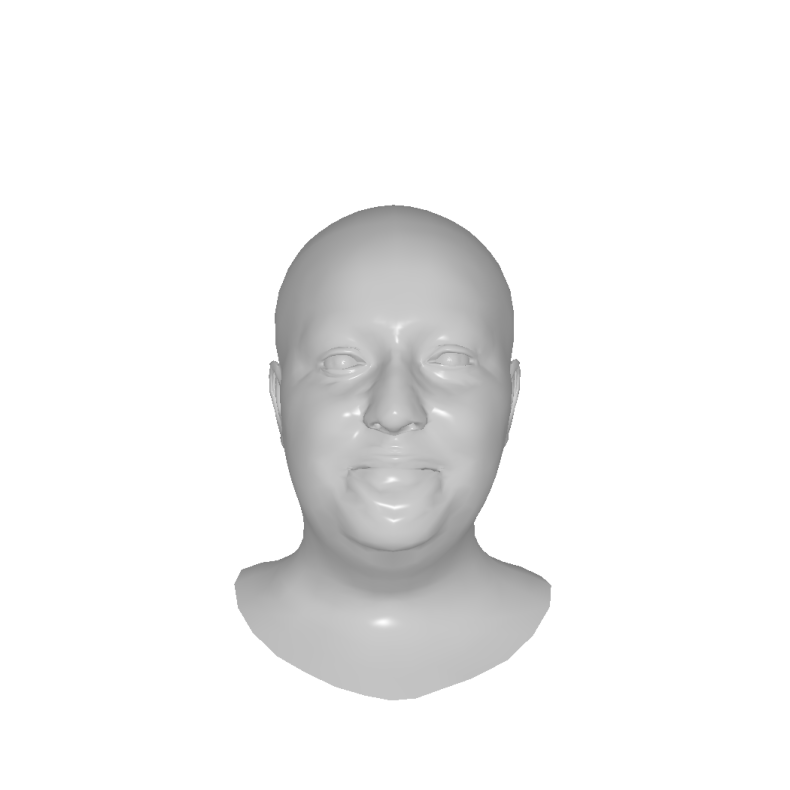

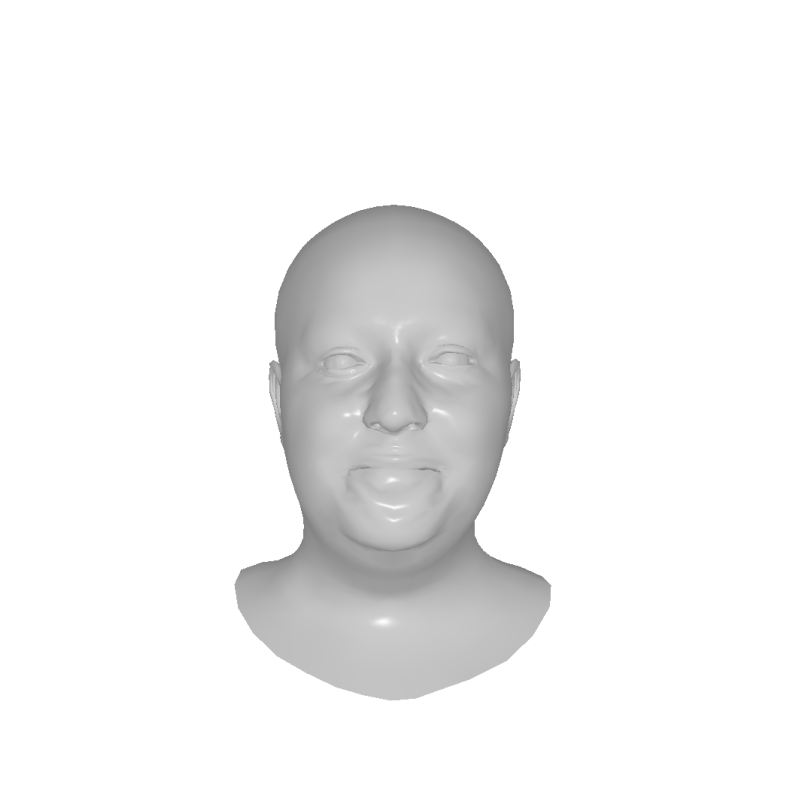

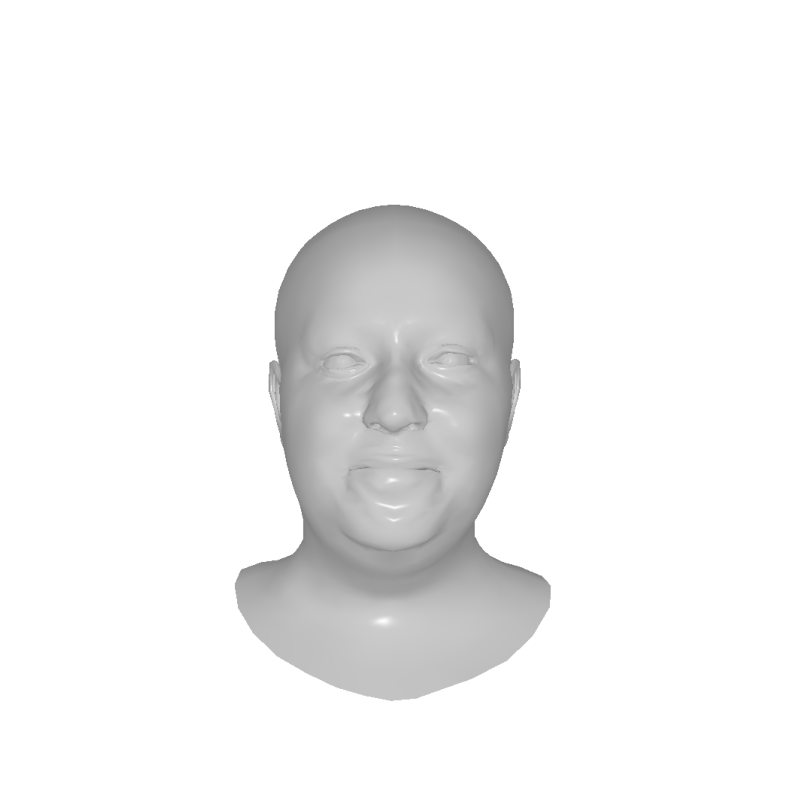

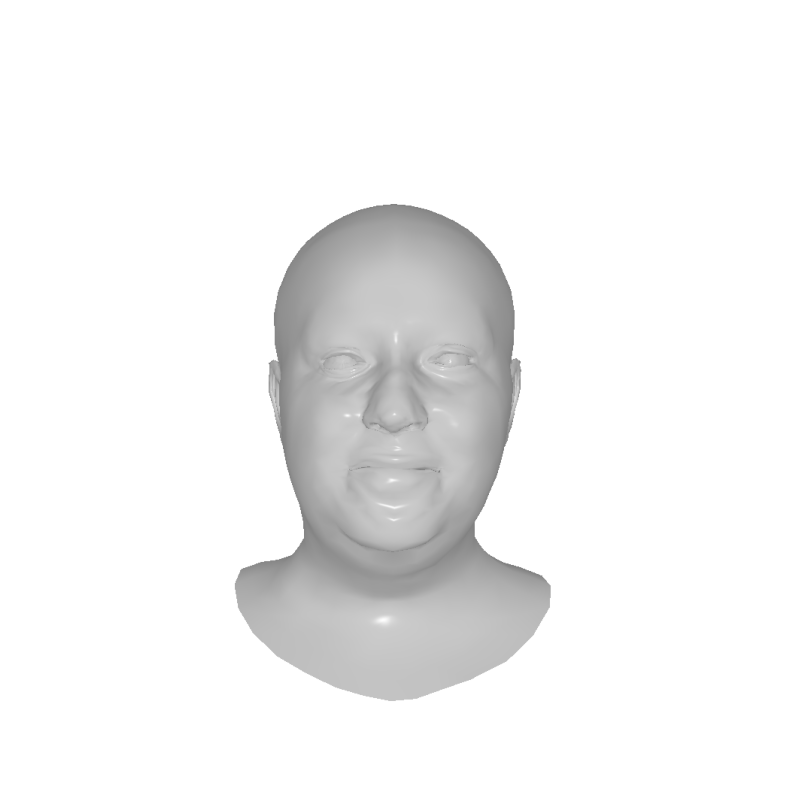

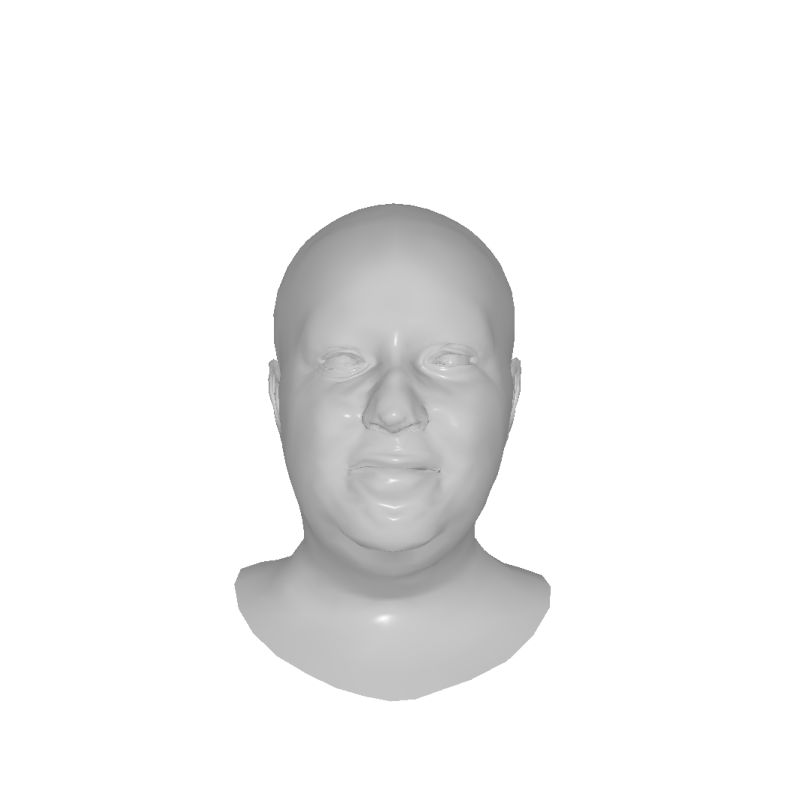

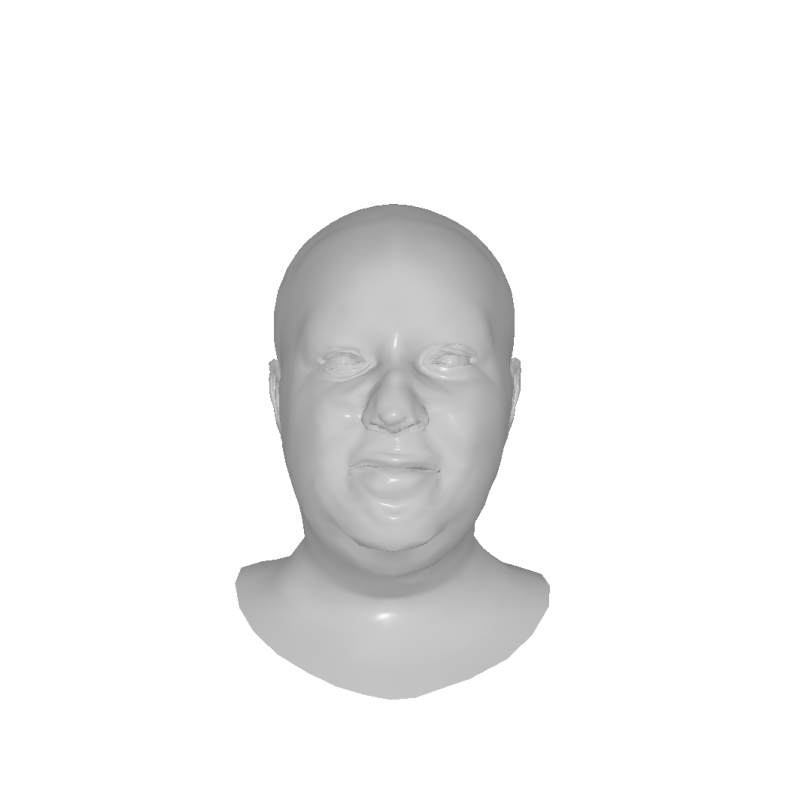

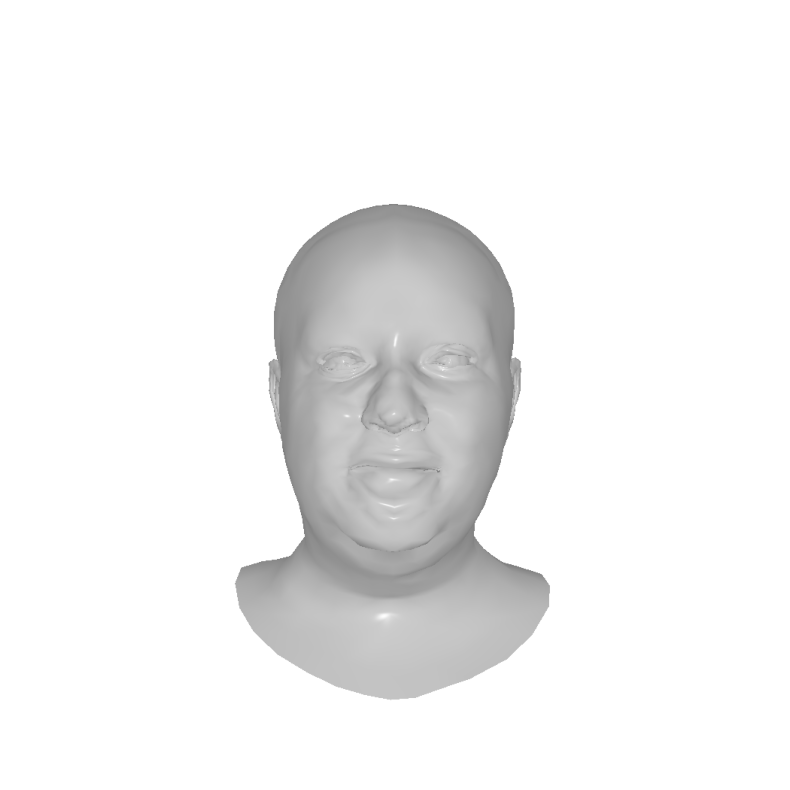

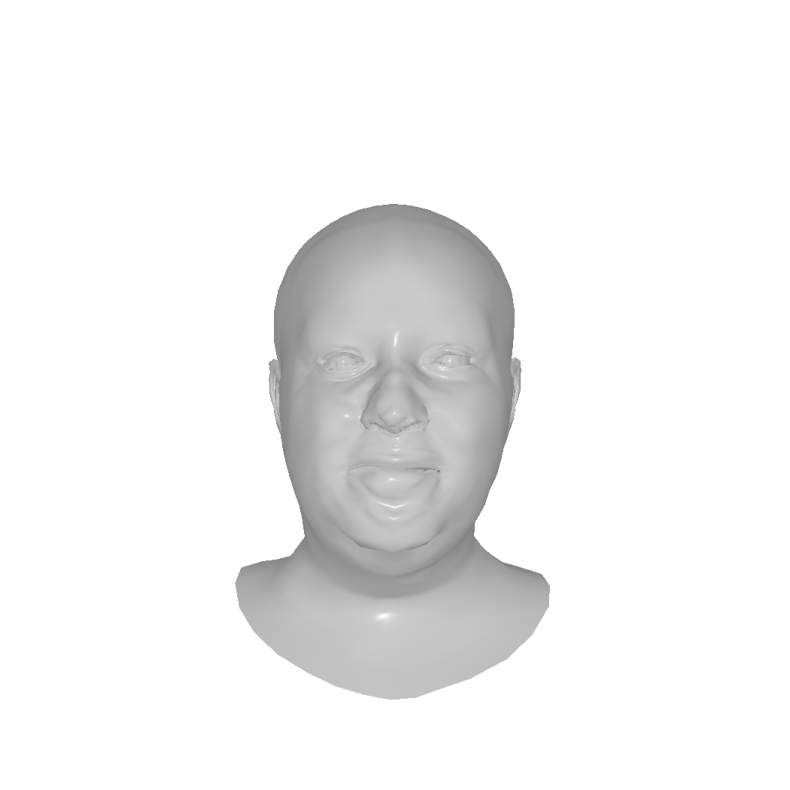

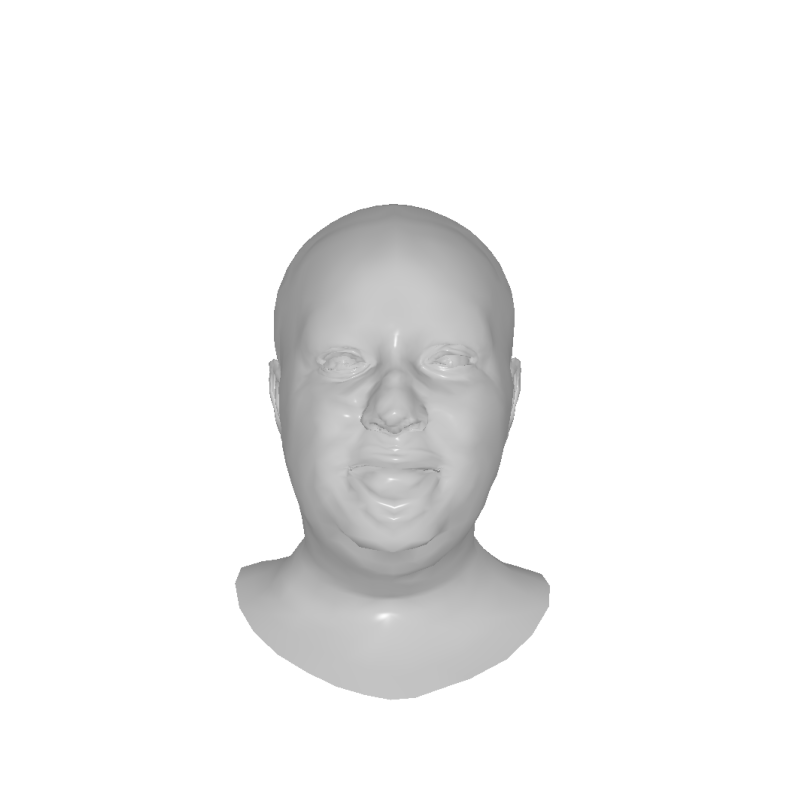

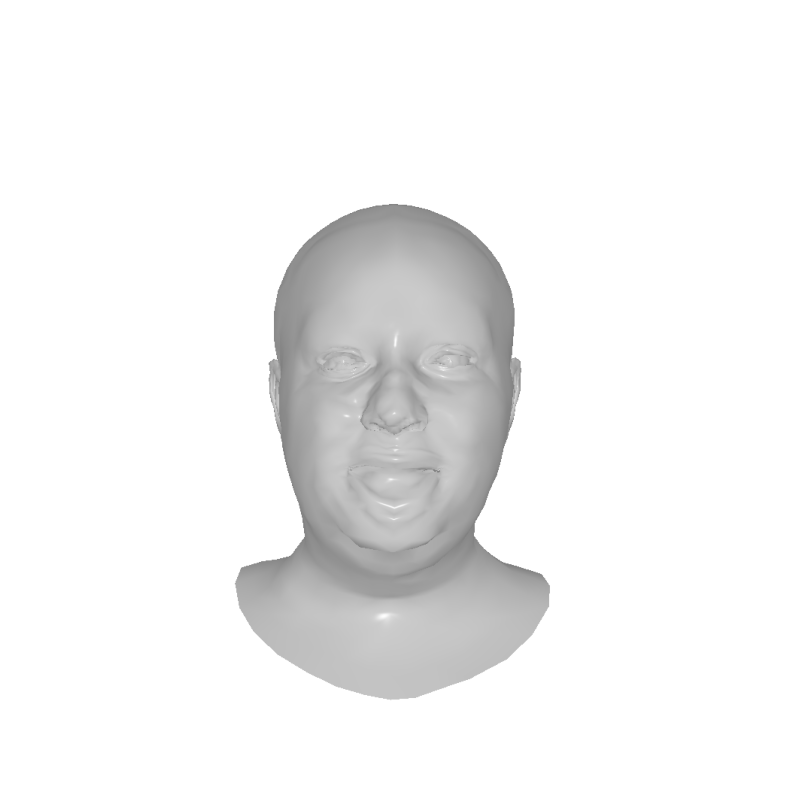

In [64]:
start_index=0
current_len=0
for i in range(len(indices)):

  if i >= start_index:
    if i == 0:
        starting_mesh = src_mesh.clone()
    else:
        # Get the last mesh from the previous network
        starting_mesh = meshes[current_len - 1].clone()

    loss,mesh,single_loss=train(src_mesh=starting_mesh, Niter=Niter[i], wd=1e-5, lr=lr[i], resize=1, network=networks[indices[i]],  w_mse=w_mse[i], w_reg=w_reg[i], w_spars= w_spars[i],  w_landmarks=w_landmarks[i], w_landmarks_relative=w_landmarks_relative[i], w_perceptual=w_perceptual[i],  w_edge=w_edge[i], w_laplacian=w_laplacian[i], w_normal=w_normal[i])

    #appending meshes losses computed so far
    meshes[current_len:] = mesh
    all_losses[current_len:]=loss
    all_single_losses[current_len:]=single_loss

    current_len+=Niter[i]

    sample_src = sample_points_from_meshes(mesh[-1],points)

    chamfer_dist, hausdorff_dist, frobenius_dist, emd = evaluation_metrics(sample_src, sample_trg,points)
    print(f"Chamfer distance: {chamfer_dist}")
    print(f"Hausdorff distance: {hausdorff_dist}")
    print(f"Frobenius distance: {frobenius_dist}")
    print(f"Earth Mover's Distance: {emd}")

In [50]:
import time

if MOUNT_DRIVE:
  timestamp = time.strftime("%Y%m%d-%H%M%S")
  os.makedirs(path+'/saved/', exist_ok=True)
  # Loop for saving all the files in one go
  with open(f'{path}/saved/meshes_Networks{len(indices)}_Indices{"-".join(map(str, indices))}_timestamp{timestamp}.pkl', 'wb') as f:
    pickle.dump(meshes, f)
  with open(f'{path}/saved/losses_Networks{len(indices)}_Indices{"-".join(map(str, indices))}_timestamp{timestamp}.pkl', 'wb') as f:
    pickle.dump(all_losses, f)
  with open(f'{path}/saved/single_losses_Networks{len(indices)}_Indices{"-".join(map(str, indices))}_timestamp{timestamp}.pkl', 'wb') as f:
    pickle.dump(all_single_losses, f)


  0%|          | 0/60 [00:00<?, ?it/s]

Top 1 meshes by chamfer_dist:
Mesh 1 (index 50) : chamfer_dist = 0.07469569146633148
Top 1 meshes by hausdorff_dist:
Mesh 1 (index 42) : hausdorff_dist = 0.12759098410606384
Top 1 meshes by frobenius_dist:
Mesh 1 (index 46) : frobenius_dist = 0.8281514048576355
Top 1 meshes by emd:
Mesh 1 (index 25) : emd = 0.06602911376953124
Top 1 meshes by sum_of_main_metrics:
Mesh 1 (index 46) : sum_of_main_metrics = 1.1153069734573364
Top 1 meshes by total_loss:
Mesh 1 (index 59) : total_loss = 0.6292254328727722
Top 1 meshes by mse:
Mesh 1 (index 29) : mse = 0.0012510051019489765
Top 1 meshes by landmark_loss1:
Mesh 1 (index 20) : landmark_loss1 = 0.0
Top 1 meshes by landmark_loss2:
Mesh 1 (index 0) : landmark_loss2 = 0.0
Top 1 meshes by perceptual_loss:
Mesh 1 (index 0) : perceptual_loss = 0.0
Top 1 meshes by sum_of_single_losses:
Mesh 1 (index 29) : sum_of_single_losses = 0.0012510051019489765
Top 1 meshes by combined_metric_mse_main:
Mesh 1 (index 46) : combined_metric_mse_main = 1.11673831939

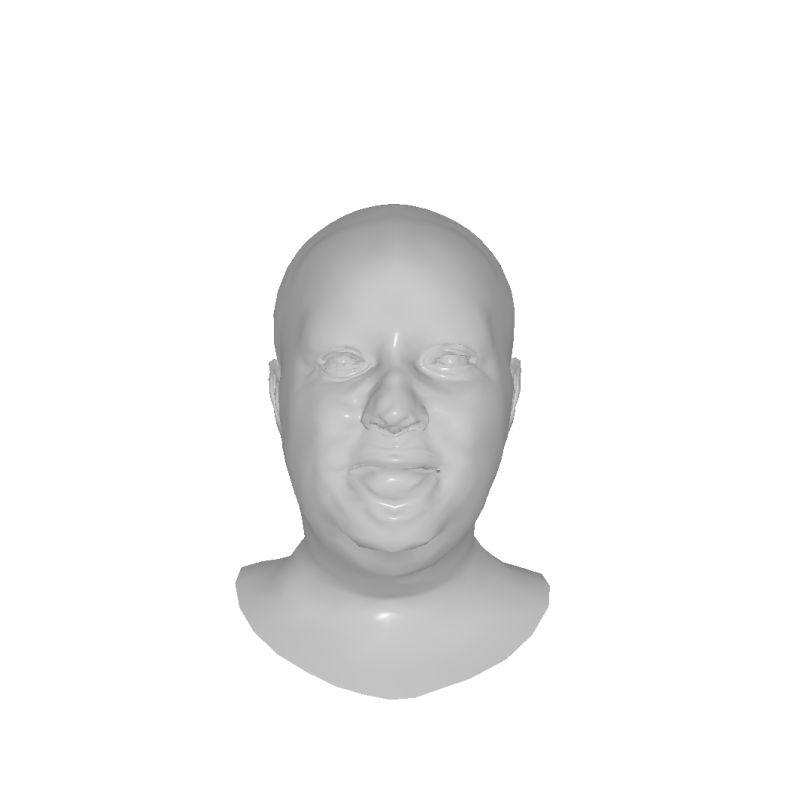

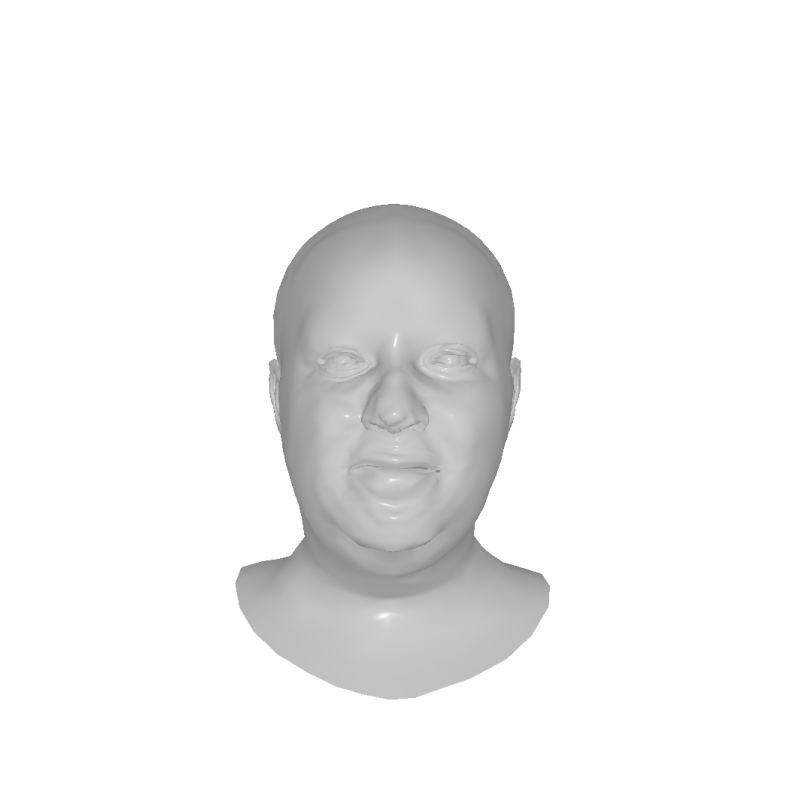

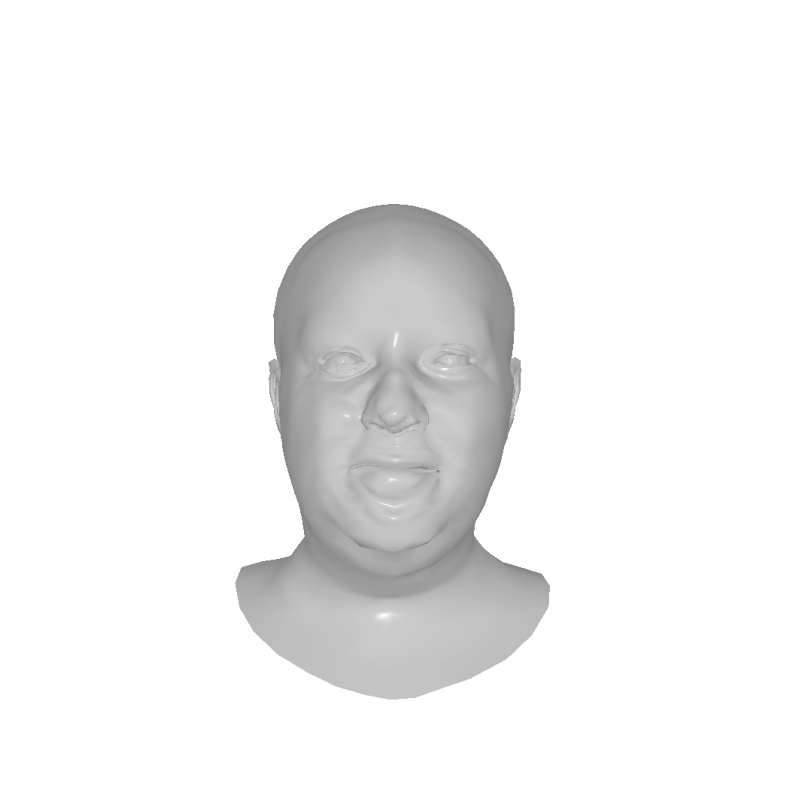

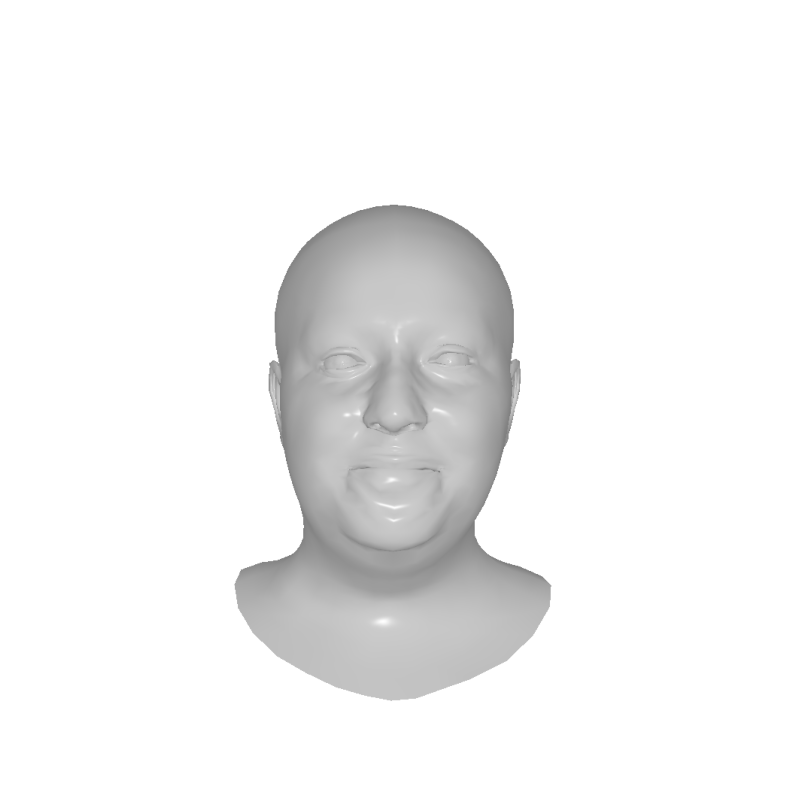

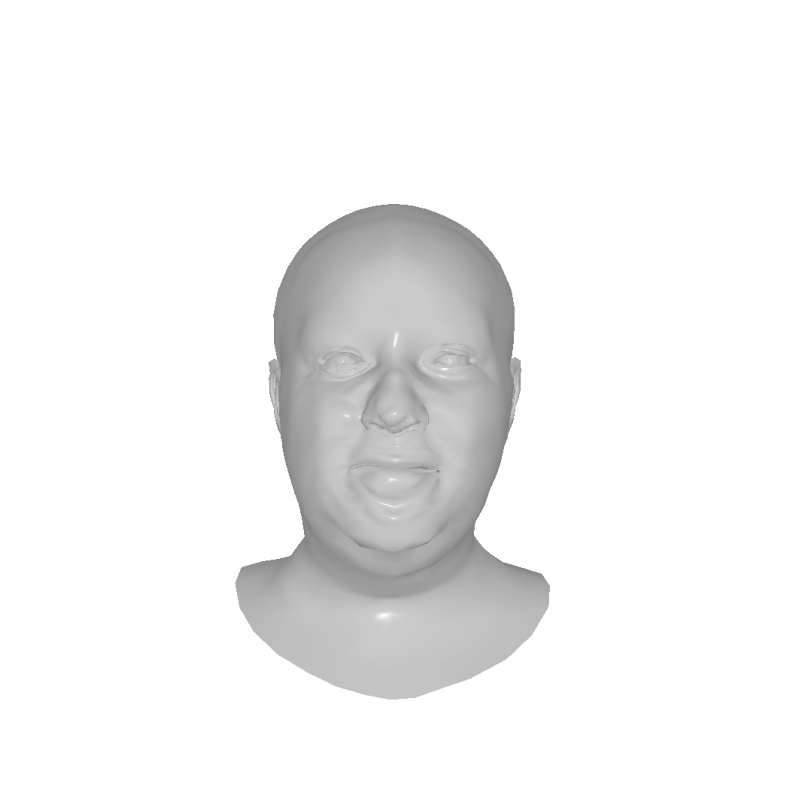

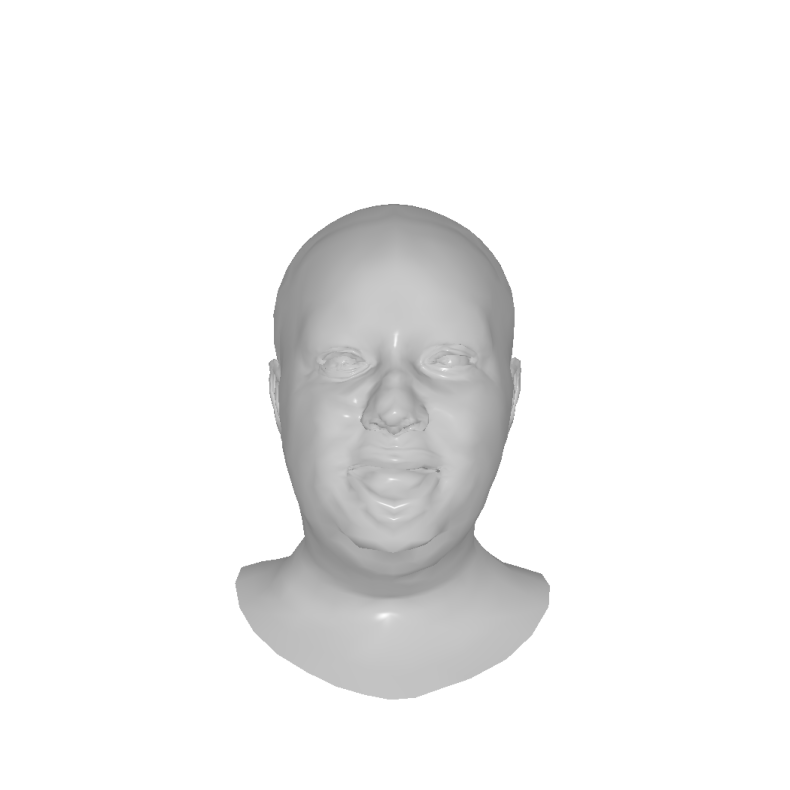

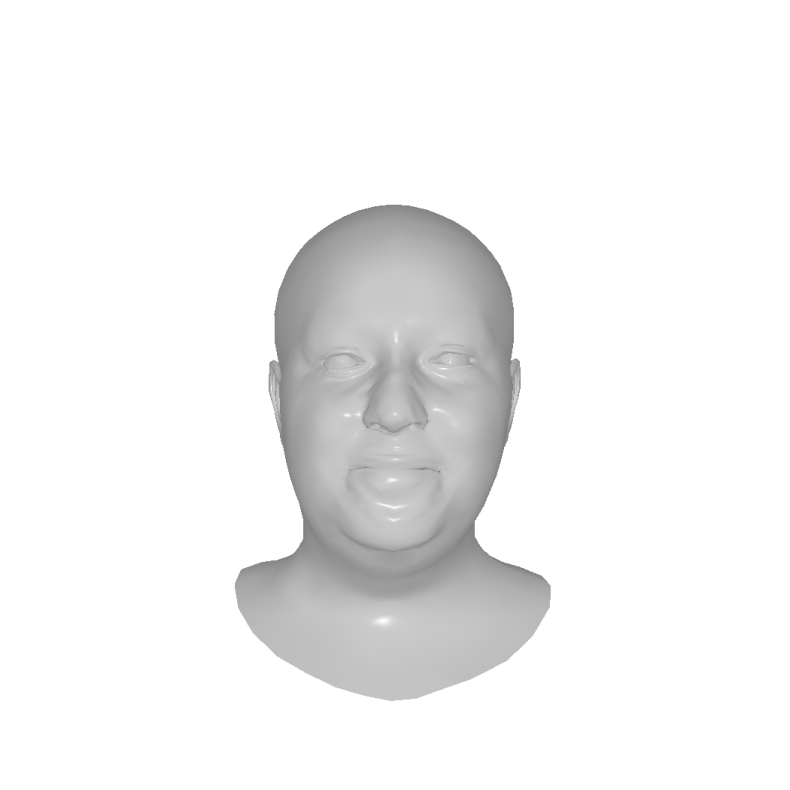

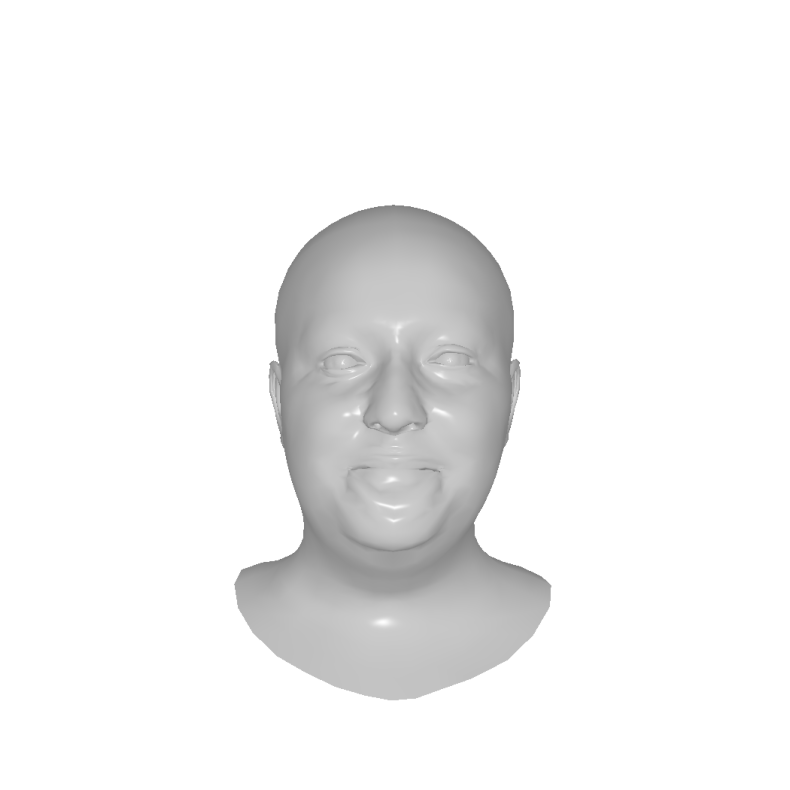

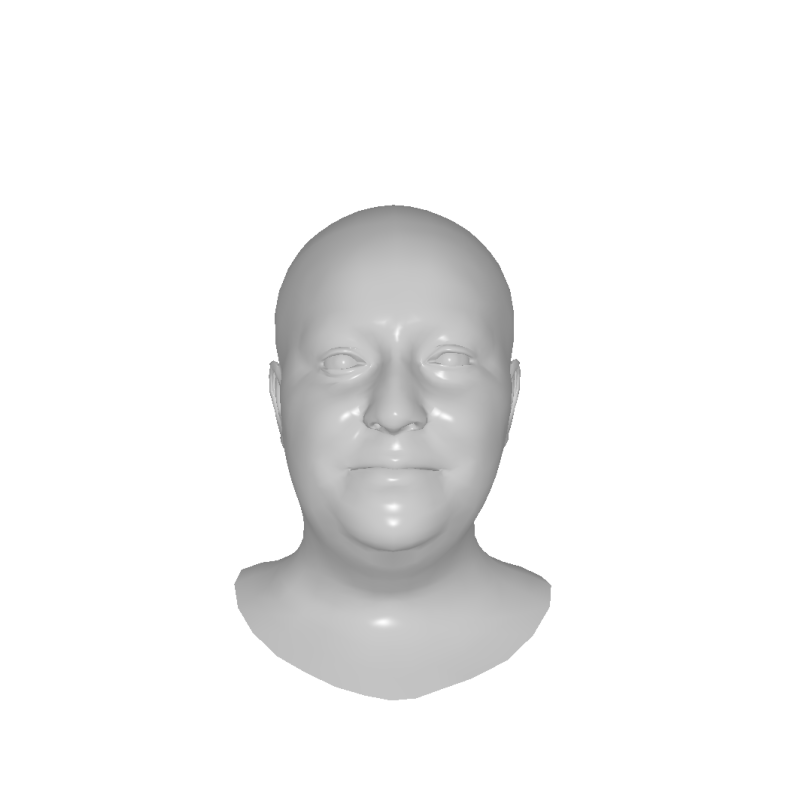

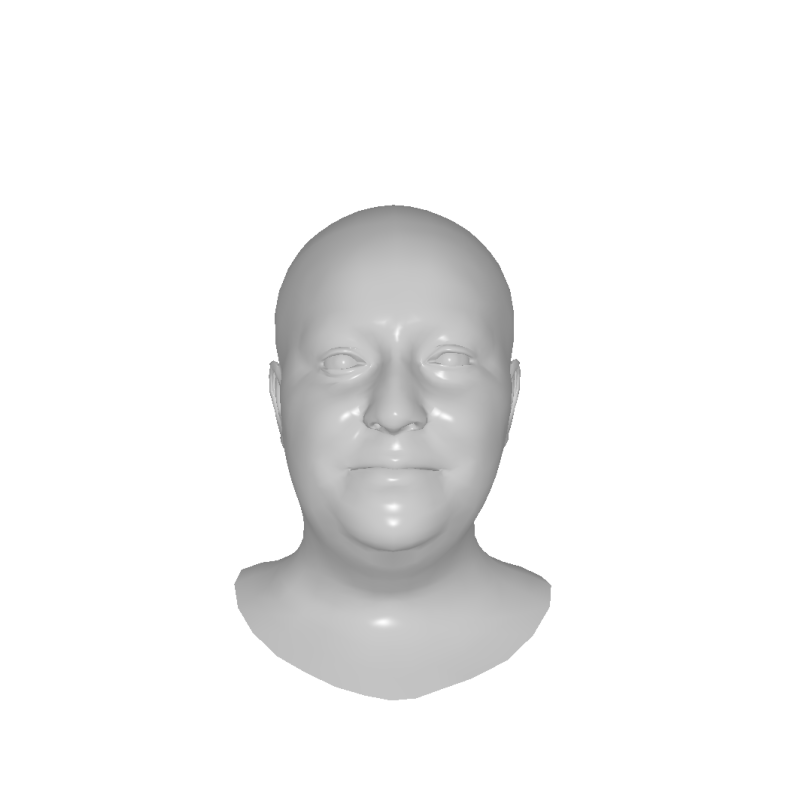

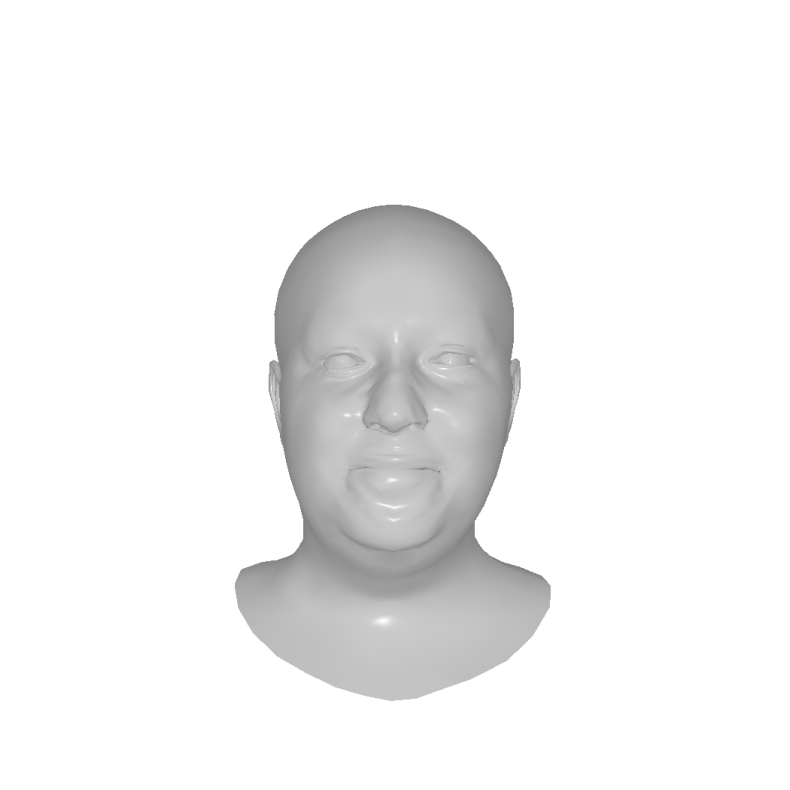

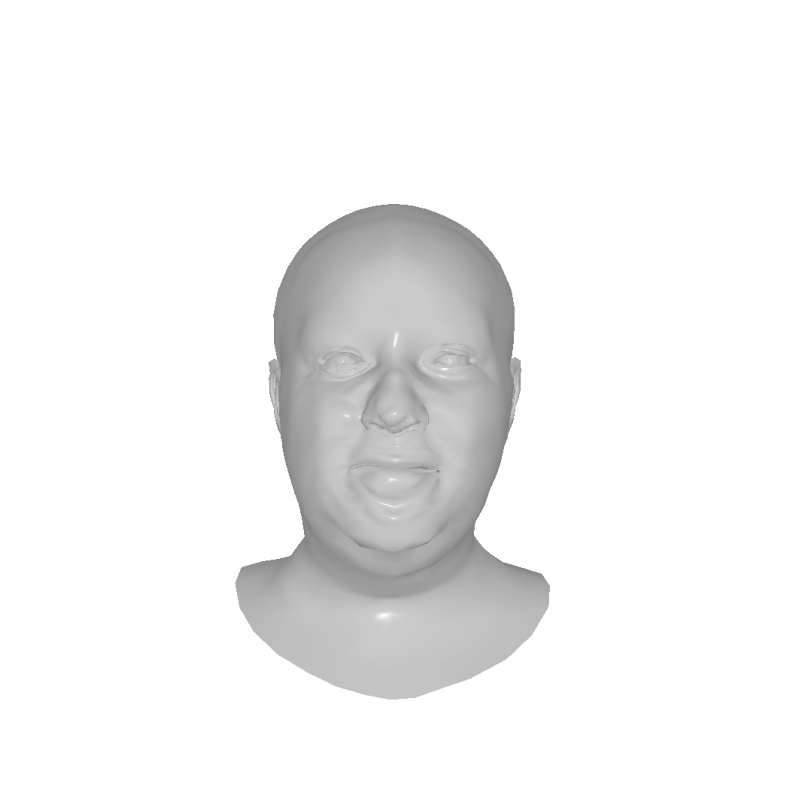

In [51]:
print_lowest_loss_faces(meshes ,all_single_losses, all_losses, target_mesh, N=1, render_mode=1,points=1000)

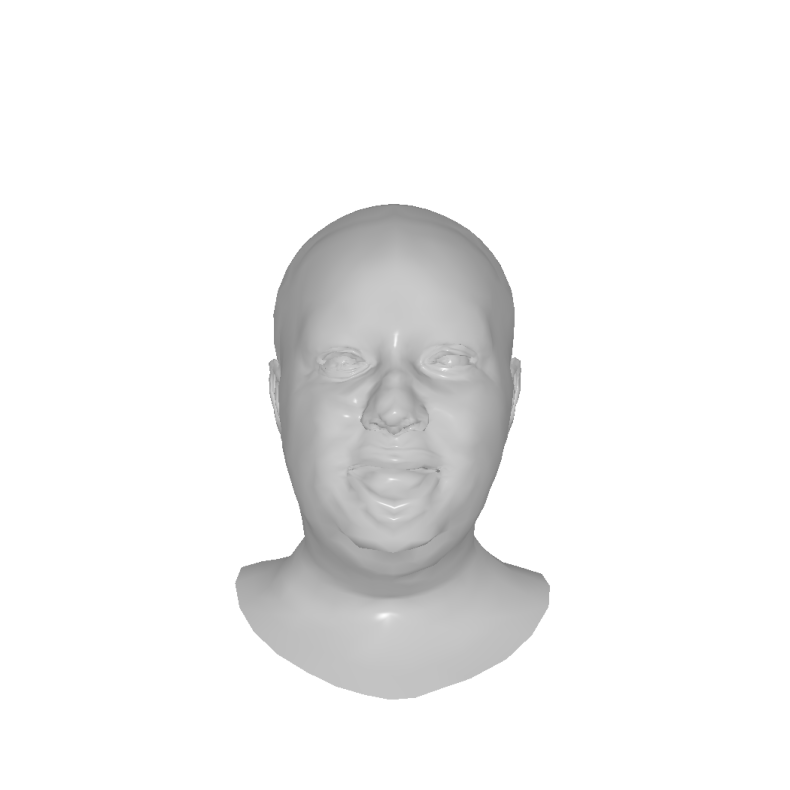

In [52]:
renderer = NormalRenderer()
image=renderer.Shot(meshes[-1], 0, 0, 2, 0).squeeze(0)
renderer.Stamp()

<Figure size 900x900 with 0 Axes>

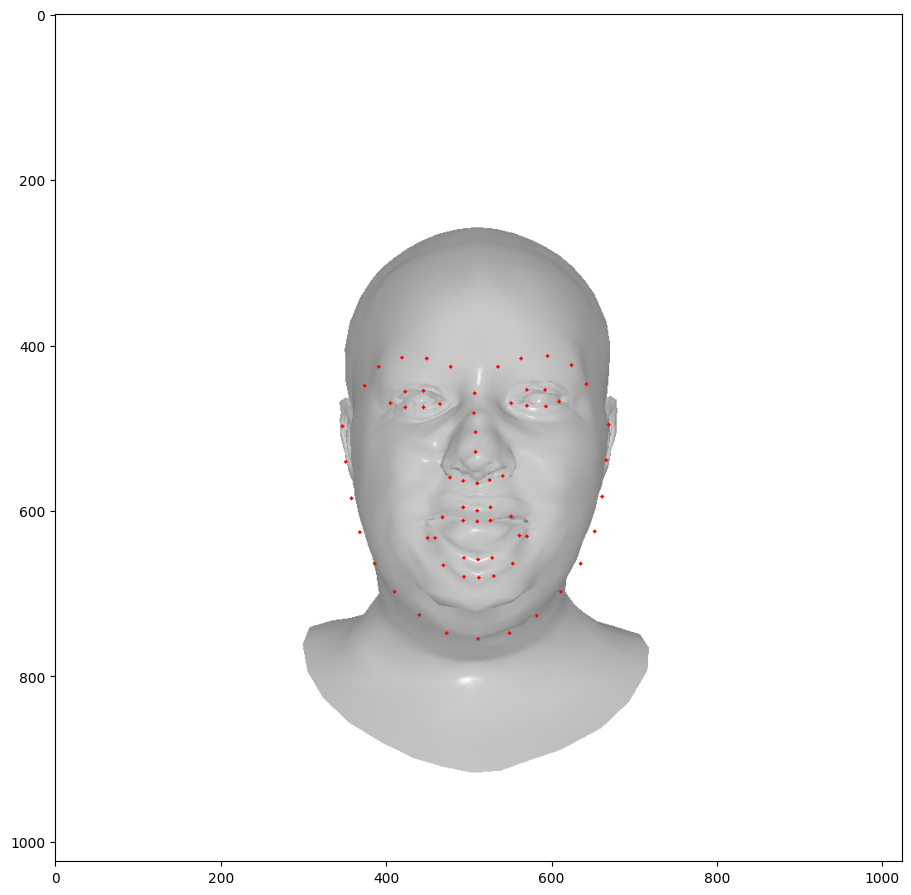

In [53]:
landmarks_given_image(image)

#EFE training pipeline for Py3D

In [54]:
meshes=[]
all_losses = []
all_single_losses = []

In [55]:
num_vertices = src_mesh.verts_packed().shape[0]                                 # Number of vertices in the source mesh

resize=1                                                                        # If 1 meshes are resized and normalized

Niter=[700,700,700]                                                               # Number of iterations
lr=[1e-5,1e-5,1e-5]                                                             # Learning rate

w_mse = [0,10000,0]                                                         # Weight for mean square error loss
w_reg = [1000,100,1000]                                                               # Weight for regularization term on magnitude of displacement
w_spars = [0,0,0]                                                               # Weight for regularization term on magnitude of mask                                                      #weight for regularization term on magnitude of mask
w_landmarks = [0.1,0,0.1]                                                         # Weight for landmark loss
w_landmarks_relative =[0,0,0]                                                   # Weight for relative landmark loss
w_edge = [0,0,0]                                                                # Edge loss
w_laplacian =[0,0,0]                                                            # Laplacian loss
w_normal = [0,0,0]                                                              # Normal loss
w_perceptual= [0,0.1,0]                                                       # Perceptual loss computed with VGG

indices=[0,1,0]

points=10000

sample_trg = sample_points_from_meshes(target_mesh,points)

  0%|          | 0/700 [00:00<?, ?it/s]

Chamfer distance: 0.03146469220519066
Hausdorff distance: 0.1388944536447525
Frobenius distance: 0.8526083827018738
Earth Mover's Distance: 0.03221261291503906


  0%|          | 0/700 [00:00<?, ?it/s]

Chamfer distance: 0.03137998655438423
Hausdorff distance: 0.13445456326007843
Frobenius distance: 0.857584536075592
Earth Mover's Distance: 0.031078439331054687


  0%|          | 0/700 [00:00<?, ?it/s]

Chamfer distance: 0.031960781663656235
Hausdorff distance: 0.1310911327600479
Frobenius distance: 0.8527472615242004
Earth Mover's Distance: 0.037908566284179684


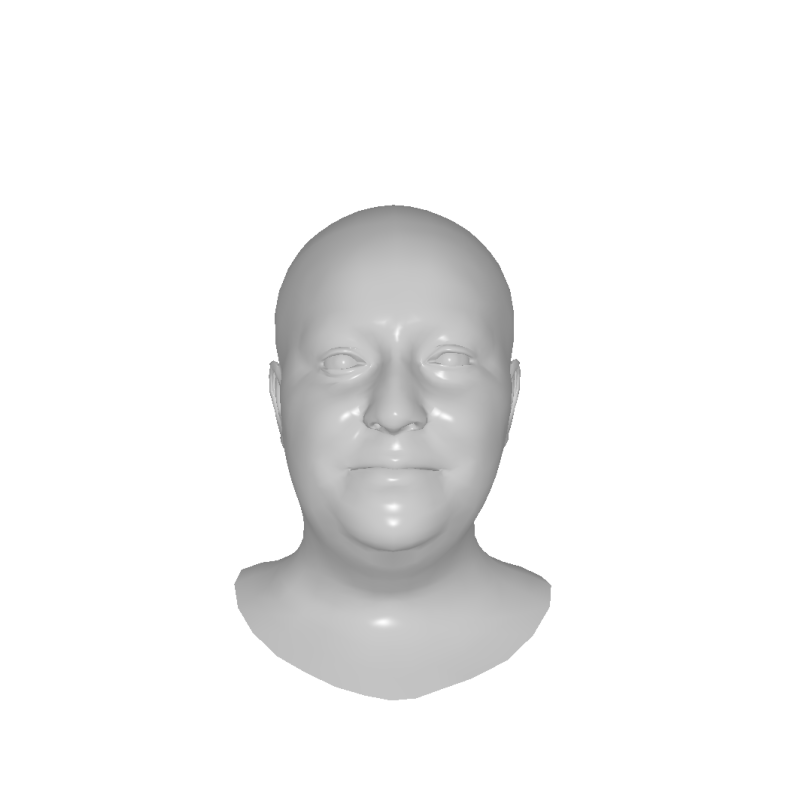

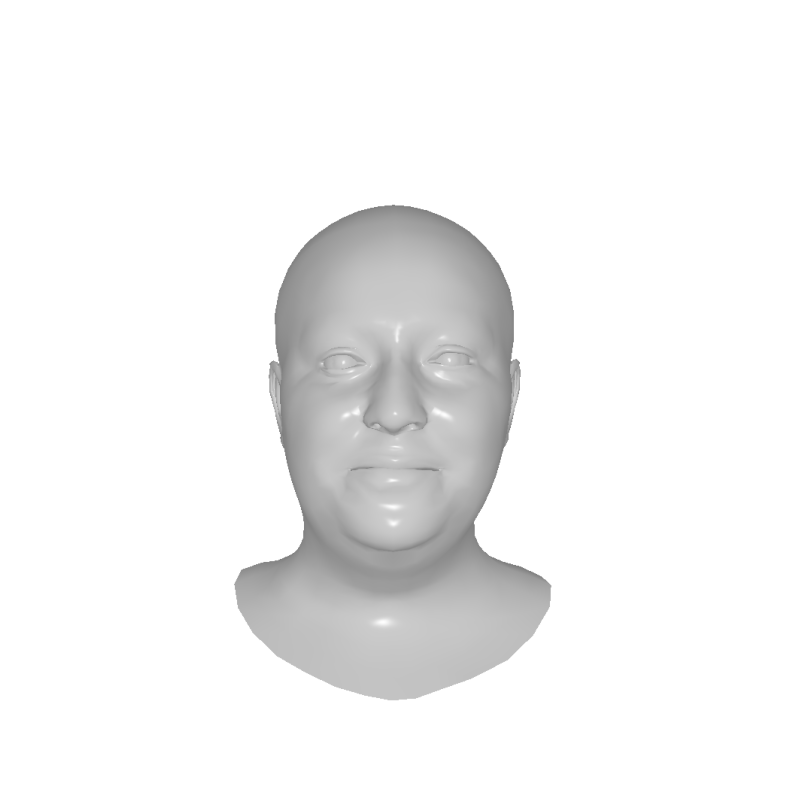

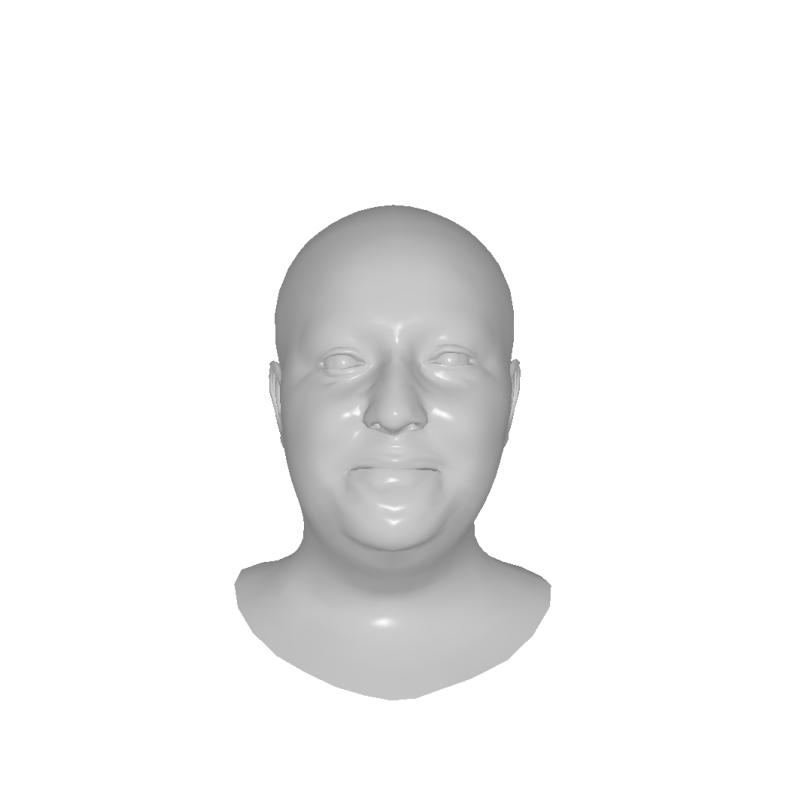

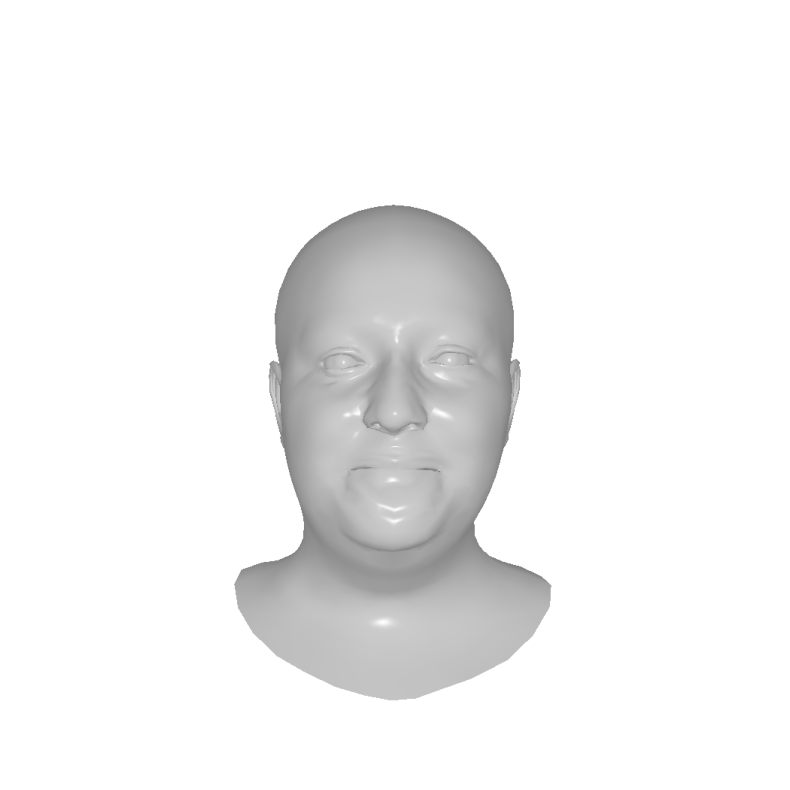

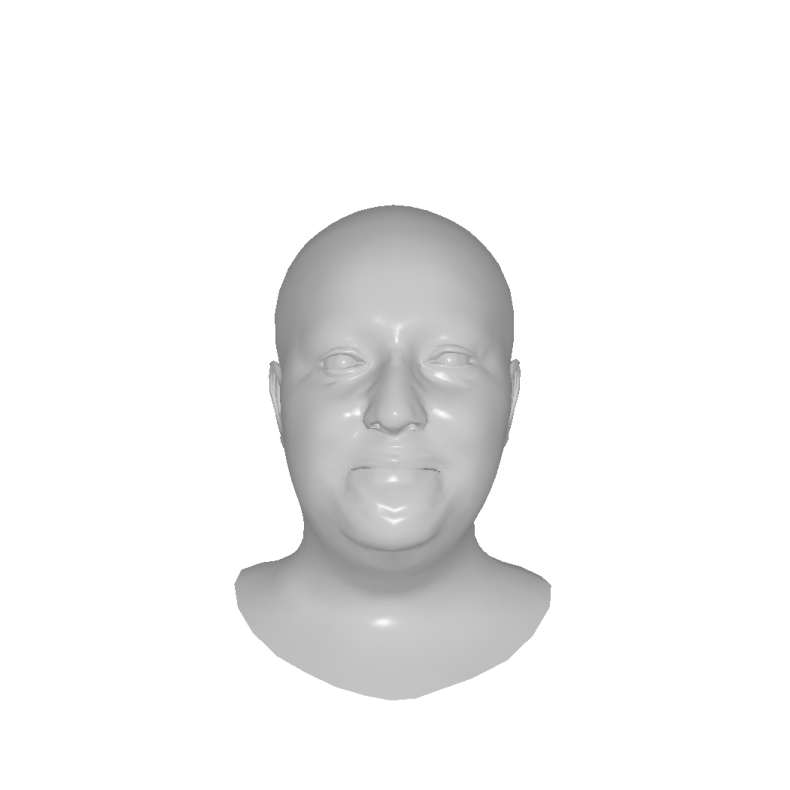

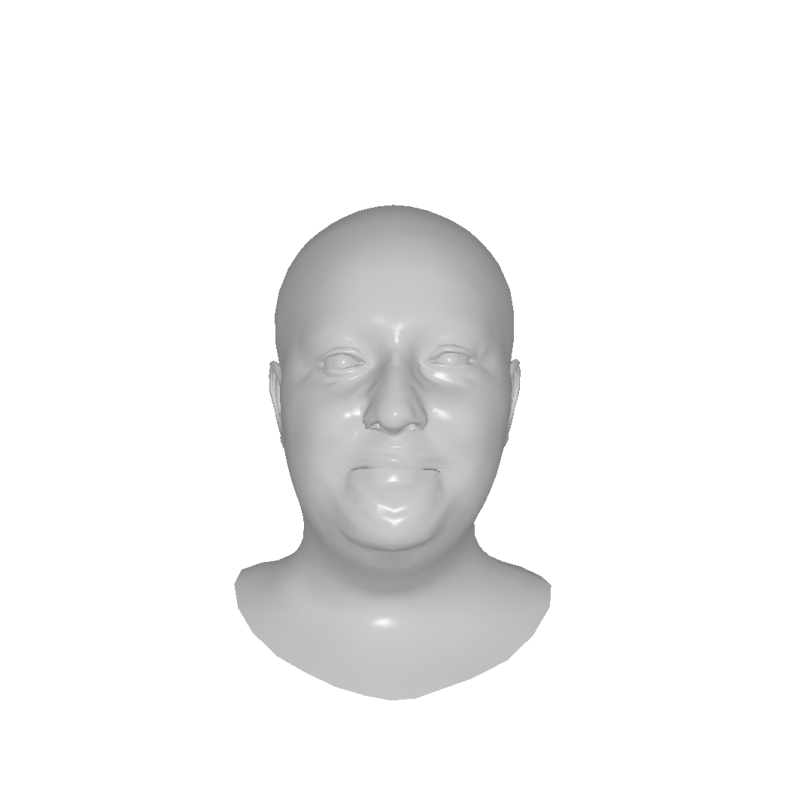

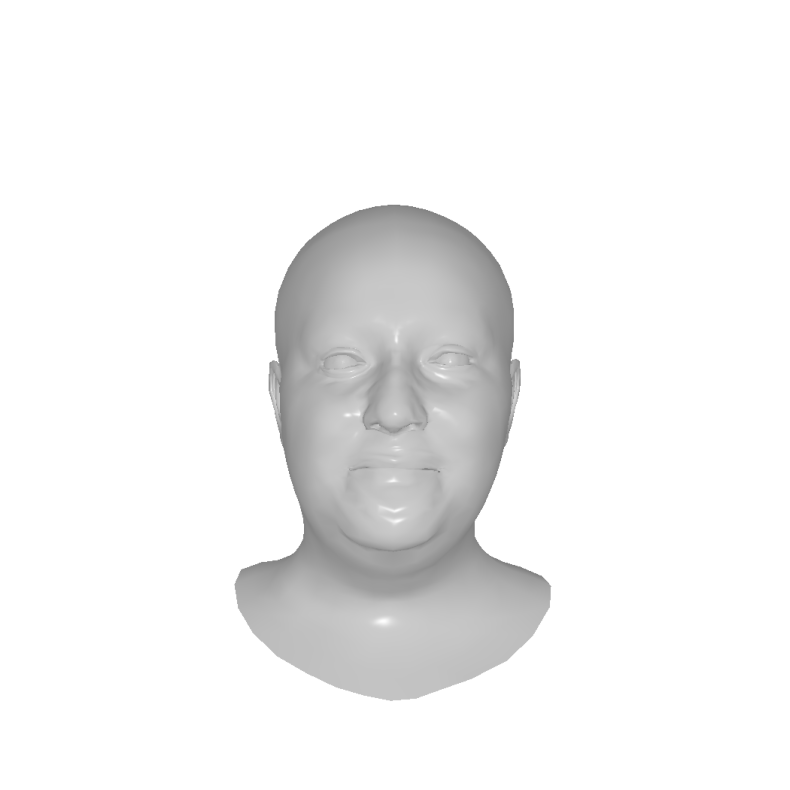

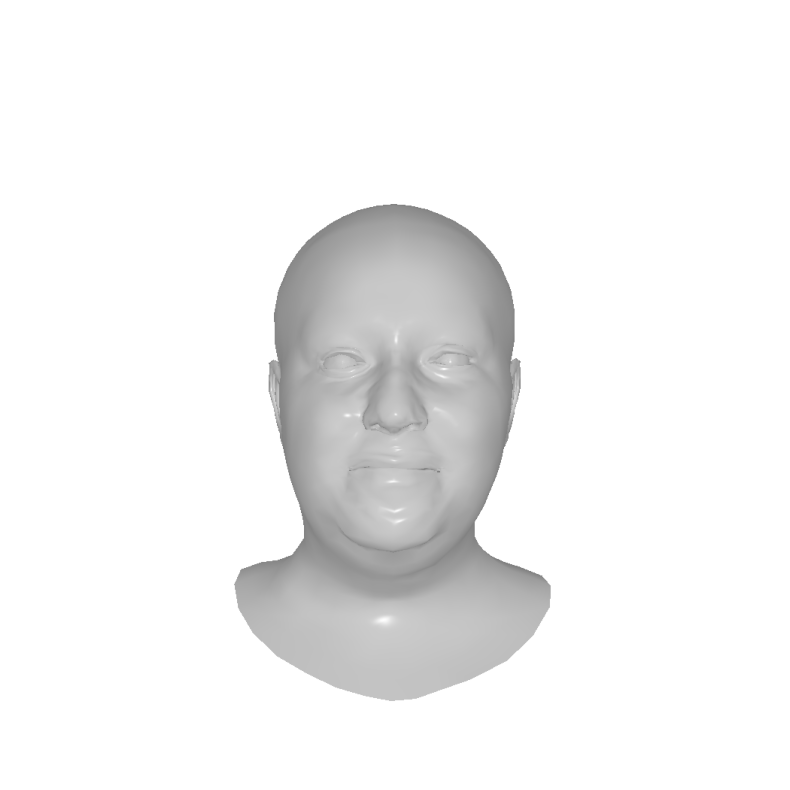

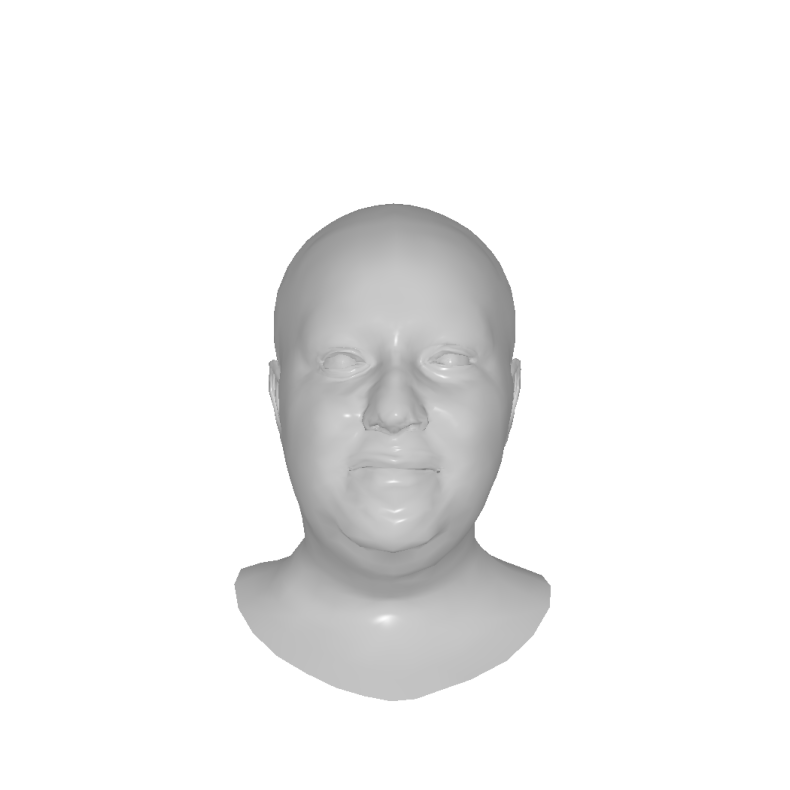

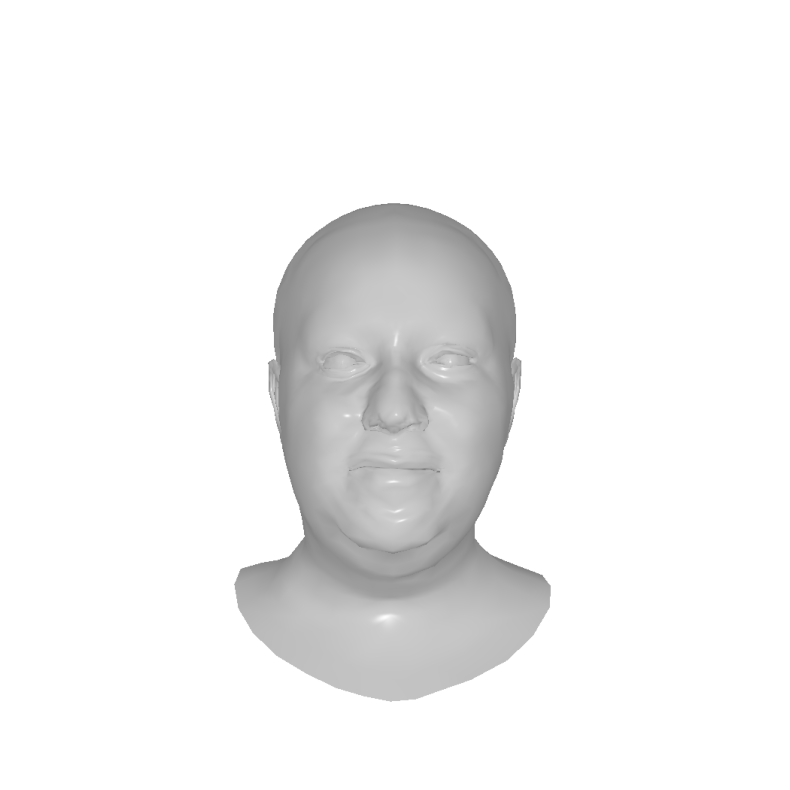

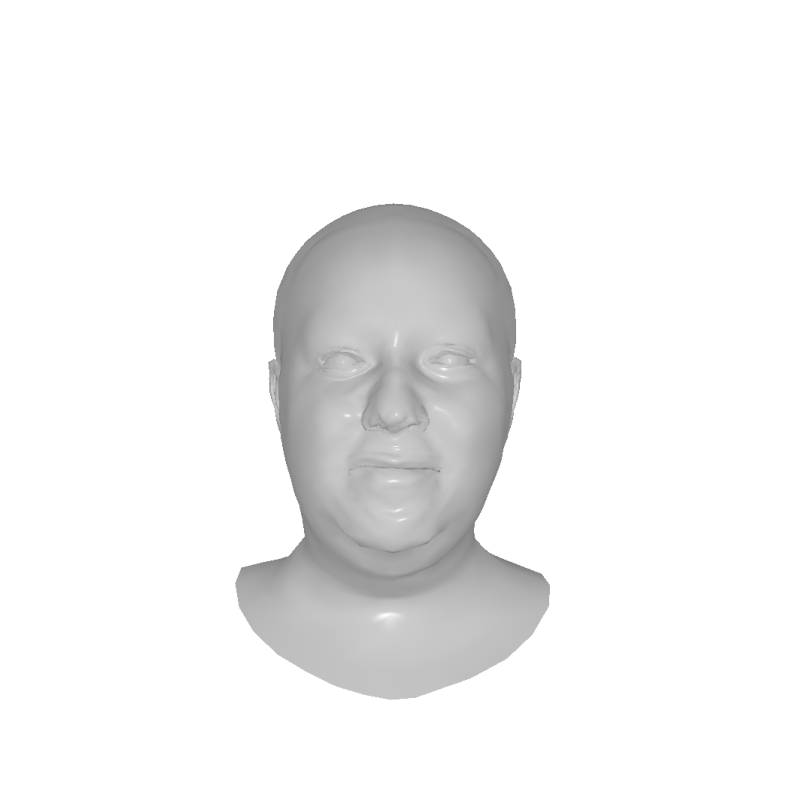

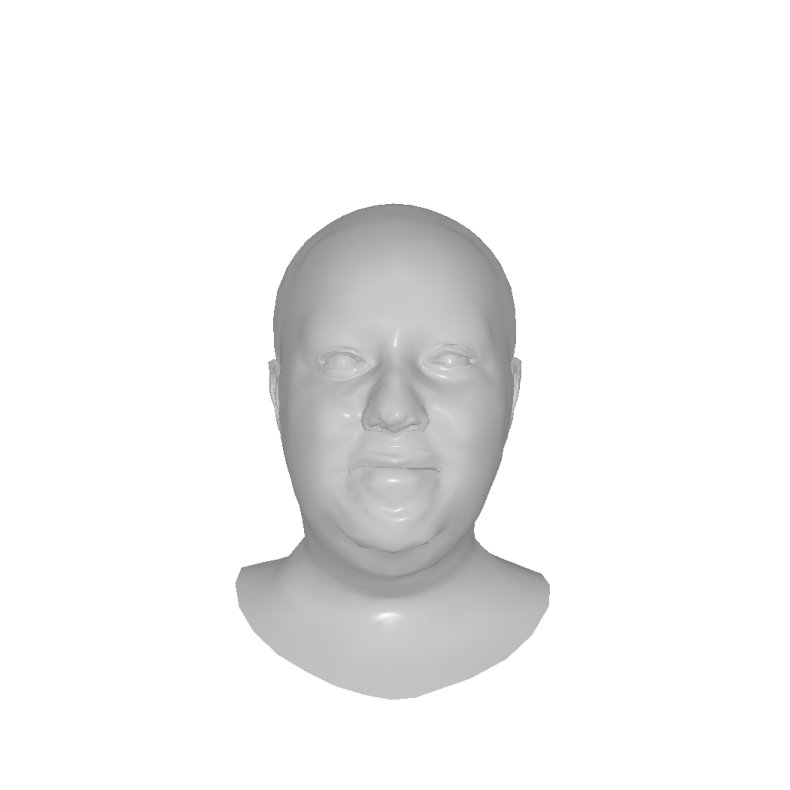

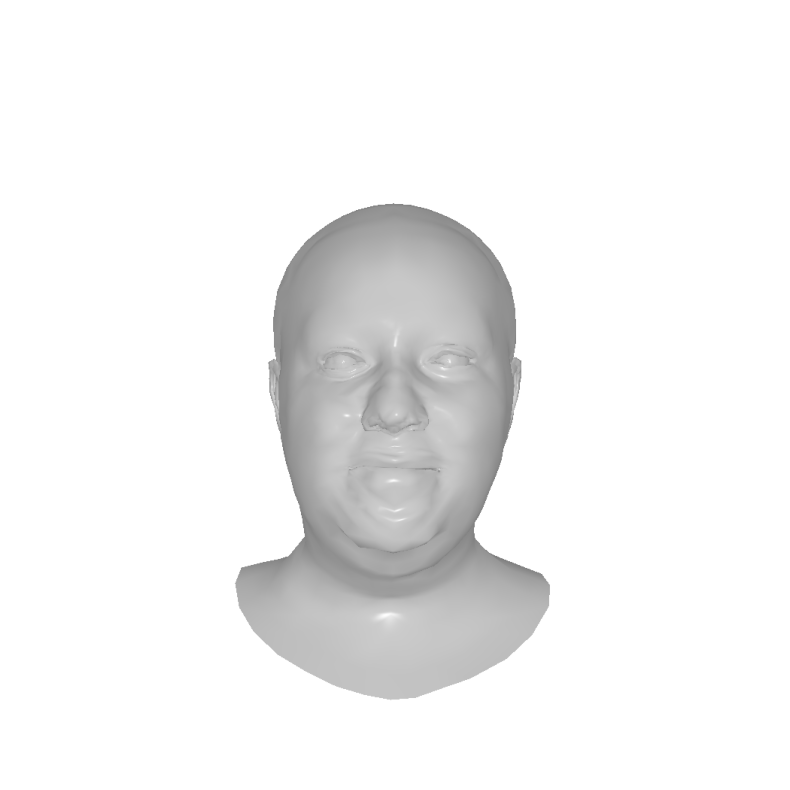

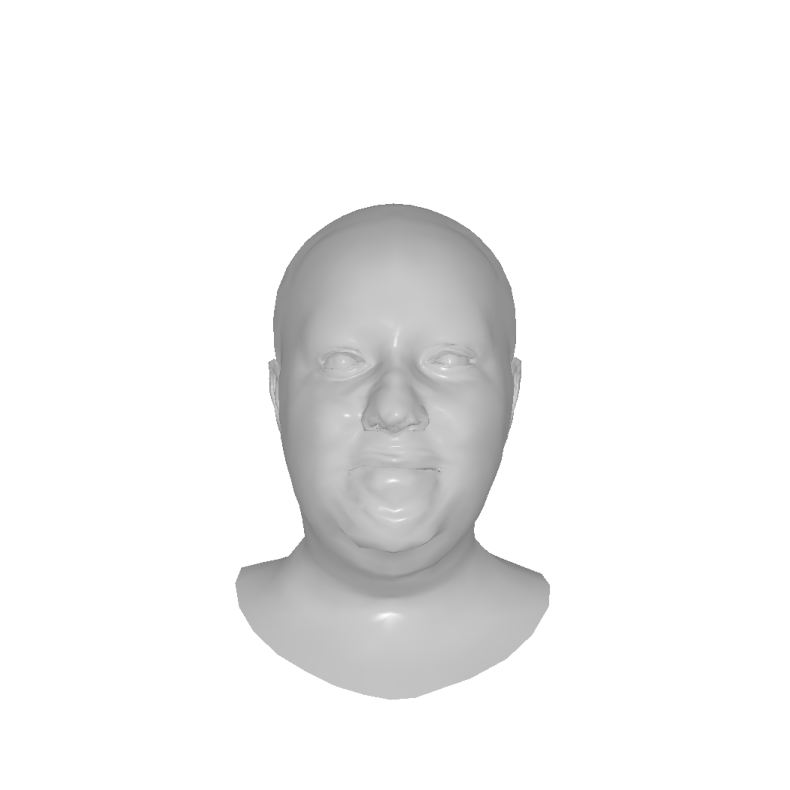

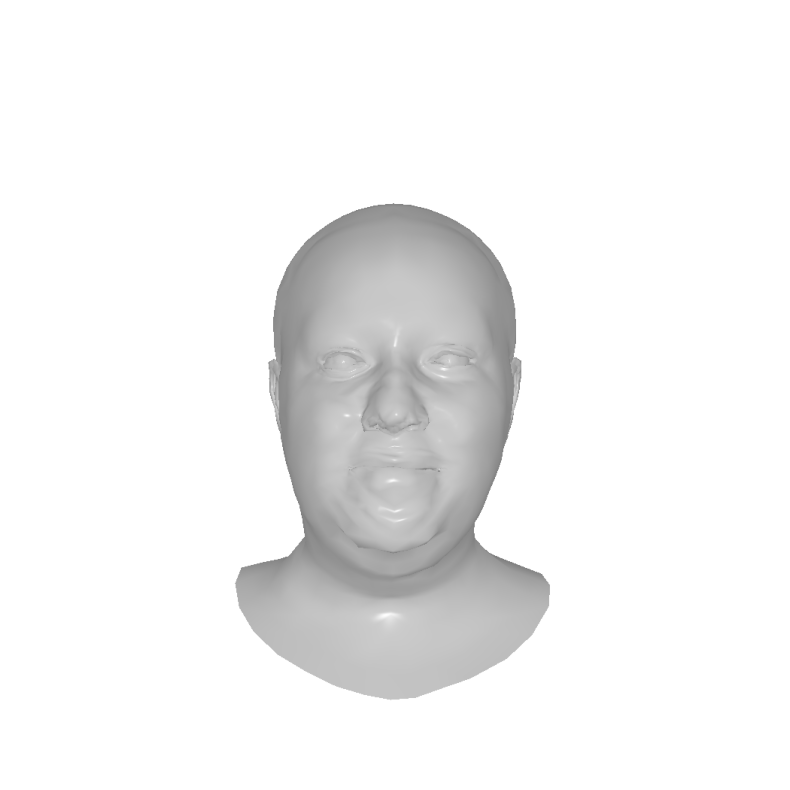

In [56]:
start_index=0
current_len=0
for i in range(len(indices)):

  if i >= start_index:
    if i == 0:
        starting_mesh = src_mesh.clone()
    else:
        # Get the last mesh from the previous network
        starting_mesh = meshes[current_len - 1].clone()

    loss,mesh,single_loss=train_py3D(src_mesh=starting_mesh, Niter=Niter[i], wd=1e-5, lr=lr[i], resize=1,  w_mse=w_mse[i], w_reg=w_reg[i], w_spars= w_spars[i],  w_landmarks=w_landmarks[i], w_landmarks_relative=w_landmarks_relative[i], w_perceptual=w_perceptual[i],  w_edge=w_edge[i], w_laplacian=w_laplacian[i], w_normal=w_normal[i])

    #appending meshes losses computed so far
    meshes[current_len:] = mesh
    all_losses[current_len:]=loss
    all_single_losses[current_len:]=single_loss

    current_len+=Niter[i]

    sample_src = sample_points_from_meshes(mesh[-1],points)

    chamfer_dist, hausdorff_dist, frobenius_dist, emd = evaluation_metrics(sample_src, sample_trg,points)
    print(f"Chamfer distance: {chamfer_dist}")
    print(f"Hausdorff distance: {hausdorff_dist}")
    print(f"Frobenius distance: {frobenius_dist}")
    print(f"Earth Mover's Distance: {emd}")

# Visualize source and target meshes

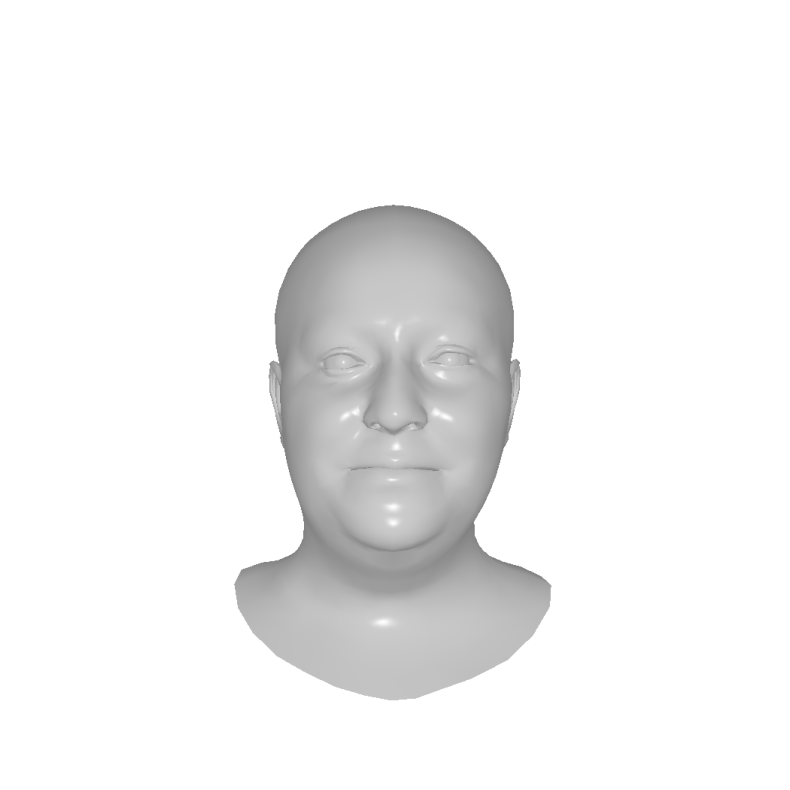

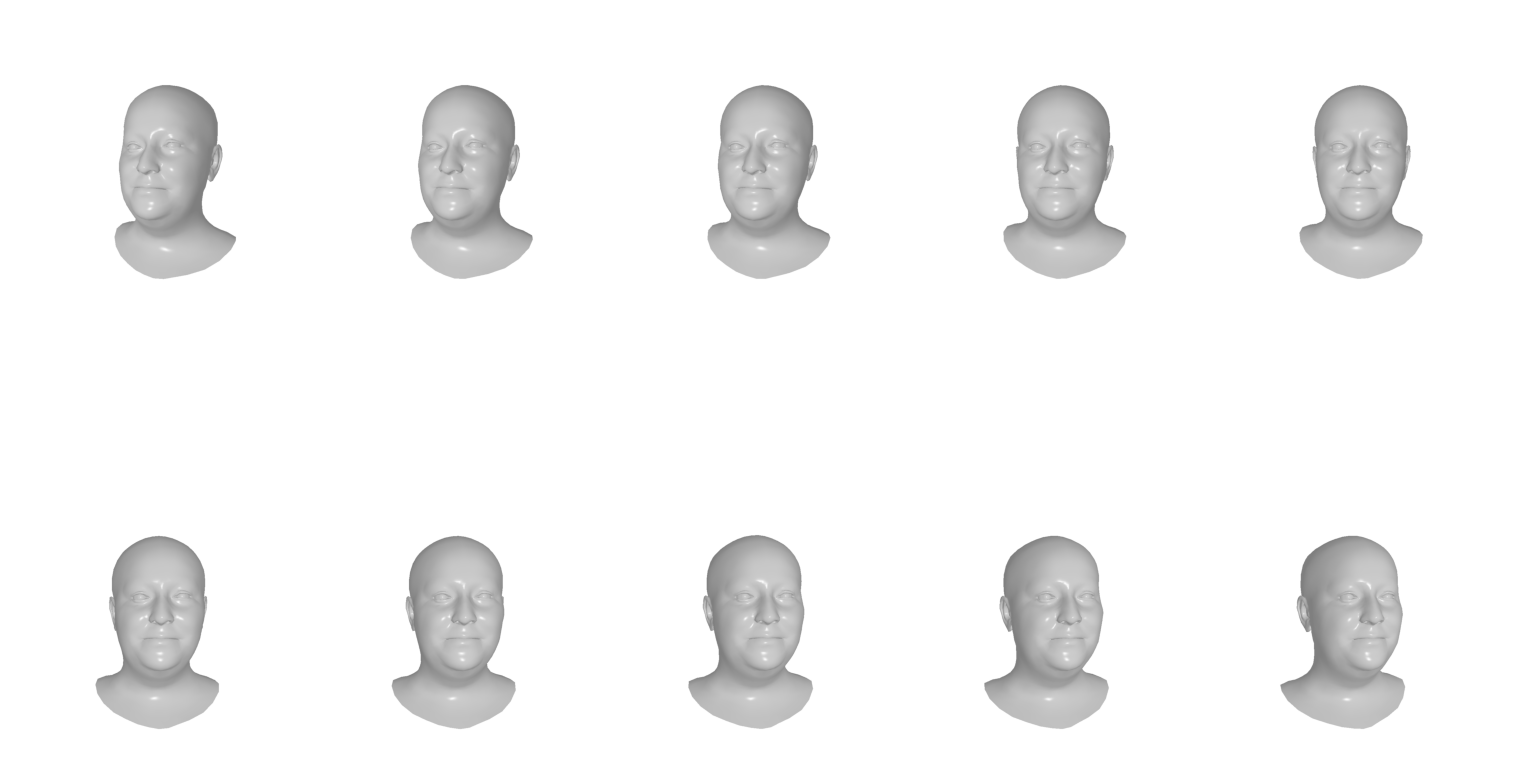

In [ ]:
'''
  render mode:
    #1 prints the face only frontally,
    #2 only multiview images,
    #3 both
'''
render_mode= 3

test_renderer=NormalRenderer()
if render_mode==1 or render_mode==3:
  image_prova=test_renderer.Shot(src_mesh,0,0,2,0)
  test_renderer.Stamp()
if render_mode==2 or render_mode==3:
  images_prova=test_renderer.Multiple_Shot(src_mesh)
  test_renderer.Multiple_Stamp()

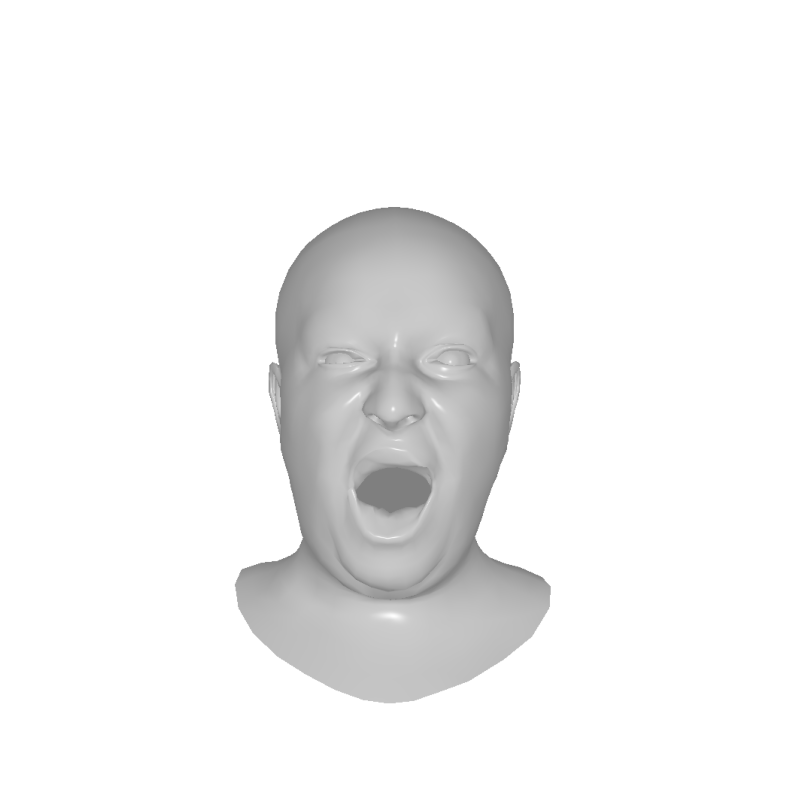

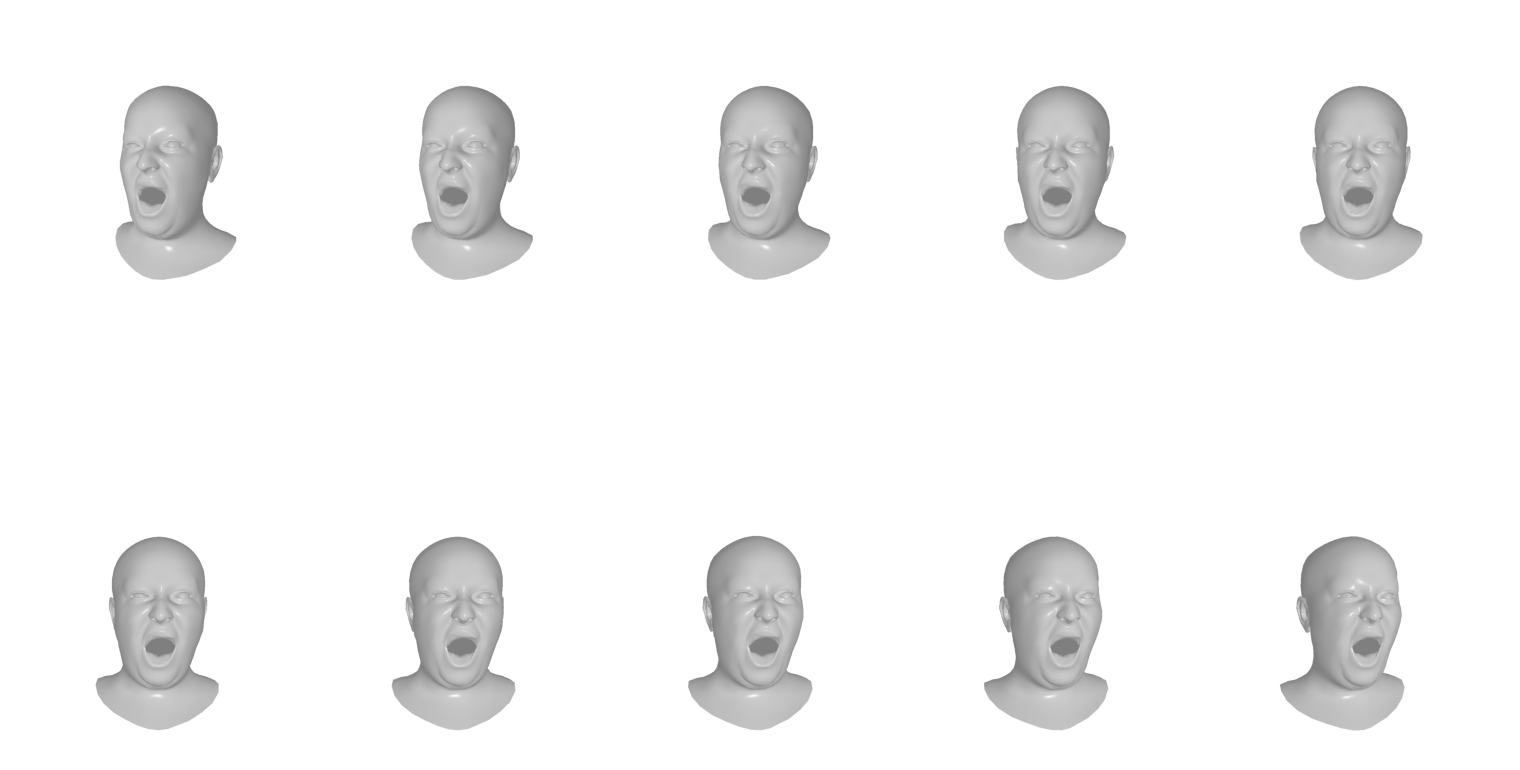

In [ ]:
test_render=NormalRenderer()
if render_mode==1 or render_mode==3:
  image_prova=test_render.Shot(target_mesh,0,0,2,0)
  test_render.Stamp()
if render_mode==3 or render_mode==3:
  images_prova=test_render.Multiple_Shot(target_mesh)
  test_render.Multiple_Stamp()